In [34]:
# ===================== USER SETTINGS =====================

# Copernicus CDS credentials (put your own (βάλε τα δικά σου))  [EN translation pending]
URL = "https://cds.climate.copernicus.eu/api"
KEY = "4cbb8023-306b-4294-9fe2-b968cf7f5c81"  ### put here your key!!!

# Bounding box (lat/lon)
LAT_MIN, LAT_MAX = 37.92, 38.05 #42.5
LON_MIN, LON_MAX = 23.62, 23.75 #30.2

# Years loop (it will download [year, year+1] as in your original setup (θα κατεβάσει [year, year+1] όπως στο αρχικό σου))  [EN translation pending]

START_YEAR = 2005
END_YEAR = 2007

# Optional additional future periods
FUTURE_PERIODS = [
    {"period": "P1", "start": START_YEAR, "end": END_YEAR},
]

INCLUDE_HISTORICAL = False
HIST_START_YEAR = 1980
HIST_END_YEAR = 2004
STEP       = 5
# Testing: download only January and February.
# For the full dataset, use all 12 months. ["01", "02"]
DOWNLOAD_MONTHS = ["01","02","03","04","05","06","07", "08", "09", "10", "11", "12"]

# CDS dataset + request parameters (defaults from your original (από το δικό σου))  [EN translation pending]
DATASET   = "projections-cordex-domains-single-levels"
DOMAIN    = "europe"

# Climate scenario selection
# Options:
# ["rcp_4.5"]              -> RCP 4.5 only
# ["rcp_8.5"]              -> RCP 8.5 only
# ["rcp_4.5", "rcp_8.5"]   -> Both scenarios

SELECTED_SCENARIOS = ["rcp_4.5", "rcp_8.5"]

SCENARIOS = {
    "rcp_4.5": {
        "experiment": "rcp_4_5",
        "out_dir": "output_cropped_rcp_4.5",
        "work_dir": "_tmp_download_rcp_4.5",
    },
    "rcp_8.5": {
        "experiment": "rcp_8_5",
        "out_dir": "output_cropped_rcp_8.5",
        "work_dir": "_tmp_download_rcp_8.5",
    },
}

# Validate scenario selection
if not SELECTED_SCENARIOS:
    raise ValueError("Select at least one climate scenario.")

invalid_scenarios = set(SELECTED_SCENARIOS) - set(SCENARIOS)
if invalid_scenarios:
    raise ValueError(
        f"Invalid scenarios: {invalid_scenarios}. "
        f"Choose from {list(SCENARIOS)}."
    )

RESOLUTION= "0_11_degree_x_0_11_degree"
TEMPORAL  = "daily_mean" #"3_hours"
GCM       = "ichec_ec_earth"#"cnrm_cerfacs_cm5"
RCM       = "knmi_racmo22e" #"cnrm_aladin63"
ENSEMBLE  = "r1i1p1"
CDS_VARIABLES = [
    "10m_wind_speed",
    "2m_air_temperature",
    "2m_relative_humidity",
    "minimum_2m_temperature_in_the_last_24_hours",
    "maximum_2m_temperature_in_the_last_24_hours",
    "mean_precipitation_flux",
    "surface_solar_radiation_downwards",
]


# Folders (Φάκελοι)  [EN translation pending]
OUT_DIR  = "output_cropped_rcp_8.5"
WORK_DIR = "_tmp_download"

# Cleanup (Καθαρισμός)  [EN translation pending]
DELETE_ORIGINAL_NC = False
KEEP_ZIP = False
# If you want intermediate cropped files to be deleted after merge (Αν θέλεις να σβήνονται τα ενδιάμεσα cropped αρχεία μετά το merge)  [EN translation pending]
DELETE_INTERMEDIATE_CROPPED = True

In [35]:
# ===================== CELL 2 (JUPYTER) - CLEAN / SAME LOGIC =====================
# - DOES NOT use NC_VAR (ΔΕΝ χρησιμοποιεί NC_VAR)  [EN translation pending]
# - Unzip σε ξεχωριστό φάκελο ανά request  [EN translation pending]
# - Selects the "main" nc (data_var with time) (Επιλέγει "κύριο" nc (data_var με time))  [EN translation pending]
# - Selects the CORRECT main variable: time + spatial dimensions (grid dims) (Επιλέγει ΣΩΣΤΗ κύρια μεταβλητή: time + χωρικές διαστάσεις (grid dims))  [EN translation pending]
# - Crop with lat/lon (1D or 2D rotated -> points) (Crop με lat/lon (1D ή 2D rotated -> points))  [EN translation pending]
# - FIX: stack(create_index=False) για rotated dims χωρίς rlat coord  [EN translation pending]
# - Writes compressed NetCDF (Γράφει compressed NetCDF)  [EN translation pending]
# - Automatically finds which 5-year block contains START_YEAR and END_YEAR (Βρίσκει αυτόματα ποια 5ετία περιέχει το START_YEAR και το END_YEAR)  [EN translation pending]
# - If the bbox is too small and contains no grid point, it picks the nearest point (Αν το bbox είναι πολύ μικρό και δεν περιέχει grid point, παίρνει το κοντινότερο σημείο)  [EN translation pending]

import zipfile
from pathlib import Path

import numpy as np
import xarray as xr
import cdsapi
import requests


def _require(name: str):
    if name not in globals():
        raise RuntimeError(f"Missing variable (Λείπει η μεταβλητή): {name}. Run/set CELL 1 correctly (Τρέξε/όρισε σωστά το CELL 1).")
    if globals()[name] == "":
        raise RuntimeError(f"The variable (Η μεταβλητή) {name} is empty (''). Provide a value in CELL 1 (είναι κενή (''). Δώσε τιμή στο CELL 1).")
    return globals()[name]


def ensure_dir(p):
    p = Path(p)
    p.mkdir(parents=True, exist_ok=True)
    return p


def unzip_all(zip_path: Path, extract_dir: Path) -> list[Path]:
    extract_dir.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(zip_path, "r") as z:
        z.extractall(extract_dir)

    nc_files = sorted(extract_dir.rglob("*.nc"))
    if not nc_files:
        raise FileNotFoundError(f"No .nc file found inside zip (Δεν βρέθηκε .nc μέσα στο zip): {zip_path}")
    return nc_files


def _is_aux_name(p: Path) -> bool:
    n = p.name.lower()
    bad_tokens = ["bounds", "bnds", "vertices", "vertex", "grid", "fx"]
    return any(t in n for t in bad_tokens)


def pick_main_nc(nc_files: list[Path]) -> Path:
    ignore_vars = {
        "bounds_lon", "bounds_lat", "lon_bnds", "lat_bnds", "bnds",
        "lat", "lon", "time", "rlat", "rlon",
        "rotated_pole", "rotated_latitude_longitude", "crs"
    }

    candidates = []
    for f in nc_files:
        if _is_aux_name(f):
            continue
        try:
            with xr.open_dataset(f, decode_times=False) as ds0:
                good = []
                for v in ds0.data_vars:
                    if v in ignore_vars:
                        continue
                    if "time" in ds0[v].dims:
                        good.append(v)
                if good:
                    candidates.append(f)
        except Exception:
            pass

    if candidates:
        return max(candidates, key=lambda p: p.stat().st_size)

    return max(nc_files, key=lambda p: p.stat().st_size)


def find_lat_lon_names(ds: xr.Dataset):
    possible_lat = ["lat", "latitude", "nav_lat"]
    possible_lon = ["lon", "longitude", "nav_lon"]

    lat_name = next((n for n in possible_lat if n in ds.variables), None)
    lon_name = next((n for n in possible_lon if n in ds.variables), None)

    if not lat_name or not lon_name:
        raise KeyError(f"Could not find lat/lon. First vars (Δεν βρήκα lat/lon. Πρώτα vars): {list(ds.variables)[:40]}")

    return lat_name, lon_name


def pick_main_data_var(ds: xr.Dataset, lat: xr.DataArray, lon: xr.DataArray) -> str:
    """
    Selects a main variable that (Διαλέγει κύρια μεταβλητή που):
    - has time (έχει time)
    - also has the lat/lon grid dims (e.g., rlat/rlon or lat/lon) (έχει και τις grid dims του lat/lon (π.χ. rlat/rlon ή lat/lon))
    Avoids bounds/bnds (Αποφεύγει bounds/bnds).
    """
    ignore = {
        "bounds_lon", "bounds_lat", "lon_bnds", "lat_bnds", "bnds",
        "lon", "lat", "time", "height",
        "rlon", "rlat",
        "rotated_pole", "rotated_latitude_longitude",
        "crs"
    }

    grid_dims = tuple(lat.dims)
    cand = []

    for v in ds.data_vars:
        if v in ignore:
            continue
        dims = ds[v].dims
        if "time" not in dims:
            continue
        if all(d in dims for d in grid_dims):
            cand.append(v)

    if cand:
        return cand[0]

    time_vars = [v for v in ds.data_vars if v not in ignore and "time" in ds[v].dims]
    raise ValueError(
        "No main variable found with (time + grid dims). (Δεν βρέθηκε κύρια μεταβλητή με (time + grid dims).)\n"
        f"grid_dims(lat)={grid_dims}\n"
        f"Candidates with time (Υποψήφιες με time): {time_vars}\n"
        f"All data_vars (Όλες οι data_vars): {list(ds.data_vars)}"
    )


def crop_to_bbox(
    ds: xr.Dataset,
    varname: str,
    lat_min: float,
    lat_max: float,
    lon_min: float,
    lon_max: float
) -> xr.Dataset:
    lat_name, lon_name = find_lat_lon_names(ds)
    lat = ds[lat_name]
    lon = ds[lon_name]
    da = ds[varname]

    # ---- Case 1: 1D lat/lon ----
    if lat.ndim == 1 and lon.ndim == 1:
        def _slice_1d(coord, vmin, vmax):
            c0 = float(coord.values[0])
            c1 = float(coord.values[-1])
            return slice(vmin, vmax) if c0 <= c1 else slice(vmax, vmin)

        cut = da.sel({
            lat_name: _slice_1d(lat, lat_min, lat_max),
            lon_name: _slice_1d(lon, lon_min, lon_max)
        })

        # If the bbox matched nothing, take nearest point to bbox center (Αν το bbox δεν έπιασε τίποτα, πάρε nearest point στο κέντρο του bbox)  [EN translation pending]
        if cut.size == 0:
            target_lat = (lat_min + lat_max) / 2.0
            target_lon = (lon_min + lon_max) / 2.0

            lat_idx = int(np.abs(lat.values - target_lat).argmin())
            lon_idx = int(np.abs(lon.values - target_lon).argmin())

            cut = da.isel({
                lat_name: slice(lat_idx, lat_idx + 1),
                lon_name: slice(lon_idx, lon_idx + 1)
            })

            print(
                f"⚠️  Το bbox δεν περιείχε grid point. "
                f"Χρησιμοποιείται το κοντινότερο σημείο στο κέντρο του bbox: "
                f"lat={float(lat.values[lat_idx]):.6f}, lon={float(lon.values[lon_idx]):.6f}"
            )

        return cut.to_dataset(name=varname)

    # ---- Case 2: 2D lat/lon (rotated grid) ----
    grid_dims = lat.dims

    if lon.dims != grid_dims:
        raise ValueError(f"lat dims={lat.dims} αλλά lon dims={lon.dims} — δεν ταιριάζουν.")

    if not all(d in da.dims for d in grid_dims):
        raise ValueError(
            f"The variable (Η μεταβλητή) '{varname}' does not have the grid dims (δεν έχει τις grid dims) {grid_dims}.\n"
            f"var dims={da.dims}"
        )

    mask = (
        (lat >= lat_min) & (lat <= lat_max) &
        (lon >= lon_min) & (lon <= lon_max)
    )

    mask_stacked = mask.stack(points=grid_dims, create_index=False)
    keep = mask_stacked.compute().values.astype(bool)

    # Αν δεν βρέθηκε σημείο μέσα στο bbox, πάρε το nearest point στο κέντρο του bbox  [EN translation pending]
    if keep.sum() == 0:
        target_lat = (lat_min + lat_max) / 2.0
        target_lon = (lon_min + lon_max) / 2.0

        dist2 = (lat - target_lat) ** 2 + (lon - target_lon) ** 2
        dist2_stacked = dist2.stack(points=grid_dims, create_index=False)

        nearest_idx = int(np.argmin(dist2_stacked.values))
        keep = np.zeros(dist2_stacked.shape[0], dtype=bool)
        keep[nearest_idx] = True

        nearest_lat = float(
            lat.stack(points=grid_dims, create_index=False).isel(points=nearest_idx).values
        )
        nearest_lon = float(
            lon.stack(points=grid_dims, create_index=False).isel(points=nearest_idx).values
        )

        print(
            f"⚠️  Το bbox δεν περιείχε grid point. "
            f"Χρησιμοποιείται το κοντινότερο σημείο στο κέντρο του bbox: "
            f"lat={nearest_lat:.6f}, lon={nearest_lon:.6f}"
        )

    da_points = da.stack(points=grid_dims, create_index=False).isel(points=keep)
    lat_points = lat.stack(points=grid_dims, create_index=False).isel(points=keep)
    lon_points = lon.stack(points=grid_dims, create_index=False).isel(points=keep)

    n = int(keep.sum())
    out = xr.Dataset(
        data_vars={varname: da_points},
        coords={
            "points": np.arange(n),
            "lat": ("points", lat_points.values),
            "lon": ("points", lon_points.values),
        }
    )

    if "time" in ds.coords:
        out = out.assign_coords(time=ds["time"])

    return out


def build_cordex_request(start_year, end_year, variable, experiment):
    return {
        "domain": DOMAIN,
        "experiment": experiment,
        "horizontal_resolution": RESOLUTION,
        "temporal_resolution": TEMPORAL,
        "variable": [variable],
        "gcm_model": GCM,
        "rcm_model": RCM,
        "ensemble_member": ENSEMBLE,
        "year": [
            str(year)
            for year in range(start_year, end_year + 1)
        ],
        "month": DOWNLOAD_MONTHS,
    }


def request_exists(client, start_year: int, end_year: int) -> bool:
    """
    Checks whether a valid CDS request exists for the specific period (Ελέγχει αν υπάρχει valid request στο CDS για τη συγκεκριμένη περίοδο).
    """
    try:
        req = build_cordex_request(start_year, end_year)
        client.retrieve(_require("DATASET"), req)
        return True
    except requests.HTTPError:
        return False
    except Exception:
        return False


def find_period_start_for_year(client, target_year: int, step: int) -> int:
    """
    Automatically finds which STEP-length block contains target_year (Βρίσκει αυτόματα ποιο block μήκους STEP περιέχει το target_year).
    For STEP=5 and year=1982 it tries (Για STEP=5 και year=1982 δοκιμάζει):
    1978-1982, 1979-1983, 1980-1984, 1981-1985, 1982-1986
    and returns the first valid request (και επιστρέφει το πρώτο valid request).
    """
    for start in range(target_year - step + 1, target_year + 1):
        end = start + step - 1
        if request_exists(client, start, end):
            return start

    raise RuntimeError(
        f"No valid period found with length (Δεν βρέθηκε έγκυρη περίοδος μήκους) {step} that contains year (που να περιέχει το έτος) {target_year}."
    )




def run_pipeline():
    lat_min = float(_require("LAT_MIN"))
    lat_max = float(_require("LAT_MAX"))
    lon_min = float(_require("LON_MIN"))
    lon_max = float(_require("LON_MAX"))

    start_year = int(_require("START_YEAR"))
    end_year = int(_require("END_YEAR"))
    step = int(_require("STEP"))
    variables = _require("CDS_VARIABLES")

    if end_year < start_year:
        raise ValueError("END_YEAR must be >= START_YEAR.")
    if step < 1:
        raise ValueError("STEP must be >= 1.")
    if not variables:
        raise ValueError("CDS_VARIABLES must not be empty.")

    # Build the list of scenarios and periods to process.
    jobs = []

    # Historical data is optional.
    if INCLUDE_HISTORICAL:
        jobs.append({
            "name": "historical",
            "experiment": "historical",
            "out_dir": "output_cropped",
            "work_dir": "_tmp_download_historical",
            "periods": [{
                "period": "HIST",
                "start": HIST_START_YEAR,
                "end": HIST_END_YEAR,
            }],
        })

    # Add only the selected future scenarios.
    for scenario_name in SELECTED_SCENARIOS:
        if scenario_name not in SCENARIOS:
            raise ValueError(f"Unsupported scenario: {scenario_name}")

        config = SCENARIOS[scenario_name]

        jobs.append({
            "name": scenario_name,
            "experiment": config["experiment"],
            "out_dir": config["out_dir"],
            "work_dir": config["work_dir"],
            "periods": FUTURE_PERIODS or [{
                "period": "P1",
                "start": start_year,
                "end": end_year,
            }],
        })

    client = cdsapi.Client(
        url=_require("URL"),
        key=_require("KEY"),
    )

    print(f"Selected scenarios: {SELECTED_SCENARIOS}")
    print(f"Historical enabled: {INCLUDE_HISTORICAL}")
    print(f"Variables: {variables}")
    print(f"Months: {DOWNLOAD_MONTHS}")

    for job in jobs:
        scenario_name = job["name"]
        experiment = job["experiment"]
        out_dir = ensure_dir(job["out_dir"])
        work_dir = ensure_dir(job["work_dir"])

        print(f"\n{'=' * 60}")
        print(f"Scenario: {scenario_name}")
        print(f"CDS experiment: {experiment}")
        print(f"Output: {out_dir}")
        print(f"{'=' * 60}")

        for period in job["periods"]:
            period_start = int(period["start"])
            period_end = int(period["end"])

            print(
                f"\nPeriod {period['period']}: "
                f"{period_start}-{period_end}"
            )

            for variable in variables:
                for year in range(
                    period_start, period_end + 1, step
                ):
                    year2 = min(year + step - 1, period_end)

                    prefix = f"{variable}_{year}_{year2}"
                    zip_path = work_dir / f"{prefix}.zip"
                    out_nc = out_dir / f"{prefix}_CROPPED.nc"

                    if out_nc.exists():
                        print(f"Skipping existing file: {out_nc}")
                        continue

                    req = build_cordex_request(
                        year, year2, variable, experiment
                    )

                    print(f"Downloading {prefix} ...")

                    client.retrieve(
                        _require("DATASET"), req
                    ).download(str(zip_path))

                    extract_dir = work_dir / f"_extract_{prefix}"

                    if extract_dir.exists():
                        import shutil
                        shutil.rmtree(extract_dir)

                    extract_dir.mkdir(
                        parents=True, exist_ok=True
                    )

                    try:
                        nc_files = unzip_all(zip_path, extract_dir)
                        nc_path = pick_main_nc(nc_files)
                        print(f"Picked NC: {nc_path.name}")

                        ds = xr.open_dataset(
                            nc_path,
                            decode_times=True,
                            chunks={"time": 64},
                        )

                        try:
                            lat_name, lon_name = find_lat_lon_names(ds)
                            main_var = pick_main_data_var(
                                ds, ds[lat_name], ds[lon_name]
                            )

                            print(f"Using NetCDF variable: {main_var}")

                            cropped = crop_to_bbox(
                                ds,
                                main_var,
                                lat_min, lat_max,
                                lon_min, lon_max,
                            )

                            try:
                                cropped.to_netcdf(
                                    out_nc,
                                    encoding={
                                        main_var: {
                                            "zlib": True,
                                            "complevel": 4,
                                        }
                                    },
                                )
                            finally:
                                cropped.close()

                            print(f"Saved: {out_nc}")

                        finally:
                            ds.close()

                        if DELETE_ORIGINAL_NC:
                            nc_path.unlink(missing_ok=True)

                    finally:
                        if not KEEP_ZIP:
                            zip_path.unlink(missing_ok=True)

                        import shutil
                        if extract_dir.exists():
                            shutil.rmtree(extract_dir)

    print("\nPipeline completed.")


run_pipeline()


2026-10-28 10:16:03,669 INFO [2026-10-06T00:00:00Z] **Data Stores Service protection measures** affecting data downloads and account access: [please read our Announcement](https://forum.ecmwf.int/t/data-stores-service-protection-measures-affecting-data-downloads-and-account-access-cds-ads-ewds-ecds/15481) before enquiring with ECMWF Support. 

The [CDS Terms of Use](https://cds.climate.copernicus.eu/disclaimer-privacy) will be updated on 28 October 2026. Continued use of Copernicus Products and Services through the CDS after this date constitutes acceptance of the updated terms. If you do not accept the change, please [contact ECMWF Support](https://jira.ecmwf.int/plugins/servlet/desk/portal/1/create/202) before 27 October 2026.
 **[More information about the upcoming change.](https://forum.ecmwf.int/t/upcoming-cds-terms-of-use-change/15374)**


Selected scenarios: ['rcp_4.5', 'rcp_8.5']
Historical enabled: False
Variables: ['10m_wind_speed', '2m_air_temperature', '2m_relative_humidity', 'minimum_2m_temperature_in_the_last_24_hours', 'maximum_2m_temperature_in_the_last_24_hours', 'mean_precipitation_flux', 'surface_solar_radiation_downwards']
Months: ['01', '02', '03', '04', '05', '06', '07', '08', '09', '10', '11', '12']

Scenario: rcp_4.5
CDS experiment: rcp_4_5
Output: output_cropped_rcp_4.5

Period P1: 2005-2007


2026-10-28 10:16:05,497 INFO [2026-07-09T00:00:00] Temporal and spatial sub-selection has been added to this catalogue entry. Please refer to the [updated documentation](https://confluence.ecmwf.int/spaces/CKB/pages/181113935/CORDEX+Regional+climate+projections#CORDEX:Spatialandtemporalsubsetting) for more details. **API users**, please note that previous requests are no longer compatible with the dataset. Further details are provided in the [Forum announcement](https://forum.ecmwf.int/t/new-features-implemented-for-cordex-regional-climate-model-data-on-single-levels-on-the-cds/15145).
2026-10-28 10:16:05,499 INFO Request ID is a773e068-a534-4ae0-aebb-a493fe2be000
2026-10-28 10:16:05,597 INFO status has been updated to accepted
2026-10-28 10:18:00,798 INFO status has been updated to running
2026-10-28 10:18:58,776 INFO status has been updated to successful


f441edfa9f41dfb1500c537e7df79818.zip:   0%|          | 0.00/271M [00:00<?, ?B/s]

Picked NC: sfcWind_EUR-11_ICHEC-EC-EARTH_rcp45_r1i1p1_KNMI-RACMO22E_v1_day_20060101-20071231.nc
Using NetCDF variable: sfcWind


...

2026-10-28 11:05:34,478 INFO [2026-07-09T00:00:00] Temporal and spatial sub-selection has been added to this catalogue entry. Please refer to the [updated documentation](https://confluence.ecmwf.int/spaces/CKB/pages/181113935/CORDEX+Regional+climate+projections#CORDEX:Spatialandtemporalsubsetting) for more details. **API users**, please note that previous requests are no longer compatible with the dataset. Further details are provided in the [Forum announcement](https://forum.ecmwf.int/t/new-features-implemented-for-cordex-regional-climate-model-data-on-single-levels-on-the-cds/15145).
2026-10-28 11:05:34,480 INFO Request ID is 70d03690-6b13-4c41-9f34-bc2209361f33
2026-10-28 11:05:34,580 INFO status has been updated to accepted
2026-10-28 11:05:56,520 INFO status has been updated to running
2026-10-28 11:08:29,109 INFO status has been updated to successful


4fdf0b9c539e638f7b73f9a93077d65a.zip:   0%|          | 0.00/340M [00:00<?, ?B/s]

Picked NC: rsds_EUR-11_ICHEC-EC-EARTH_rcp85_r1i1p1_KNMI-RACMO22E_v1_day_20060101-20071231.nc
Using NetCDF variable: rsds
Saved: output_cropped_rcp_8.5/surface_solar_radiation_downwards_2005_2007_CROPPED.nc


/var/folders/x5/6d0gqvrs4jl9lmdqpsfxld_r0000gp/T/ipykernel_74304/2399845008.py:420: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 64. This could degrade performance. Instead, consider rechunking after loading.
  ds = xr.open_dataset(



Pipeline completed.


In [52]:
### ===================== CELL 3 (JUPYTER) - MERGE CROPPED FILES TO FINAL NC =====================

from pathlib import Path
import re

import numpy as np
import xarray as xr

SCENARIO_DIRS = {
    "rcp_4.5": Path("output_cropped_rcp_4.5"),
    "rcp_8.5": Path("output_cropped_rcp_8.5"),
}

def _require(name: str):
    if name not in globals():
        raise RuntimeError(f"Missing variable (Λείπει η μεταβλητή): {name}. Run/set CELL 1 correctly (Τρέξε/όρισε σωστά το CELL 1).")
    if globals()[name] == "":
        raise RuntimeError(f"The variable (Η μεταβλητή) {name} is empty (''). Provide a value in CELL 1 (είναι κενή (''). Δώσε τιμή στο CELL 1).")
    return globals()[name]


def find_cropped_files_for_period(out_dir: Path, variable: str, start_year: int, end_year: int):
    """
    Finds all files of type (Βρίσκει όλα τα αρχεία τύπου):
    variable_YYYY_YYYY_CROPPED.nc
    that overlap in time with period [start_year, end_year] (που τέμνονται χρονικά με την περίοδο [start_year, end_year]).
    """
    pattern = re.compile(rf"^{re.escape(variable)}_(\d{{4}})_(\d{{4}})_CROPPED\.nc$")
    selected = []

    for p in sorted(out_dir.glob(f"{variable}_*_CROPPED.nc")):
        m = pattern.match(p.name)
        if not m:
            continue

        file_start = int(m.group(1))
        file_end = int(m.group(2))

        # keep those that overlap with the requested interval (κράτα όσα τέμνονται με το διάστημα που θέλουμε)  [EN translation pending]
        if file_end >= start_year and file_start <= end_year:
            selected.append((file_start, file_end, p))

    if not selected:
        raise FileNotFoundError(
            f"No cropped files found for variable (Δεν βρέθηκαν cropped αρχεία για τη μεταβλητή) {variable} "
            f"that overlap with period (που να τέμνονται με την περίοδο) {start_year}-{end_year}."
        )

    selected.sort(key=lambda x: x[0])
    return selected


def subset_exact_time(ds: xr.Dataset, start_year: int, end_year: int) -> xr.Dataset:
    if "time" not in ds.coords:
        raise ValueError("Dataset has no 'time' coordinate (Το dataset δεν έχει συντεταγμένη 'time').")

    start_date = np.datetime64(f"{start_year}-01-01")
    end_date = np.datetime64(f"{end_year}-12-31")

    out = ds.sel(time=slice(start_date, end_date))

    if out.sizes.get("time", 0) == 0:
        raise ValueError(
            f"After time subset, no time steps remained for (Μετά το time subset δεν έμειναν χρονικά βήματα για) {start_year}-{end_year}."
        )

    return out



def merge_cropped_to_final():
    variables = _require("CDS_VARIABLES")
    start_year = int(_require("START_YEAR"))
    end_year = int(_require("END_YEAR"))

    selected_scenarios = {
        scenario: SCENARIO_DIRS[scenario]
        for scenario in SELECTED_SCENARIOS
    }

    for scenario, out_dir in selected_scenarios.items():
        if not out_dir.exists():
            print(f"⚠️ Folder not found: {out_dir}")
            continue

        print(f"\n🌍 Scenario: {scenario}")

        for variable in variables:
            selected = find_cropped_files_for_period(
                out_dir, variable, start_year, end_year
            )

            print(f"\n📚 Files for {variable}:")
            for s, e, p in selected:
                print(f"  - {p.name} [{s}-{e}]")

            datasets = []
            merged = None

            try:
                for _, _, p in selected:
                    ds = xr.open_dataset(
                        p, decode_times=True, chunks={"time": 64}
                    )
                    datasets.append(ds)

                merged = xr.concat(datasets, dim="time")
                merged = merged.sortby("time")

                # Remove duplicate timestamps
                _, unique_idx = np.unique(
                    merged["time"].values, return_index=True
                )
                merged = merged.isel(
                    time=np.sort(unique_idx)
                )

                # Keep only the requested years
                merged = subset_exact_time(
                    merged, start_year, end_year
                )

                if not merged.data_vars:
                    raise ValueError(
                        f"No data variables found for {variable}"
                    )

                # Save separately for each scenario
                scenario_short = scenario.replace(".", "").replace(" ", "_")
                final_name = (
                    f"{variable}-{start_year}-{end_year}_"
                    f"{scenario_short}.nc"
                )
                final_path = out_dir / final_name

                encoding = {
                    var: {"zlib": True, "complevel": 4}
                    for var in merged.data_vars
                }

                merged.to_netcdf(final_path, encoding=encoding)
                print(f"✅ Saved: {final_path}")

            finally:
                if merged is not None:
                    merged.close()

                for ds in datasets:
                    ds.close()

    print("\n🎉 Done.")
    
merge_cropped_to_final()


🌍 Scenario: rcp_4.5

📚 Files for 10m_wind_speed:
  - 10m_wind_speed_2005_2007_CROPPED.nc [2005-2007]
✅ Saved: output_cropped_rcp_4.5/10m_wind_speed-2005-2007_rcp_45.nc

📚 Files for 2m_air_temperature:
  - 2m_air_temperature_2005_2007_CROPPED.nc [2005-2007]
✅ Saved: output_cropped_rcp_4.5/2m_air_temperature-2005-2007_rcp_45.nc

📚 Files for 2m_relative_humidity:
  - 2m_relative_humidity_2005_2007_CROPPED.nc [2005-2007]
✅ Saved: output_cropped_rcp_4.5/2m_relative_humidity-2005-2007_rcp_45.nc

📚 Files for minimum_2m_temperature_in_the_last_24_hours:
  - minimum_2m_temperature_in_the_last_24_hours_2005_2007_CROPPED.nc [2005-2007]
✅ Saved: output_cropped_rcp_4.5/minimum_2m_temperature_in_the_last_24_hours-2005-2007_rcp_45.nc

📚 Files for maximum_2m_temperature_in_the_last_24_hours:
  - maximum_2m_temperature_in_the_last_24_hours_2005_2007_CROPPED.nc [2005-2007]
✅ Saved: output_cropped_rcp_4.5/maximum_2m_temperature_in_the_last_24_hours-2005-2007_rcp_45.nc

📚 Files for mean_precipitation_flu

/var/folders/x5/6d0gqvrs4jl9lmdqpsfxld_r0000gp/T/ipykernel_74304/4143102907.py:102: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 64. This could degrade performance. Instead, consider rechunking after loading.
  ds = xr.open_dataset(
/var/folders/x5/6d0gqvrs4jl9lmdqpsfxld_r0000gp/T/ipykernel_74304/4143102907.py:102: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 64. This could degrade performance. Instead, consider rechunking after loading.
  ds = xr.open_dataset(
/var/folders/x5/6d0gqvrs4jl9lmdqpsfxld_r0000gp/T/ipykernel_74304/4143102907.py:102: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 64. This could degrade performance. Instead, consider rechunking after loading.
  ds = xr.open_dataset(
/var/folders/x5/6d0gqvrs4jl9lmdqpsfxld_r0000gp/T/ipykernel_74304/4143102907.py:102: UserWarning: The specified chunks separate the

✅ Saved: output_cropped_rcp_4.5/surface_solar_radiation_downwards-2005-2007_rcp_45.nc

🌍 Scenario: rcp_8.5

📚 Files for 10m_wind_speed:
  - 10m_wind_speed_2005_2007_CROPPED.nc [2005-2007]
✅ Saved: output_cropped_rcp_8.5/10m_wind_speed-2005-2007_rcp_85.nc

📚 Files for 2m_air_temperature:
  - 2m_air_temperature_2005_2007_CROPPED.nc [2005-2007]
✅ Saved: output_cropped_rcp_8.5/2m_air_temperature-2005-2007_rcp_85.nc

📚 Files for 2m_relative_humidity:
  - 2m_relative_humidity_2005_2007_CROPPED.nc [2005-2007]
✅ Saved: output_cropped_rcp_8.5/2m_relative_humidity-2005-2007_rcp_85.nc

📚 Files for minimum_2m_temperature_in_the_last_24_hours:
  - minimum_2m_temperature_in_the_last_24_hours_2005_2007_CROPPED.nc [2005-2007]
✅ Saved: output_cropped_rcp_8.5/minimum_2m_temperature_in_the_last_24_hours-2005-2007_rcp_85.nc

📚 Files for maximum_2m_temperature_in_the_last_24_hours:
  - maximum_2m_temperature_in_the_last_24_hours_2005_2007_CROPPED.nc [2005-2007]
✅ Saved: output_cropped_rcp_8.5/maximum_2m_te

/var/folders/x5/6d0gqvrs4jl9lmdqpsfxld_r0000gp/T/ipykernel_74304/4143102907.py:102: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 64. This could degrade performance. Instead, consider rechunking after loading.
  ds = xr.open_dataset(
/var/folders/x5/6d0gqvrs4jl9lmdqpsfxld_r0000gp/T/ipykernel_74304/4143102907.py:102: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 64. This could degrade performance. Instead, consider rechunking after loading.
  ds = xr.open_dataset(
/var/folders/x5/6d0gqvrs4jl9lmdqpsfxld_r0000gp/T/ipykernel_74304/4143102907.py:102: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 64. This could degrade performance. Instead, consider rechunking after loading.
  ds = xr.open_dataset(
/var/folders/x5/6d0gqvrs4jl9lmdqpsfxld_r0000gp/T/ipykernel_74304/4143102907.py:102: UserWarning: The specified chunks separate the

In [54]:
import xarray as xr
import numpy as np
from pathlib import Path

# -------------------- folder + files --------------------

from pathlib import Path

# -------------------- folder + files --------------------
if INCLUDE_HISTORICAL:
    PERIOD_START = HIST_START_YEAR
    PERIOD_END = END_YEAR
else:
    PERIOD_START = START_YEAR
    PERIOD_END = END_YEAR

PRECIP_VAR = "mean_precipitation_flux"
KELVIN_TO_C = 273.15

SCENARIO_DIRS = {
    "rcp_4.5": Path("output_cropped_rcp_4.5"),
    "rcp_8.5": Path("output_cropped_rcp_8.5"),
}


# -------------------- run for all selected scenarios --------------------
for scenario in SELECTED_SCENARIOS:
    BASE_DIR = SCENARIO_DIRS[scenario]
    scenario_suffix = scenario.replace(".", "")

    print(f"\n🌍 Scenario: {scenario}")

    FILES = [
        f"10m_wind_speed-{START_YEAR}-{END_YEAR}_{scenario_suffix}.nc",
        f"2m_air_temperature-{START_YEAR}-{END_YEAR}_{scenario_suffix}.nc",
        f"2m_relative_humidity-{START_YEAR}-{END_YEAR}_{scenario_suffix}.nc",
        f"minimum_2m_temperature_in_the_last_24_hours-{START_YEAR}-{END_YEAR}_{scenario_suffix}.nc",
        f"maximum_2m_temperature_in_the_last_24_hours-{START_YEAR}-{END_YEAR}_{scenario_suffix}.nc",
        f"mean_precipitation_flux-{START_YEAR}-{END_YEAR}_{scenario_suffix}.nc",
        f"surface_solar_radiation_downwards-{START_YEAR}-{END_YEAR}_{scenario_suffix}.nc",
    ]

    PRECIP_FILE = (
        f"mean_precipitation_flux-{START_YEAR}-{END_YEAR}_{scenario_suffix}.nc"
    )

    paths = [BASE_DIR / filename for filename in FILES]

    for p in paths:
        if not p.exists():
            print(f"⚠️ Missing file, skipping: {p}")
            continue

        annual_aggregate_all_vars_to_file(
            p,
            is_precip_file=(p.name == PRECIP_FILE),
        )

print("\n🎉 Annualisation complete.")


KELVIN_TO_C = 273.15
# --------------------------------------------------------


def open_ds(nc_path: Path) -> xr.Dataset:
    ds = xr.open_dataset(nc_path, decode_times=True)

    if len(ds.data_vars) == 0:
        ds.close()
        raise ValueError(f"❌ No data_vars found in (Δεν υπάρχουν data_vars στο): {nc_path}")

    if "time" not in ds.coords and "time" not in ds.dims:
        ds.close()
        raise ValueError(f"❌ Could not find 'time' dimension/coordinate in (Δεν βρέθηκε η διάσταση/συντεταγμένη 'time' στο): {nc_path}")

    return ds


def is_temperature_var(var_name: str, da: xr.DataArray) -> bool:
    """
    We consider a variable to be temperature if (Θεωρούμε ότι μια μεταβλητή είναι θερμοκρασία αν):
    - units are K / Kelvin, or (units είναι K / Kelvin, ή)
    - standard_name / long_name contains 'temperature', or (standard_name / long_name περιέχει 'temperature', ή)
    - the variable name contains temp / temperature / tas (το όνομα της μεταβλητής περιέχει temp / temperature / tas)
    """
    units = str(da.attrs.get("units", "")).strip().lower()
    stdn = str(da.attrs.get("standard_name", "")).lower()
    lnam = str(da.attrs.get("long_name", "")).lower()
    name = var_name.lower()

    if units in {"k", "kelvin"}:
        return True
    if "temperature" in stdn or "temperature" in lnam:
        return True
    if any(tok in name for tok in ["temp", "temperature", "tas"]):
        return True

    return False


def convert_temperature_k_to_c(da: xr.DataArray) -> xr.DataArray:
    out = da - KELVIN_TO_C
    out.attrs = dict(da.attrs)
    out.attrs["units"] = "C"

    if "long_name" in out.attrs:
        out.attrs["long_name"] = f"{out.attrs['long_name']} (converted to Celsius)"
    else:
        out.attrs["long_name"] = "Temperature (converted to Celsius)"

    return out


def infer_constant_timestep_seconds(time_coord: xr.DataArray) -> float:
    """
    Computes time step in seconds (Υπολογίζει το χρονικό βήμα σε δευτερόλεπτα).
    Requires constant time step (Απαιτεί σταθερό time step).
    """
    time_values = time_coord.values

    if len(time_values) < 2:
        raise ValueError("❌ Not enough time steps to compute time step (Δεν υπάρχουν αρκετά time steps για να υπολογιστεί το χρονικό βήμα).")

    diffs_sec = np.diff(time_values) / np.timedelta64(1, "s")
    diffs_sec = diffs_sec.astype(float)

    if not np.allclose(diffs_sec, diffs_sec[0]):
        raise ValueError(
            "❌ Time step is not constant (Το time step δεν είναι σταθερό). "
            "Cannot correctly convert precipitation flux to rainfall amount (Δεν μπορώ να μετατρέψω σωστά το precipitation flux σε ποσότητα βροχής)."
        )

    return float(diffs_sec[0])


def convert_precip_flux_to_mm_per_timestep(da: xr.DataArray) -> xr.DataArray:
    """Convert daily-mean precipitation flux to mm/day."""

    units = str(da.attrs.get("units", "")).strip().lower()
    expected_units = {
        "kg m-2 s-1",
        "kg m^-2 s^-1",
        "kg/m^2/s",
        "kg m**-2 s**-1",
    }

    if units not in expected_units:
        raise ValueError(
            f"Unexpected precipitation units: {units!r}. "
            "Check the source data before converting."
        )

    if TEMPORAL != "daily_mean":
        raise ValueError(
            f"Expected daily_mean data, got {TEMPORAL!r}."
        )

    if da.sizes.get("time", 0) == 0:
        raise ValueError("Precipitation data has no timestamps.")

    out = (da * 86400).astype("float32")
    out.attrs = dict(da.attrs)
    out.attrs["units"] = "mm/day"
    out.attrs["long_name"] = (
        "Daily precipitation amount derived from mean precipitation flux"
    )

    return out


def annual_aggregate_all_vars_to_file(nc_path: Path, is_precip_file: bool = False):
    ds = open_ds(nc_path)
    out_vars = {}

    for var_name, da in ds.data_vars.items():

        # --------------------------------------------------
        # περίπτωση βροχόπτωσης: flux -> mm per timestep -> annual sum  [EN translation pending]
        # --------------------------------------------------
        if is_precip_file:
            da2 = convert_precip_flux_to_mm_per_timestep(da)
            annual = da2.groupby("time.year").sum("time", skipna=True)
            annual.attrs = dict(da2.attrs)
            annual.attrs["units"] = "mm/year"

            if "long_name" in annual.attrs:
                annual.attrs["long_name"] = f"{annual.attrs['long_name']} (annual total)"
            else:
                annual.attrs["long_name"] = "Annual total precipitation"

        # --------------------------------------------------
        # όλες οι υπόλοιπες μεταβλητές: annual mean  [EN translation pending]
        # --------------------------------------------------
        else:
            da2 = da

            if is_temperature_var(var_name, da2):
                units = str(da2.attrs.get("units", "")).strip().lower()
                if units in {"k", "kelvin"}:
                    da2 = convert_temperature_k_to_c(da2)

            annual = da2.groupby("time.year").mean("time", skipna=True)
            annual.attrs = dict(da2.attrs)

        annual.name = var_name
        out_vars[var_name] = annual

    out_ds = xr.Dataset(out_vars)
    out_ds.attrs = dict(ds.attrs)

    out_name = f"annual_{'sum' if is_precip_file else 'mean'}_{nc_path.name}"
    out_path = nc_path.parent / out_name
    out_ds.to_netcdf(out_path)

    ds.close()
    print(f"✅ Output -> {out_path}")


# -------------------- run --------------------
paths = [BASE_DIR / f for f in FILES]

missing = [str(p) for p in paths if not p.exists()]
if missing:
    raise FileNotFoundError(
        "❌ Δεν βρέθηκαν τα παρακάτω αρχεία μέσα στο output_cropped:\n" + "\n".join(missing)
    )

for p in paths:
    annual_aggregate_all_vars_to_file(
        p,
        is_precip_file=(p.name == PRECIP_FILE)
    )

print("🎉 Done.")


🌍 Scenario: rcp_4.5
✅ Output -> output_cropped_rcp_4.5/annual_mean_10m_wind_speed-2005-2007_rcp_45.nc
✅ Output -> output_cropped_rcp_4.5/annual_mean_2m_air_temperature-2005-2007_rcp_45.nc
✅ Output -> output_cropped_rcp_4.5/annual_mean_2m_relative_humidity-2005-2007_rcp_45.nc
✅ Output -> output_cropped_rcp_4.5/annual_mean_minimum_2m_temperature_in_the_last_24_hours-2005-2007_rcp_45.nc
✅ Output -> output_cropped_rcp_4.5/annual_mean_maximum_2m_temperature_in_the_last_24_hours-2005-2007_rcp_45.nc
✅ Output -> output_cropped_rcp_4.5/annual_sum_mean_precipitation_flux-2005-2007_rcp_45.nc
✅ Output -> output_cropped_rcp_4.5/annual_mean_surface_solar_radiation_downwards-2005-2007_rcp_45.nc

🌍 Scenario: rcp_8.5
✅ Output -> output_cropped_rcp_8.5/annual_mean_10m_wind_speed-2005-2007_rcp_85.nc
✅ Output -> output_cropped_rcp_8.5/annual_mean_2m_air_temperature-2005-2007_rcp_85.nc
✅ Output -> output_cropped_rcp_8.5/annual_mean_2m_relative_humidity-2005-2007_rcp_85.nc
✅ Output -> output_cropped_rcp_8.

In [59]:
import re
from pathlib import Path

import numpy as np
import xarray as xr


# ===================== MERGE HISTORICAL + RCP PERIODS =====================

HIST_DIR = Path("output_cropped")

SCENARIO_DIRS = {
    "rcp_4.5": Path("output_cropped_rcp_4.5"),
    "rcp_8.5": Path("output_cropped_rcp_8.5"),
}

selected_scenario_dirs = {
    scenario: SCENARIO_DIRS[scenario]
    for scenario in SELECTED_SCENARIOS
}

FINAL_OUT_DIR = Path("output_final_merged")
FINAL_OUT_DIR.mkdir(parents=True, exist_ok=True)


# Πιάνει ονόματα τύπου:  [EN translation pending]
# annual_mean_2m_air_temperature-1980-2004.nc
# annual_sum_mean_precipitation_flux-2025-2049.nc
FILE_RE = re.compile(
    r"^annual_(mean|sum)_(.+)-(\d{4})-(\d{4})(?:_rcp_(?:45|85))?\.nc$"
)


def parse_annual_filename(path: Path):
    """
    Επιστρέφει:
    aggregation: mean ή sum
    variable_label: όνομα μεταβλητής από το filename
    start_year, end_year
    """
    m = FILE_RE.match(path.name)
    if not m:
        return None

    aggregation = m.group(1)
    variable_label = m.group(2)
    start_year = int(m.group(3))
    end_year = int(m.group(4))

    return {
        "path": path,
        "aggregation": aggregation,
        "variable_label": variable_label,
        "start_year": start_year,
        "end_year": end_year,
        "key": (aggregation, variable_label),
    }


def scan_annual_files(folder: Path):
    """
    Σκανάρει έναν φάκελο και βρίσκει όλα τα annual αρχεία.
    """
    if not folder.exists():
        raise FileNotFoundError(f"❌ Δεν υπάρχει ο φάκελος: {folder}")

    records = []

    for p in sorted(folder.glob("annual_*.nc")):
        rec = parse_annual_filename(p)
        if rec is not None:
            records.append(rec)

    if not records:
        raise FileNotFoundError(f"❌ Δεν βρέθηκαν annual αρχεία στον φάκελο: {folder}")

    return records


def detect_annual_dim(ds: xr.Dataset) -> str:
    """
    Τα annual αρχεία από groupby('time.year') συνήθως έχουν διάσταση 'year'.
    Αν όμως υπάρχει 'time', το υποστηρίζουμε και αυτό.
    """
    if "year" in ds.dims or "year" in ds.coords:
        return "year"

    if "time" in ds.dims or "time" in ds.coords:
        return "time"

    raise ValueError(
        "❌ Δεν βρέθηκε ούτε 'year' ούτε 'time' dimension/coordinate στο dataset."
    )


def open_and_prepare(path: Path) -> xr.Dataset:
    """
    Ανοίγει ένα annual NetCDF και ελέγχει ότι έχει year ή time.
    """
    ds = xr.open_dataset(path, decode_times=True)

    if len(ds.data_vars) == 0:
        ds.close()
        raise ValueError(f"❌ Δεν υπάρχουν data variables στο αρχείο: {path}")

    detect_annual_dim(ds)

    # Τα φορτώνουμε στη μνήμη ώστε να μπορεί να κλείσει μετά το αρχείο  [EN translation pending]
    ds = ds.load()
    ds.attrs = dict(ds.attrs)
    ds.attrs["source_file"] = path.name

    return ds


def sort_and_remove_duplicate_years(ds: xr.Dataset) -> xr.Dataset:
    """
    Ταξινομεί και αφαιρεί διπλές χρονιές, αν υπάρχουν.
    """
    annual_dim = detect_annual_dim(ds)

    ds = ds.sortby(annual_dim)

    values = ds[annual_dim].values
    _, unique_idx = np.unique(values, return_index=True)
    unique_idx = np.sort(unique_idx)

    ds = ds.isel({annual_dim: unique_idx})

    return ds


def merge_file_records(records):
    """
    Ενώνει πολλά annual αρχεία της ίδιας μεταβλητής.
    """
    records = sorted(records, key=lambda r: (r["start_year"], r["end_year"]))

    datasets = []

    try:
        for rec in records:
            ds = open_and_prepare(rec["path"])
            datasets.append(ds)

        annual_dim = detect_annual_dim(datasets[0])

        merged = xr.concat(
            datasets,
            dim=annual_dim,
            coords="minimal",
            compat="override",
            join="outer"
        )

        merged = sort_and_remove_duplicate_years(merged)

        return merged

    finally:
        for ds in datasets:
            try:
                ds.close()
            except Exception:
                pass


def make_full_period_label(records):
    """
    Φτιάχνει πλήρες label τύπου:
    1980-2004_2025-2049_2075-2099

    Αυτό δεν θα μπει στο όνομα του αρχείου.
    Το κρατάμε μόνο ως metadata μέσα στο NetCDF.
    """
    records = sorted(records, key=lambda r: (r["start_year"], r["end_year"]))
    return "_".join([f"{r['start_year']}-{r['end_year']}" for r in records])


def make_start_end_label(records):
    """
    Φτιάχνει σύντομο label μόνο με αρχική και τελική χρονολογία.

    Παράδειγμα:
    1980-2099
    """
    start_year = min(r["start_year"] for r in records)
    end_year = max(r["end_year"] for r in records)

    return f"{start_year}-{end_year}"


def safe_scenario_name(name: str) -> str:
    """
    Για filename:
    rcp_4.5 -> rcp_45
    rcp_8.5 -> rcp_85
    """
    return name.replace(".", "").replace(" ", "_")


def write_merged_file(merged: xr.Dataset, out_path: Path):
    """
    Writes compressed NetCDF (Γράφει compressed NetCDF).
    """
    encoding = {}

    for var in merged.data_vars:
        encoding[var] = {
            "zlib": True,
            "complevel": 4
        }

    merged.to_netcdf(out_path, encoding=encoding)



def build_combined_historical_plus_scenarios():
    # Load historical files only if they exist; otherwise skip them
    hist_by_key = {}

    try:
        hist_records = scan_annual_files(HIST_DIR)

        for rec in hist_records:
            hist_by_key.setdefault(rec["key"], []).append(rec)

        print("📚 Historical annual files found.")

    except FileNotFoundError:
        print(f"⚠️ No historical annual files found in {HIST_DIR}. Skipping historical data.")

    print()

    # Process only scenarios selected in the settings.
    for scenario_name, scenario_dir in selected_scenario_dirs.items():
        if not scenario_dir.exists():
            print(f"⚠️ Scenario directory not found: {scenario_dir}")
            continue

        scenario_records = scan_annual_files(scenario_dir)
        scen_by_key = {}

        for rec in scenario_records:
            scen_by_key.setdefault(rec["key"], []).append(rec)

        print(f"🌍 Scenario: {scenario_name}")

        scenario_out_dir = FINAL_OUT_DIR / scenario_name
        scenario_out_dir.mkdir(parents=True, exist_ok=True)

        for key in sorted(scen_by_key):
            aggregation, variable_label = key

            # Combine with historical files when available;
            # otherwise use scenario files alone.
            combined_records = (
                hist_by_key.get(key, []) + scen_by_key[key]
            )

            combined_records = sorted(
                combined_records,
                key=lambda r: (r["start_year"], r["end_year"])
            )

            if hist_by_key.get(key):
                content_label = f"historical + {scenario_name}"
            else:
                content_label = f"{scenario_name} only"

            print(f"   🔗 annual_{aggregation}_{variable_label}")
            print(f"      Content: {content_label}")

            for rec in combined_records:
                print(
                    f"        - {rec['path'].name} "
                    f"[{rec['start_year']}-{rec['end_year']}]"
                )

            merged = merge_file_records(combined_records)

            full_period_label = make_full_period_label(combined_records)
            start_end_label = make_start_end_label(combined_records)
            scen_short = safe_scenario_name(scenario_name)

            out_name = (
                f"annual_{aggregation}_{variable_label}-"
                f"{start_end_label}_{scen_short}.nc"
            )
            out_path = scenario_out_dir / out_name

            merged.attrs["merged_content"] = content_label
            merged.attrs["scenario"] = scenario_name
            merged.attrs["periods"] = full_period_label
            merged.attrs["filename_period"] = start_end_label
            merged.attrs["scenario_folder"] = str(scenario_dir)

            if hist_by_key.get(key):
                merged.attrs["historical_folder"] = str(HIST_DIR)

            write_merged_file(merged, out_path)

            try:
                merged.close()
            except Exception:
                pass

            print(f"      ✅ Saved: {out_path}")

        print()

    print("🎉 Done.")


build_combined_historical_plus_scenarios()


⚠️ No historical annual files found in output_cropped. Skipping historical data.

🌍 Scenario: rcp_4.5
   🔗 annual_mean_10m_wind_speed
      Content: rcp_4.5 only
        - annual_mean_10m_wind_speed-2005-2007_rcp_45.nc [2005-2007]
      ✅ Saved: output_final_merged/rcp_4.5/annual_mean_10m_wind_speed-2005-2007_rcp_45.nc
   🔗 annual_mean_2m_air_temperature
      Content: rcp_4.5 only
        - annual_mean_2m_air_temperature-2005-2007_rcp_45.nc [2005-2007]
      ✅ Saved: output_final_merged/rcp_4.5/annual_mean_2m_air_temperature-2005-2007_rcp_45.nc
   🔗 annual_mean_2m_relative_humidity
      Content: rcp_4.5 only
        - annual_mean_2m_relative_humidity-2005-2007_rcp_45.nc [2005-2007]
      ✅ Saved: output_final_merged/rcp_4.5/annual_mean_2m_relative_humidity-2005-2007_rcp_45.nc
   🔗 annual_mean_maximum_2m_temperature_in_the_last_24_hours
      Content: rcp_4.5 only
        - annual_mean_maximum_2m_temperature_in_the_last_24_hours-2005-2007_rcp_45.nc [2005-2007]
      ✅ Saved: output_fi

In [64]:
import xarray as xr
import pandas as pd
from pathlib import Path

# Φάκελος εισόδου  [EN translation pending]
BASE_DIR = Path("output_final_merged/rcp_4.5")

# Αν ο φάκελός σου λέγεται rcp_45 αντί για rcp_4.5,  [EN translation pending]
# then (τότε) άλλαξε την παραπάνω γραμμή σε:  [EN translation pending]
# BASE_DIR = Path("output_final_merged/rcp_45")

# Διάβασε αρχεία που περιέχουν annual_mean ή annual_sum στο όνομά τους  [EN translation pending]
FILES = sorted(
    list(BASE_DIR.glob("*annual_mean*.nc")) +
    list(BASE_DIR.glob("*annual_sum*.nc"))
)

if not FILES:
    print("❌ Δεν βρέθηκαν αρχεία annual_mean ή annual_sum.")
    print("Τρέχων φάκελος εργασίας:")
    print(Path.cwd())

    print("\nΈλεγχος BASE_DIR:")
    print(BASE_DIR.resolve())
    print("Υπάρχει;", BASE_DIR.exists())

    if BASE_DIR.exists():
        print("\nΠεριεχόμενα του φακέλου:")
        for f in BASE_DIR.iterdir():
            print(" -", f.name)

    raise FileNotFoundError(
        f"❌ Δεν βρέθηκαν αρχεία που περιέχουν annual_mean ή annual_sum στο {BASE_DIR}"
    )

print("📂 Αρχεία που θα διαβαστούν:")
for f in FILES:
    print(" -", f.name)


def spatial_mean_timeseries(ds: xr.Dataset, var: str) -> xr.DataArray:
    """
    Επιστρέφει χρονοσειρά ανά year, κάνοντας μέσο όρο σε όλες τις διαστάσεις
    εκτός από τη διάσταση 'year'.
    """
    da = ds[var]

    if "year" not in da.dims:
        raise ValueError(f"❌ Το variable '{var}' δεν έχει διάσταση 'year'.")

    reduce_dims = [d for d in da.dims if d != "year"]

    ts = da.mean(dim=reduce_dims, skipna=True)

    ts.name = var
    ts.attrs = dict(da.attrs)

    return ts


series = {}
found_tp = False

for f in FILES:
    ds = xr.open_dataset(f)

    try:
        if len(ds.data_vars) == 0:
            print(f"⚠️ Παράλειψη, δεν έχει data_vars: {f.name}")
            continue

        for var in ds.data_vars:
            ts = spatial_mean_timeseries(ds, var)

            # Όνομα στήλης στο output  [EN translation pending]
            col = var

            # Αν υπάρχει ήδη ίδια μεταβλητή, πρόσθεσε το όνομα αρχείου  [EN translation pending]
            if col in series:
                new_col = f"{var}__{f.stem}"
                print(
                    f"⚠️ The variable (Η μεταβλητή) '{var}' υπάρχει ήδη. "
                    f"Θα αποθηκευτεί ως '{new_col}'"
                )
                col = new_col

            series[col] = ts.to_series()

            # Έλεγχος για precipitation  [EN translation pending]
            low = var.lower()
            fname = f.name.lower()

            if (
                "precip" in low
                or low in ["tp", "pr"]
                or "precipitation" in low
                or "precip" in fname
                or "precipitation" in fname
            ):
                found_tp = True
                print(f"✅ Βρέθηκε precipitation: variable='{var}' file='{f.name}'")

    finally:
        ds.close()


if not series:
    raise ValueError("❌ Δεν δημιουργήθηκε καμία χρονοσειρά από τα αρχεία εισόδου.")


# DataFrame: γραμμές = year, στήλες = variables  [EN translation pending]
df = pd.DataFrame(series).sort_index()
df.index.name = "year"


# CSV output
out_csv = BASE_DIR / "annual_timeseries_spatial_mean.csv"
df.to_csv(out_csv, float_format="%.6f", encoding="utf-8")
print(f"✅ CSV χρονοσειρών -> {out_csv}")


# TXT output
out_txt = BASE_DIR / "annual_timeseries_spatial_mean.txt"
df.to_csv(out_txt, float_format="%.6f", encoding="utf-8")
print(f"✅ TXT χρονοσειρών -> {out_txt}")


# NetCDF output
out_nc = BASE_DIR / "annual_timeseries_spatial_mean.nc"

out_ds = xr.Dataset(
    {
        k: xr.DataArray(
            v.values,
            coords={"year": v.index.values},
            dims=("year",)
        )
        for k, v in df.items()
    }
)

out_ds.to_netcdf(out_nc)
print(f"✅ NetCDF χρονοσειρών -> {out_nc}")


# Έλεγχος για precipitation στις τελικές στήλες  [EN translation pending]
tp_cols = [
    c for c in df.columns
    if "precip" in c.lower() or c.lower() in ["tp", "pr"]
]

if tp_cols:
    print("✅ Το precipitation συμπεριλήφθηκε στα outputs στις στήλες:")
    for c in tp_cols:
        print(" -", c)
else:
    print("⚠️ Δεν βρέθηκε precipitation στις τελικές στήλες output.")


print("🎉 Done.")

📂 Αρχεία που θα διαβαστούν:
 - annual_mean_10m_wind_speed-2005-2007_rcp_45.nc
 - annual_mean_2m_air_temperature-2005-2007_rcp_45.nc
 - annual_mean_2m_relative_humidity-2005-2007_rcp_45.nc
 - annual_mean_maximum_2m_temperature_in_the_last_24_hours-2005-2007_rcp_45.nc
 - annual_mean_minimum_2m_temperature_in_the_last_24_hours-2005-2007_rcp_45.nc
 - annual_mean_surface_solar_radiation_downwards-2005-2007_rcp_45.nc
 - annual_sum_mean_precipitation_flux-2005-2007_rcp_45.nc
✅ Βρέθηκε precipitation: variable='pr' file='annual_sum_mean_precipitation_flux-2005-2007_rcp_45.nc'
✅ CSV χρονοσειρών -> output_final_merged/rcp_4.5/annual_timeseries_spatial_mean.csv
✅ TXT χρονοσειρών -> output_final_merged/rcp_4.5/annual_timeseries_spatial_mean.txt
✅ NetCDF χρονοσειρών -> output_final_merged/rcp_4.5/annual_timeseries_spatial_mean.nc
✅ Το precipitation συμπεριλήφθηκε στα outputs στις στήλες:
 - pr
🎉 Done.


Years (min → max): 2006 → 2007 | count: 2
Variables found: 7
Variable names: ['sfcWind', 'tas', 'hurs', 'tasmax', 'tasmin', 'rsds', 'pr']
Saved combined TXT: all_variables_timeseries.txt

--- sfcWind ---
NaNs: 0


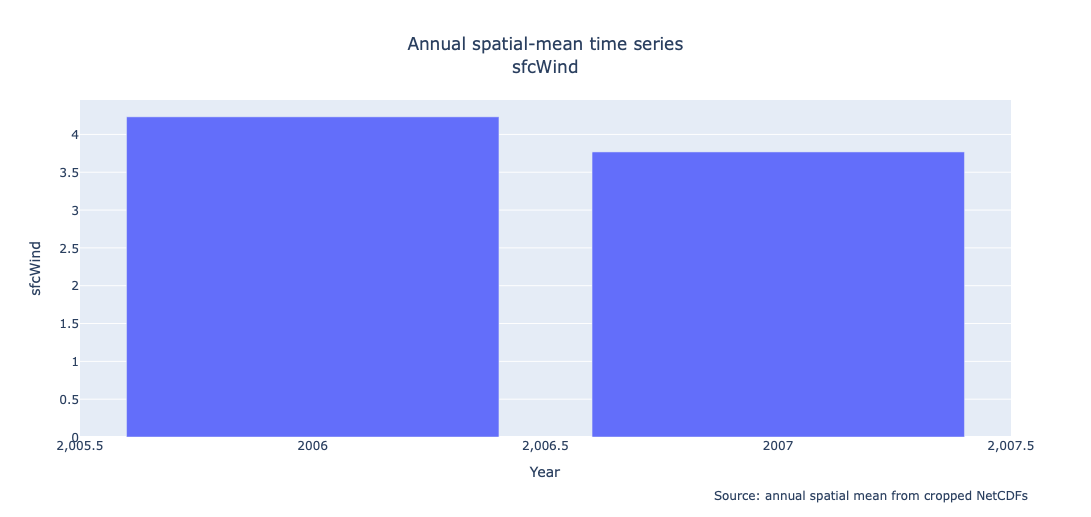

Saved: sfcWind.png | sfcWind.txt

--- tas ---
NaNs: 0


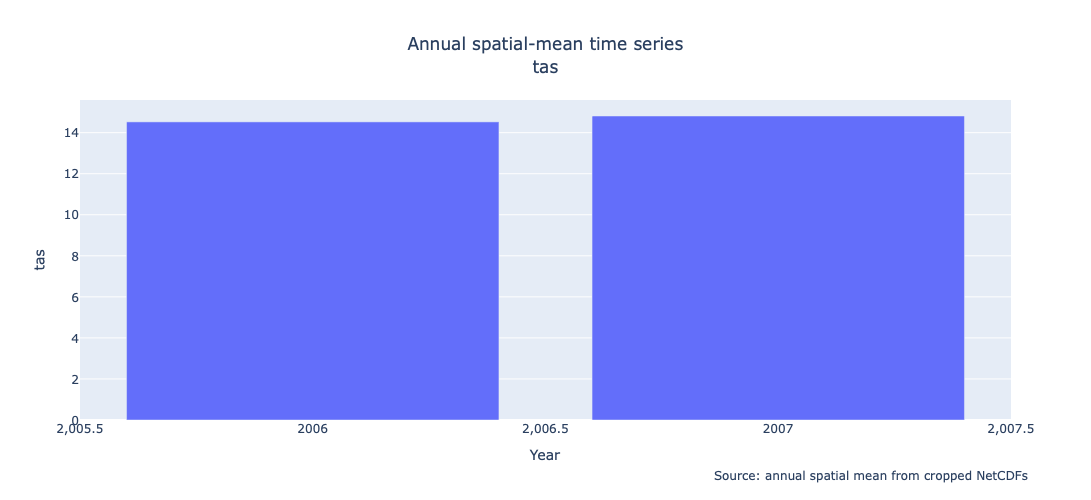

Saved: tas.png | tas.txt

--- hurs ---
NaNs: 0


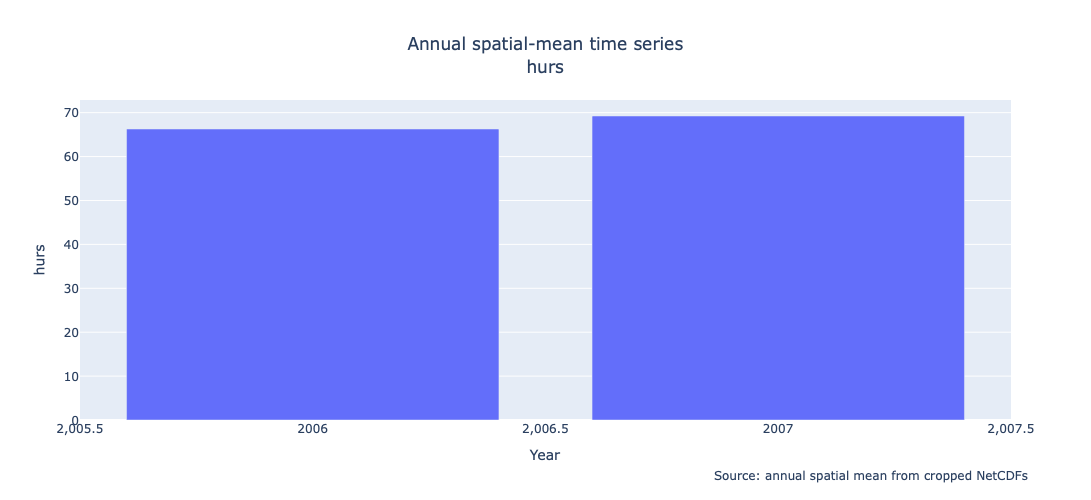

Saved: hurs.png | hurs.txt

--- tasmax ---
NaNs: 0


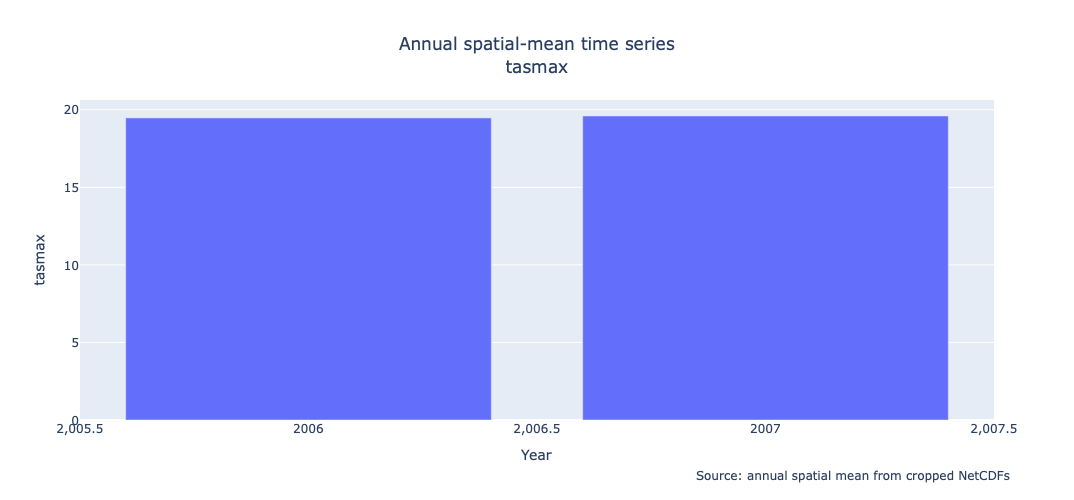

Saved: tasmax.png | tasmax.txt

--- tasmin ---
NaNs: 0


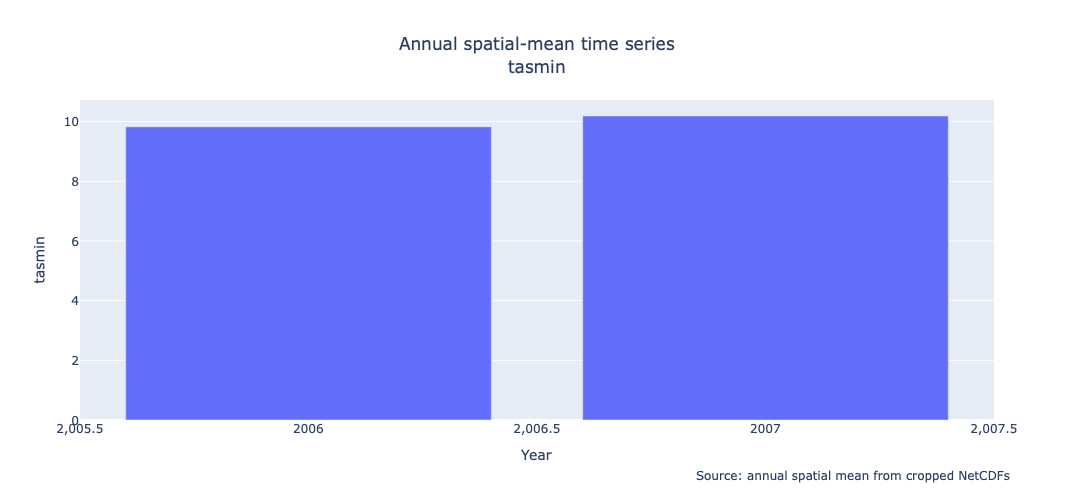

Saved: tasmin.png | tasmin.txt

--- rsds ---
NaNs: 0


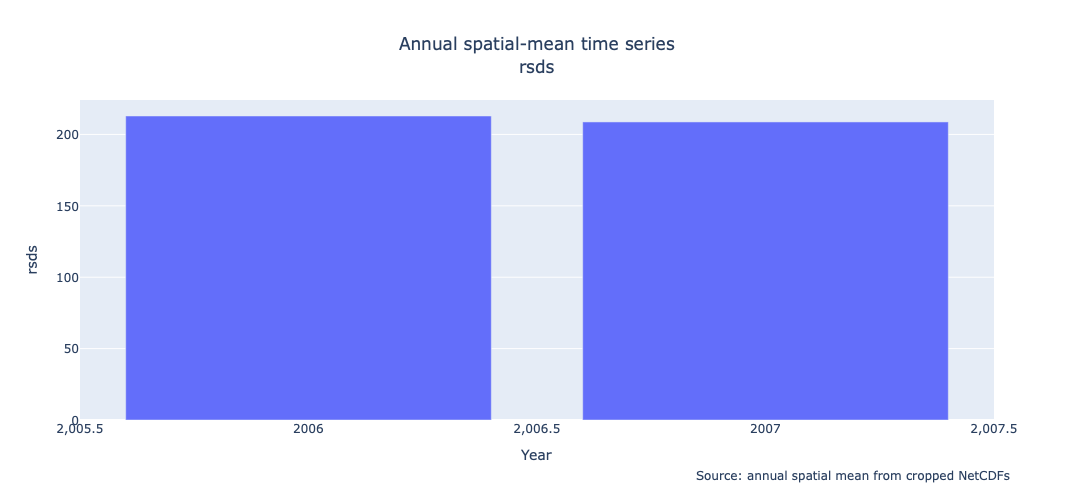

Saved: rsds.png | rsds.txt

--- pr ---
NaNs: 0


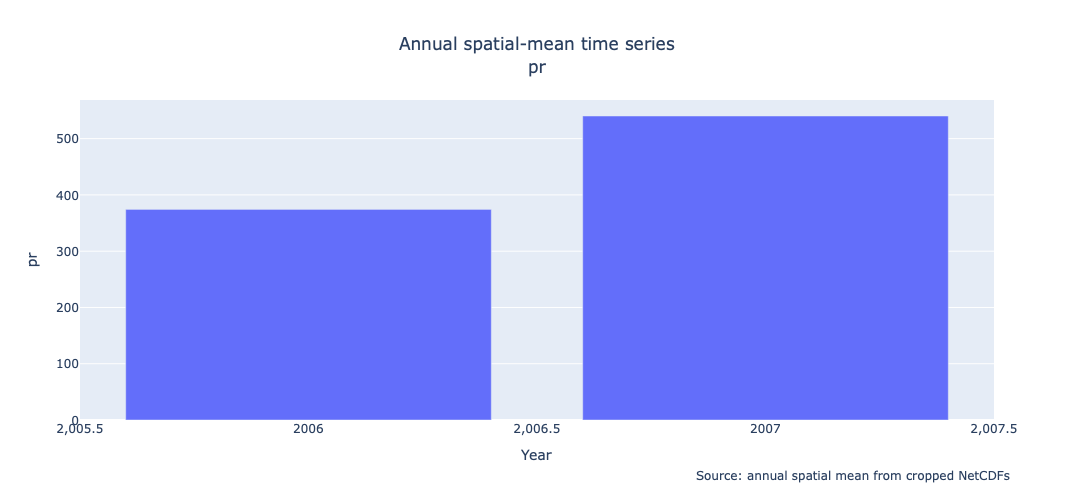

Saved: pr.png | pr.txt

🎉 Done.
Outputs saved in: output_final_merged/rcp_4.5/timeseries_plots


In [66]:
from pathlib import Path
import pandas as pd
import numpy as np
import plotly.graph_objects as go
from IPython.display import display

# =========================================
# Input / Output paths
# =========================================
BASE_DIR = Path("output_final_merged/rcp_4.5")
IN_CSV = BASE_DIR / "annual_timeseries_spatial_mean.csv"

if not IN_CSV.exists():
    raise FileNotFoundError(
        f"❌ Δεν βρέθηκε το {IN_CSV}. "
        "Τρέξε πρώτα το script που φτιάχνει το annual_timeseries_spatial_mean.csv"
    )

OUT_DIR = BASE_DIR / "timeseries_plots"
OUT_DIR.mkdir(parents=True, exist_ok=True)

# =========================================
# Read CSV
# =========================================
df = pd.read_csv(IN_CSV)

if "year" not in df.columns:
    raise ValueError("❌ Το CSV πρέπει να έχει στήλη 'year'.")

# Κρατάμε τη year και όλες τις υπόλοιπες μεταβλητές  [EN translation pending]
years = df["year"].to_numpy()
vars_cols = [c for c in df.columns if c != "year"]

if len(vars_cols) == 0:
    raise ValueError("❌ Δεν βρέθηκαν μεταβλητές στο CSV πέρα από τη στήλη 'year'.")

print("Years (min → max):", years[0], "→", years[-1], "| count:", len(years))
print("Variables found:", len(vars_cols))
print("Variable names:", vars_cols)

# =========================================
# Plot type
# =========================================
PLOT_KIND = "bar"   # "bar" ή "line"

# =========================================
# Save one combined TXT with all variables
# =========================================
# Θέλουμε την πρώτη στήλη να λέγεται Year  [EN translation pending]
df_all = df.copy()
df_all = df_all.rename(columns={"year": "Year"})

out_all_txt = OUT_DIR / "all_variables_timeseries.txt"
df_all.to_csv(out_all_txt, sep="\t", index=False)
print("Saved combined TXT:", out_all_txt.name)

# =========================================
# Loop through each variable
# =========================================
for col in vars_cols:
    y = df[col].to_numpy()

    # Debug info
    if np.issubdtype(y.dtype, np.number):
        nan_count = np.isnan(y).sum()
    else:
        nan_count = pd.isna(y).sum()

    print(f"\n--- {col} ---")
    print("NaNs:", nan_count)

    # =========================================
    # Create plot
    # =========================================
    fig = go.Figure()

    if PLOT_KIND == "bar":
        fig.add_trace(
            go.Bar(
                x=years,
                y=y,
                name=col
            )
        )
    else:
        fig.add_trace(
            go.Scatter(
                x=years,
                y=y,
                mode="lines+markers",
                name=col
            )
        )

    fig.update_layout(
        title={
            "text": f"Annual spatial-mean time series<br>{col}",
            "x": 0.5,
            "xanchor": "center"
        },
        xaxis_title="Year",
        yaxis_title=col,
        legend=dict(orientation="h", x=0, y=1),
        width=1100,
        height=500,
    )

    fig.add_annotation(
        xref="paper",
        yref="paper",
        x=1.02,
        y=-0.2,
        showarrow=False,
        text="Source: annual spatial mean from cropped NetCDFs"
    )

    # Show inside notebook
    display(fig)

    # =========================================
    # Safe filename
    # =========================================
    safe = "".join(
        ch if ch.isalnum() or ch in ("_", "-", ".") else "_"
        for ch in col
    )

    # =========================================
    # Save TXT for this variable
    # Column name = variable name (not 'Value')
    # =========================================
    out_txt = OUT_DIR / f"{safe}.txt"
    df_single = pd.DataFrame({
        "Year": years,
        col: y
    })
    df_single.to_csv(out_txt, sep="\t", index=False)

    # =========================================
    # Save PNG for this variable
    # Requires kaleido installed
    # =========================================
    out_png = OUT_DIR / f"{safe}.png"
    fig.write_image(str(out_png), scale=2)

    print("Saved:", out_png.name, "|", out_txt.name)

print("\n🎉 Done.")
print("Outputs saved in:", OUT_DIR)

Selected scenarios: ['rcp_4.5', 'rcp_8.5']
rcp_4.5 years: 2006 → 2007 | count: 2
rcp_8.5 years: 2006 → 2007 | count: 2
Common variables: ['hurs', 'pr', 'rsds', 'sfcWind', 'tas', 'tasmax', 'tasmin']
Saved combined TXT: output_final_merged/timeseries_plots_selected_scenarios_bars/all_variables_timeseries_selected_scenarios.txt
hurs | rcp_4.5 | missing values: 0
hurs | rcp_8.5 | missing values: 0


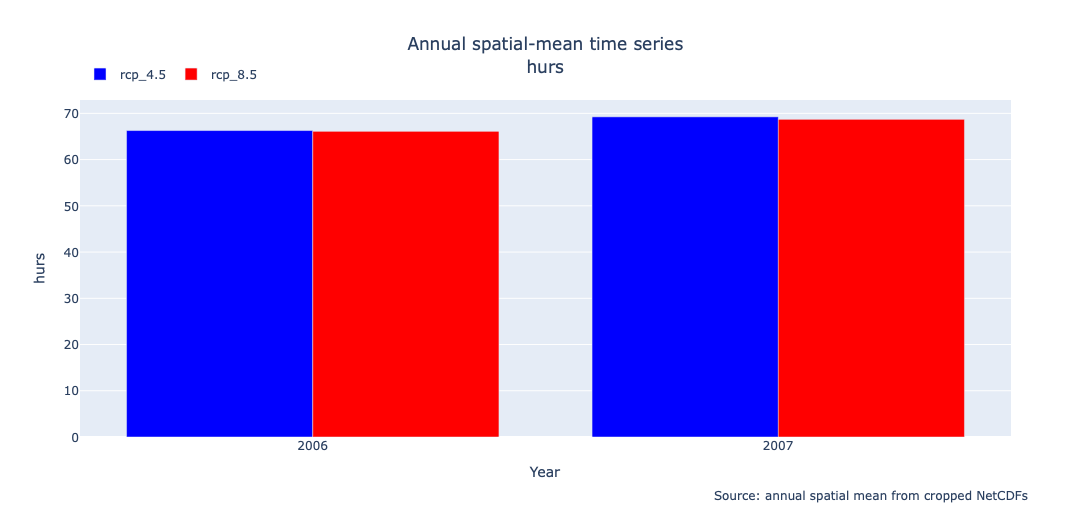

Saved: hurs_selected_scenarios.png | hurs_selected_scenarios.txt
pr | rcp_4.5 | missing values: 0
pr | rcp_8.5 | missing values: 0


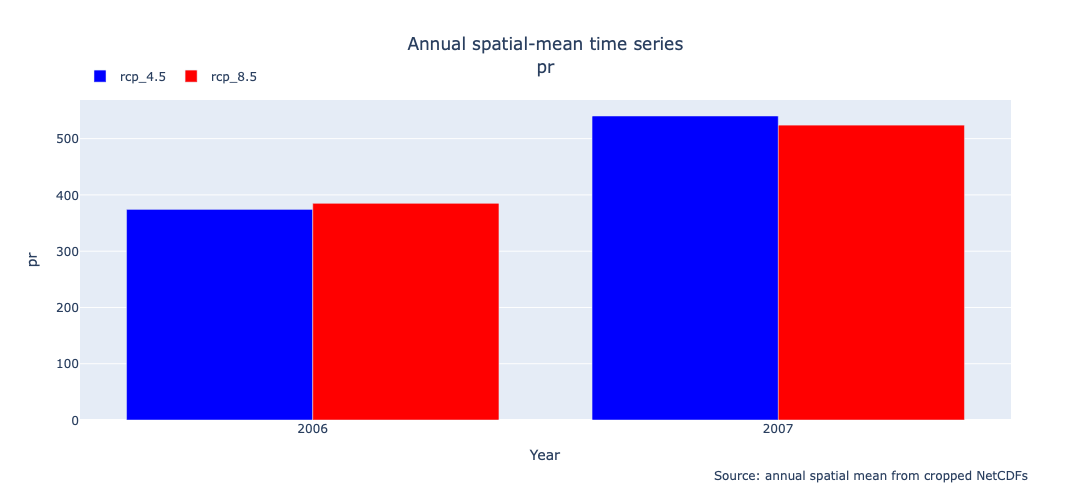

Saved: pr_selected_scenarios.png | pr_selected_scenarios.txt
rsds | rcp_4.5 | missing values: 0
rsds | rcp_8.5 | missing values: 0


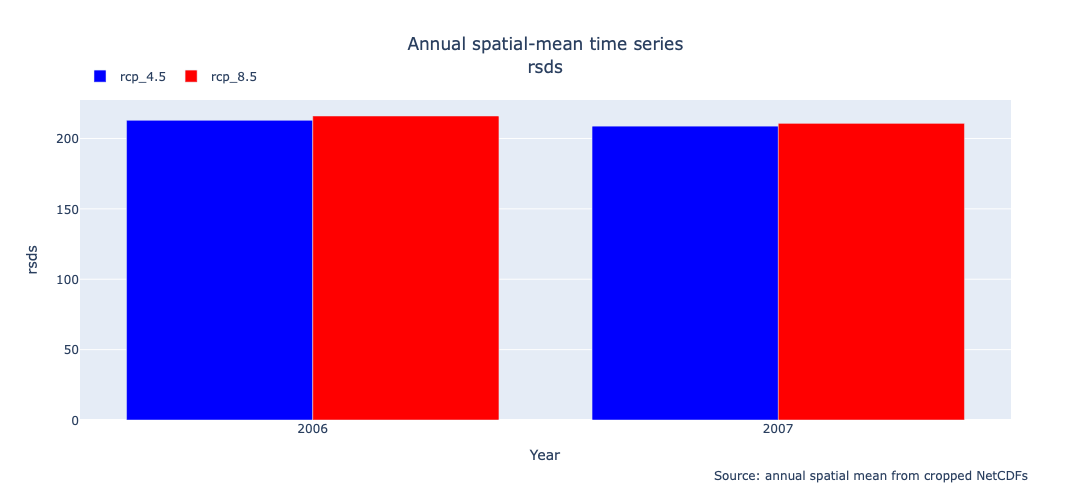

Saved: rsds_selected_scenarios.png | rsds_selected_scenarios.txt
sfcWind | rcp_4.5 | missing values: 0
sfcWind | rcp_8.5 | missing values: 0


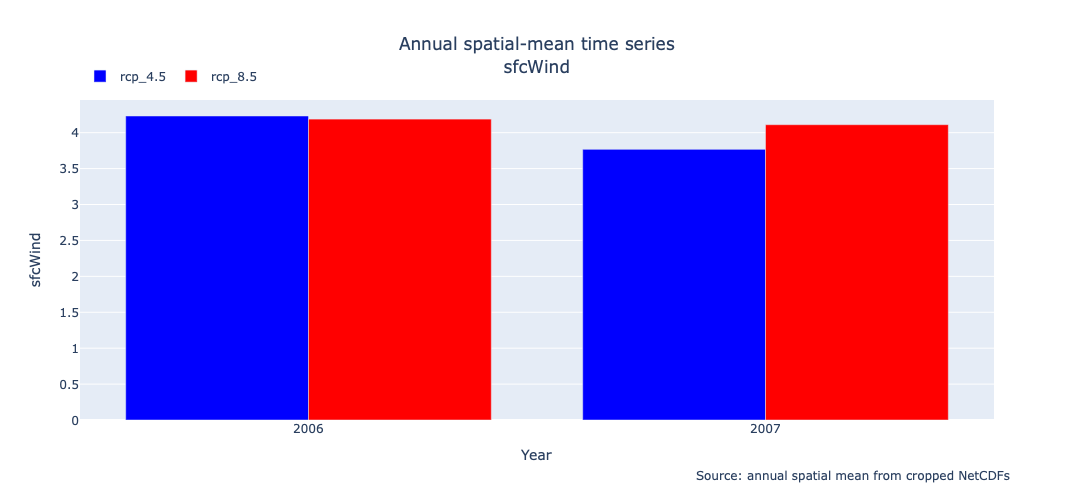

Saved: sfcWind_selected_scenarios.png | sfcWind_selected_scenarios.txt
tas | rcp_4.5 | missing values: 0
tas | rcp_8.5 | missing values: 0


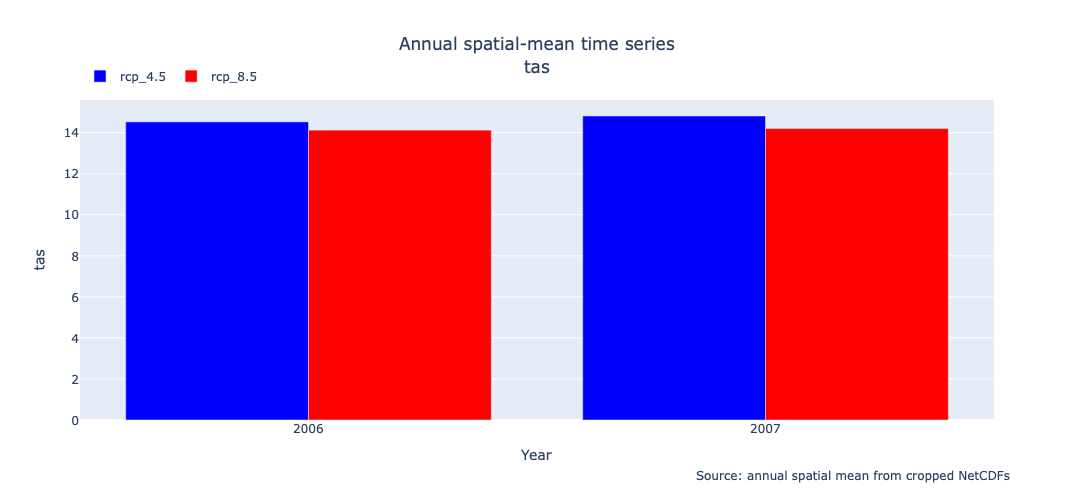

Saved: tas_selected_scenarios.png | tas_selected_scenarios.txt
tasmax | rcp_4.5 | missing values: 0
tasmax | rcp_8.5 | missing values: 0


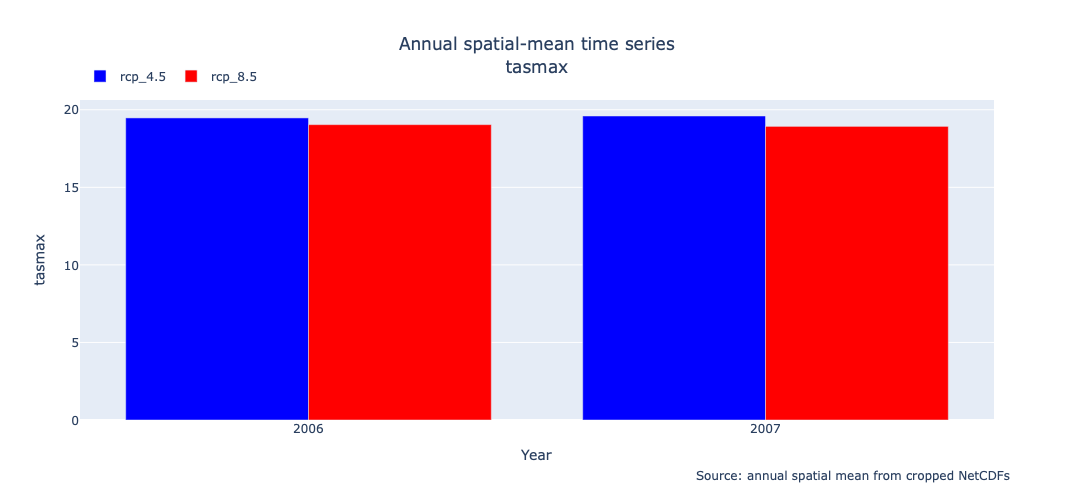

Saved: tasmax_selected_scenarios.png | tasmax_selected_scenarios.txt
tasmin | rcp_4.5 | missing values: 0
tasmin | rcp_8.5 | missing values: 0


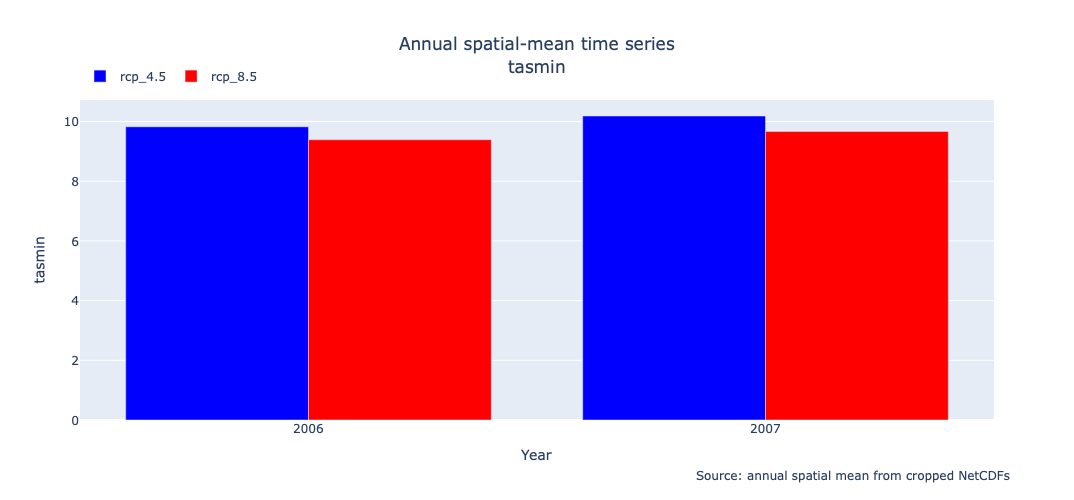

Saved: tasmin_selected_scenarios.png | tasmin_selected_scenarios.txt

Done.
Outputs saved in: output_final_merged/timeseries_plots_selected_scenarios_bars


In [67]:

from pathlib import Path
import pandas as pd
import numpy as np
import plotly.graph_objects as go
from IPython.display import display

# =========================================
# Input / Output paths
# =========================================

ROOT_DIR = Path("output_final_merged")

IN_CSV_PATHS = {
    scenario: ROOT_DIR / scenario / "annual_timeseries_spatial_mean.csv"
    for scenario in SELECTED_SCENARIOS
}

if not IN_CSV_PATHS:
    raise ValueError("No scenarios selected. Check SELECTED_SCENARIOS.")

for scenario, csv_path in IN_CSV_PATHS.items():
    if not csv_path.exists():
        raise FileNotFoundError(
            f"CSV not found: {csv_path}. "
            f"Generate the annual timeseries CSV for {scenario} first."
        )

OUT_DIR = ROOT_DIR / "timeseries_plots_selected_scenarios_bars"
OUT_DIR.mkdir(parents=True, exist_ok=True)

# =========================================
# Read and validate selected scenarios
# =========================================

dfs = {
    scenario: pd.read_csv(csv_path)
    for scenario, csv_path in IN_CSV_PATHS.items()
}

for scenario, df in dfs.items():
    if "year" not in df.columns:
        raise ValueError(f"CSV for {scenario} must contain a 'year' column.")

    df["year"] = pd.to_numeric(df["year"], errors="raise")
    dfs[scenario] = df.sort_values("year").reset_index(drop=True)

# Variables shared by all selected scenarios
vars_sets = [
    set(df.columns) - {"year"}
    for df in dfs.values()
]
vars_cols = sorted(set.intersection(*vars_sets))

if not vars_cols:
    raise ValueError("No common variables found across the selected scenarios.")

print("Selected scenarios:", list(dfs.keys()))
for scenario, df in dfs.items():
    print(f"{scenario} years: {df['year'].min()} → {df['year'].max()} | count: {len(df)}")

print("Common variables:", vars_cols)

# =========================================
# Save combined TXT for selected scenarios
# =========================================

combined = None

for scenario, df in dfs.items():
    suffix = scenario.replace(".", "").replace("-", "_")
    df_scenario = df[["year"] + vars_cols].copy()
    df_scenario = df_scenario.rename(
        columns={
            "year": "Year",
            **{col: f"{col}_{suffix}" for col in vars_cols}
        }
    )

    combined = (
        df_scenario if combined is None
        else pd.merge(combined, df_scenario, on="Year", how="outer")
    )

combined = combined.sort_values("Year").reset_index(drop=True)
out_all_txt = OUT_DIR / "all_variables_timeseries_selected_scenarios.txt"
combined.to_csv(out_all_txt, sep="\t", index=False)
print("Saved combined TXT:", out_all_txt)

# =========================================
# Plot each variable for selected scenarios
# =========================================

scenario_colours = {
    "rcp_4.5": "blue",
    "rcp_8.5": "red",
}

for col in vars_cols:
    fig = go.Figure()

    # Combine data by year for a clear comparison
    for scenario, df in dfs.items():
        y = df[col].to_numpy()
        nan_count = pd.isna(y).sum()
        print(f"{col} | {scenario} | missing values: {nan_count}")

        fig.add_trace(
            go.Bar(
                x=df["year"],
                y=y,
                name=scenario,
                marker_color=scenario_colours.get(scenario)
            )
        )

    fig.update_layout(
        title={
            "text": f"Annual spatial-mean time series<br>{col}",
            "x": 0.5,
            "xanchor": "center"
        },
        xaxis_title="Year",
        yaxis_title=col,
        legend=dict(orientation="h", x=0, y=1.12),
        barmode="group",
        width=1100,
        height=500,
    )

    fig.add_annotation(
        xref="paper",
        yref="paper",
        x=1.02,
        y=-0.2,
        showarrow=False,
        text="Source: annual spatial mean from cropped NetCDFs"
    )

    display(fig)

    safe = "".join(
        ch if ch.isalnum() or ch in ("_", "-", ".") else "_"
        for ch in col
    )

    # Save variable data for all selected scenarios
    variable_frames = []

    for scenario, df in dfs.items():
        suffix = scenario.replace(".", "").replace("-", "_")
        frame = df[["year", col]].rename(
            columns={
                "year": "Year",
                col: f"{col}_{suffix}"
            }
        )
        variable_frames.append(frame)

    df_single = variable_frames[0]
    for frame in variable_frames[1:]:
        df_single = pd.merge(df_single, frame, on="Year", how="outer")

    df_single = df_single.sort_values("Year").reset_index(drop=True)
    out_txt = OUT_DIR / f"{safe}_selected_scenarios.txt"
    df_single.to_csv(out_txt, sep="\t", index=False)

    out_png = OUT_DIR / f"{safe}_selected_scenarios.png"
    try:
        fig.write_image(str(out_png), scale=2)
        print("Saved:", out_png.name, "|", out_txt.name)
    except (ValueError, ImportError) as exc:
        print(f"PNG export failed ({exc}). TXT saved: {out_txt.name}")

print("\nDone.")
print("Outputs saved in:", OUT_DIR)


In [70]:
import xarray as xr
import numpy as np
from pathlib import Path

# -------------------- folder + files --------------------

# Choose the years based on the selected period
if INCLUDE_HISTORICAL:
    PERIOD_START = HIST_START_YEAR
    PERIOD_END = HIST_END_YEAR
else:
    PERIOD_START = START_YEAR
    PERIOD_END = END_YEAR

scenario = SELECTED_SCENARIOS[1]
scenario_suffix = scenario.replace(".", "")

BASE_DIR = Path(f"output_cropped_{scenario}")

FILES = [
    f"10m_wind_speed-{START_YEAR}-{END_YEAR}_{scenario_suffix}.nc",
    f"2m_air_temperature-{START_YEAR}-{END_YEAR}_{scenario_suffix}.nc",
    f"2m_relative_humidity-{START_YEAR}-{END_YEAR}_{scenario_suffix}.nc",
    f"minimum_2m_temperature_in_the_last_24_hours-{START_YEAR}-{END_YEAR}_{scenario_suffix}.nc",
    f"maximum_2m_temperature_in_the_last_24_hours-{START_YEAR}-{END_YEAR}_{scenario_suffix}.nc",
    f"mean_precipitation_flux-{START_YEAR}-{END_YEAR}_{scenario_suffix}.nc",
    f"surface_solar_radiation_downwards-{START_YEAR}-{END_YEAR}_{scenario_suffix}.nc",
]

paths = [BASE_DIR / f for f in FILES]

PRECIP_FILE = f"mean_precipitation_flux-{PERIOD_START}-{PERIOD_END}_{scenario_suffix}.nc"
KELVIN_TO_C = 273.15

# --------------------------------------------------------


def open_ds(nc_path: Path) -> xr.Dataset:
    ds = xr.open_dataset(nc_path, decode_times=True)

    if len(ds.data_vars) == 0:
        ds.close()
        raise ValueError(f"❌ No data_vars found in (Δεν υπάρχουν data_vars στο): {nc_path}")

    if "time" not in ds.coords and "time" not in ds.dims:
        ds.close()
        raise ValueError(f"❌ Could not find 'time' dimension/coordinate in (Δεν βρέθηκε η διάσταση/συντεταγμένη 'time' στο): {nc_path}")

    return ds


def is_temperature_var(var_name: str, da: xr.DataArray) -> bool:
    """
    We consider a variable to be temperature if (Θεωρούμε ότι μια μεταβλητή είναι θερμοκρασία αν):
    - units are K / Kelvin, or (units είναι K / Kelvin, ή)
    - standard_name / long_name contains 'temperature', or (standard_name / long_name περιέχει 'temperature', ή)
    - the variable name contains temp / temperature / tas (το όνομα της μεταβλητής περιέχει temp / temperature / tas)
    """
    units = str(da.attrs.get("units", "")).strip().lower()
    stdn = str(da.attrs.get("standard_name", "")).lower()
    lnam = str(da.attrs.get("long_name", "")).lower()
    name = var_name.lower()

    if units in {"k", "kelvin"}:
        return True
    if "temperature" in stdn or "temperature" in lnam:
        return True
    if any(tok in name for tok in ["temp", "temperature", "tas"]):
        return True

    return False


def convert_temperature_k_to_c(da: xr.DataArray) -> xr.DataArray:
    out = da - KELVIN_TO_C
    out.attrs = dict(da.attrs)
    out.attrs["units"] = "C"

    if "long_name" in out.attrs:
        out.attrs["long_name"] = f"{out.attrs['long_name']} (converted to Celsius)"
    else:
        out.attrs["long_name"] = "Temperature (converted to Celsius)"

    return out


def to_celsius_if_needed(da: xr.DataArray) -> xr.DataArray:
    """
    Ασφαλής μετατροπή θερμοκρασίας σε °C:
    - πρώτα κοιτάμε τα units
    - μόνο αν λείπουν, χρησιμοποιούμε heuristic
    """
    units = str(da.attrs.get("units", "")).strip().lower()

    if units in {"k", "kelvin"}:
        return convert_temperature_k_to_c(da)

    # fallback heuristic μόνο αν λείπουν τα units  [EN translation pending]
    if units == "":
        try:
            sample_mean = float(da.isel(time=0).mean(skipna=True).values)
            if sample_mean > 100:
                return convert_temperature_k_to_c(da)
        except Exception:
            pass

    return da


def infer_constant_timestep_seconds(time_coord: xr.DataArray) -> float:
    """
    Computes time step in seconds (Υπολογίζει το χρονικό βήμα σε δευτερόλεπτα).
    Requires constant time step (Απαιτεί σταθερό time step).
    """
    time_values = time_coord.values

    if len(time_values) < 2:
        raise ValueError("❌ Not enough time steps to compute time step (Δεν υπάρχουν αρκετά time steps για να υπολογιστεί το χρονικό βήμα).")

    diffs_sec = np.diff(time_values) / np.timedelta64(1, "s")
    diffs_sec = diffs_sec.astype(float)

    if not np.allclose(diffs_sec, diffs_sec[0]):
        raise ValueError(
            "❌ Time step is not constant (Το time step δεν είναι σταθερό). "
            "Cannot correctly convert precipitation flux to rainfall amount (Δεν μπορώ να μετατρέψω σωστά το precipitation flux σε ποσότητα βροχής)."
        )

    return float(diffs_sec[0])



def convert_precip_flux_to_mm_per_timestep(
    da: xr.DataArray,
) -> xr.DataArray:
    """Convert daily-mean precipitation flux to mm per day."""

    units = str(da.attrs.get("units", "")).strip().lower()
    expected_units = {
        "kg m-2 s-1",
        "kg m^-2 s^-1",
        "kg/m^2/s",
        "kg m**-2 s**-1",
    }

    if units not in expected_units:
        raise ValueError(
            f"Unexpected precipitation units: {units!r}. "
            "Expected daily-mean precipitation flux in kg m-2 s-1."
        )

    if TEMPORAL != "daily_mean":
        raise ValueError(
            f"Expected daily_mean data, got {TEMPORAL!r}."
        )

    if da.sizes.get("time", 0) == 0:
        raise ValueError("Precipitation data has no timestamps.")

    # Daily-mean flux × seconds per day = mm/day
    out = (da * 86400).astype("float32")
    out.attrs = dict(da.attrs)
    out.attrs["units"] = "mm/day"
    out.attrs["long_name"] = (
        "Daily precipitation amount derived from mean precipitation flux"
    )

    return out



def annual_aggregate_all_vars_to_file(nc_path: Path, is_precip_file: bool = False):
    ds = open_ds(nc_path)
    out_vars = {}

    for var_name, da in ds.data_vars.items():

        # --------------------------------------------------
        # περίπτωση βροχόπτωσης: flux -> mm per timestep -> annual sum  [EN translation pending]
        # --------------------------------------------------
        if is_precip_file:
            da2 = convert_precip_flux_to_mm_per_timestep(da)
            annual = da2.groupby("time.year").sum("time", skipna=True)
            annual.attrs = dict(da2.attrs)
            annual.attrs["units"] = "mm/year"

            if "long_name" in annual.attrs:
                annual.attrs["long_name"] = f"{annual.attrs['long_name']} (annual total)"
            else:
                annual.attrs["long_name"] = "Annual total precipitation"

        # --------------------------------------------------
        # όλες οι υπόλοιπες μεταβλητές: annual mean  [EN translation pending]
        # --------------------------------------------------
        else:
            da2 = da

            if is_temperature_var(var_name, da2):
                da2 = to_celsius_if_needed(da2)

            annual = da2.groupby("time.year").mean("time", skipna=True)
            annual.attrs = dict(da2.attrs)

        annual.name = var_name
        out_vars[var_name] = annual

    out_ds = xr.Dataset(out_vars)
    out_ds.attrs = dict(ds.attrs)

    out_name = f"annual_{'sum' if is_precip_file else 'mean'}_{nc_path.name}"
    out_path = nc_path.parent / out_name
    out_ds.to_netcdf(out_path)

    ds.close()
    print(f"✅ Output -> {out_path}")


# -------------------- run --------------------
paths = [BASE_DIR / f for f in FILES]

missing = [str(p) for p in paths if not p.exists()]
if missing:
    raise FileNotFoundError(
        "❌ Δεν βρέθηκαν τα παρακάτω αρχεία μέσα στο output_cropped:\n" + "\n".join(missing)
    )

for p in paths:
    annual_aggregate_all_vars_to_file(
        p,
        is_precip_file=(p.name == PRECIP_FILE)
    )

print("🎉 Done.")

✅ Output -> output_cropped_rcp_8.5/annual_mean_10m_wind_speed-2005-2007_rcp_85.nc
✅ Output -> output_cropped_rcp_8.5/annual_mean_2m_air_temperature-2005-2007_rcp_85.nc
✅ Output -> output_cropped_rcp_8.5/annual_mean_2m_relative_humidity-2005-2007_rcp_85.nc
✅ Output -> output_cropped_rcp_8.5/annual_mean_minimum_2m_temperature_in_the_last_24_hours-2005-2007_rcp_85.nc
✅ Output -> output_cropped_rcp_8.5/annual_mean_maximum_2m_temperature_in_the_last_24_hours-2005-2007_rcp_85.nc
✅ Output -> output_cropped_rcp_8.5/annual_sum_mean_precipitation_flux-2005-2007_rcp_85.nc
✅ Output -> output_cropped_rcp_8.5/annual_mean_surface_solar_radiation_downwards-2005-2007_rcp_85.nc
🎉 Done.


In [74]:
from pathlib import Path
import xarray as xr
import pandas as pd
import numpy as np



# ============================================================
# PATHS AND CONFIGURATION
# ============================================================

HIST_DIR = Path("output_cropped")

SCENARIO_DIRS = {
    "rcp_4.5": Path("output_cropped_rcp_4.5"),
    "rcp_8.5": Path("output_cropped_rcp_8.5"),
}

OUT_ROOT = Path("output_final_merged")
OUT_ROOT.mkdir(parents=True, exist_ok=True)

REQUIRE_ALL_PERIODS = True

TX_FILENAME = "maximum_2m_temperature_in_the_last_24_hours"
TN_FILENAME = "minimum_2m_temperature_in_the_last_24_hours"

scenario = SELECTED_SCENARIOS[1]
scenario_suffix = scenario.replace(".", "")

TX_FILE = f"{TX_FILENAME}-{PERIOD_START}-{PERIOD_END}_{scenario_suffix}.nc"
TN_FILE = f"{TN_FILENAME}-{PERIOD_START}-{PERIOD_END}_{scenario_suffix}.nc"

# ============================================================
# SCENARIOS / PERIODS
# ============================================================

TEMP_SCENARIO_PERIODS = {}

for scenario in SELECTED_SCENARIOS:
    if scenario not in SCENARIO_DIRS:
        raise ValueError(f"Unsupported scenario: {scenario}")

    periods = []

    # Add historical period only when enabled
    if INCLUDE_HISTORICAL:
        periods.append({
            "period": "HIST",
            "start": HIST_START_YEAR,
            "end": HIST_END_YEAR,
            "tx_path": (
                HIST_DIR /
                f"{TX_FILENAME}-{HIST_START_YEAR}-{HIST_END_YEAR}.nc"
            ),
            "tn_path": (
                HIST_DIR /
                f"{TN_FILENAME}-{HIST_START_YEAR}-{HIST_END_YEAR}.nc"
            ),
        })

    # Add configured future periods
    scenario_dir = SCENARIO_DIRS[scenario]

    for future in FUTURE_PERIODS:
        start = future["start"]
        end = future["end"]

        periods.append({
            "period": future["period"],
            "start": start,
            "end": end,
            "tx_path": scenario_dir / f"{TX_FILENAME}-{start}-{end}_{scenario.replace('.', '')}.nc",
            "tn_path": scenario_dir / f"{TN_FILENAME}-{start}-{end}_{scenario.replace('.', '')}.nc",
        })

    TEMP_SCENARIO_PERIODS[scenario] = periods


# ============================================================
# THRESHOLDS
# ============================================================

SU_THRESHOLD = 25.0   # Summer days: TX > 25°C
HD_THRESHOLD = 35.0   # Hot days: TX > 35°C
TR_THRESHOLD = 20.0   # Tropical nights: TN > 20°C


# ============================================================
# HELPERS
# ============================================================

def find_temperature_variable(ds: xr.Dataset, kind: str) -> str:
    """
    Βρίσκει τη βασική μεταβλητή θερμοκρασίας μέσα στο NetCDF.
    kind = TX για maximum temperature
    kind = TN για minimum temperature
    """

    candidates = [var for var in ds.data_vars if "time" in ds[var].dims]

    if not candidates:
        raise ValueError(
            f"❌ Δεν βρέθηκε μεταβλητή με διάσταση 'time'. "
            f"Διαθέσιμες μεταβλητές: {list(ds.data_vars)}"
        )

    if len(candidates) == 1:
        return candidates[0]

    if kind.upper() == "TX":
        preferred_keywords = [
            "maximum", "max", "tasmax", "tmax", "tx",
            "maximum_2m_temperature_in_the_last_24_hours"
        ]
    elif kind.upper() == "TN":
        preferred_keywords = [
            "minimum", "min", "tasmin", "tmin", "tn",
            "minimum_2m_temperature_in_the_last_24_hours"
        ]
    else:
        preferred_keywords = ["temperature", "temp", "tas"]

    scored = []

    for var in candidates:
        text = " ".join([
            var.lower(),
            str(ds[var].attrs.get("long_name", "")).lower(),
            str(ds[var].attrs.get("standard_name", "")).lower(),
        ])

        score = sum(1 for kw in preferred_keywords if kw.lower() in text)
        scored.append((score, var))

    scored.sort(reverse=True)

    return scored[0][1]


def convert_temperature_to_celsius(da: xr.DataArray) -> xr.DataArray:
    """
    Μετατρέπει θερμοκρασία σε βαθμούς Κελσίου.
    Αν είναι Kelvin, αφαιρεί 273.15.
    Αν είναι ήδη Celsius, την αφήνει όπως είναι.
    """

    units = str(da.attrs.get("units", "")).strip().lower()

    kelvin_units = {
        "k",
        "kelvin",
        "degrees_k",
        "degree_k"
    }

    celsius_units = {
        "c",
        "°c",
        "degc",
        "degree_celsius",
        "degrees_celsius",
        "celsius",
        "degree celsius",
        "degrees celsius"
    }

    if units in kelvin_units:
        out = da - 273.15
        out.attrs = dict(da.attrs)
        out.attrs["units"] = "degC"
        return out

    if units in celsius_units:
        out = da.copy()
        out.attrs = dict(da.attrs)
        out.attrs["units"] = "degC"
        return out

    if units == "":
        print("⚠️ Δεν βρέθηκαν units στη θερμοκρασία. Συνεχίζω σαν να είναι ήδη σε °C.")
        out = da.copy()
        out.attrs = dict(da.attrs)
        out.attrs["units"] = "degC"
        return out

    print(f"⚠️ Άγνωστα temperature units: '{units}'. Συνεχίζω σαν να είναι ήδη σε °C.")
    out = da.copy()
    out.attrs = dict(da.attrs)
    out.attrs["units"] = "degC"
    return out


def prepare_daily_temperature(da: xr.DataArray, kind: str) -> xr.DataArray:
    """
    Ετοιμάζει ημερήσια θερμοκρασία.

    Για TX:
    κρατάει/υπολογίζει ημερήσιο maximum.

    Για TN:
    κρατάει/υπολογίζει ημερήσιο minimum.

    Αν τα δεδομένα είναι ήδη ημερήσια, το resample δεν αλλάζει ουσιαστικά τις τιμές.
    """

    if "time" not in da.dims:
        raise ValueError("❌ The variable (Η μεταβλητή) θερμοκρασίας δεν έχει διάσταση 'time'.")

    da = da.sortby("time")
    da = convert_temperature_to_celsius(da)

    if kind.upper() == "TX":
        daily = da.resample(time="1D").max(skipna=True)
    elif kind.upper() == "TN":
        daily = da.resample(time="1D").min(skipna=True)
    else:
        raise ValueError("❌ Το kind πρέπει να είναι 'TX' ή 'TN'.")

    daily.attrs = dict(da.attrs)
    daily.attrs["units"] = "degC"

    return daily


def compute_tx_indices_for_one_period(
    tx_path: Path,
    tn_path: Path,
    start_year: int,
    end_year: int
):
    """
    Υπολογίζει SU, HD και TR για μία περίοδο.
    """

    if not tx_path.exists():
        raise FileNotFoundError(f"❌ Δεν βρέθηκε το αρχείο TX: {tx_path}")

    if not tn_path.exists():
        raise FileNotFoundError(f"❌ Δεν βρέθηκε το αρχείο TN: {tn_path}")

    ds_tx = xr.open_dataset(tx_path, decode_times=True)
    ds_tn = xr.open_dataset(tn_path, decode_times=True)

    try:
        print(f"      📄 TX file: {tx_path}")
        print(f"      📄 TN file: {tn_path}")

        print(f"      TX dataset variables: {list(ds_tx.data_vars)}")
        print(f"      TN dataset variables: {list(ds_tn.data_vars)}")

        tx_var = find_temperature_variable(ds_tx, kind="TX")
        tn_var = find_temperature_variable(ds_tn, kind="TN")

        print(f"      Using TX variable: {tx_var}")
        print(f"      Original TX units: {ds_tx[tx_var].attrs.get('units', 'UNKNOWN')}")

        print(f"      Using TN variable: {tn_var}")
        print(f"      Original TN units: {ds_tn[tn_var].attrs.get('units', 'UNKNOWN')}")

        tx = prepare_daily_temperature(ds_tx[tx_var], kind="TX")
        tn = prepare_daily_temperature(ds_tn[tn_var], kind="TN")

        tx = tx.sel(
            time=(tx["time.year"] >= start_year) &
                 (tx["time.year"] <= end_year)
        )

        tn = tn.sel(
            time=(tn["time.year"] >= start_year) &
                 (tn["time.year"] <= end_year)
        )

        if tx.sizes.get("time", 0) == 0:
            raise ValueError(
                f"❌ Δεν υπάρχουν TX δεδομένα μέσα στην περίοδο "
                f"{start_year}-{end_year} για το αρχείο {tx_path}"
            )

        if tn.sizes.get("time", 0) == 0:
            raise ValueError(
                f"❌ Δεν υπάρχουν TN δεδομένα μέσα στην περίοδο "
                f"{start_year}-{end_year} για το αρχείο {tn_path}"
            )

        print(f"      TX units after conversion: {tx.attrs.get('units', 'UNKNOWN')}")
        print(f"      TN units after conversion: {tn.attrs.get('units', 'UNKNOWN')}")

        # --------------------------------------------------------
        # SU
        # Annual count of days when TX > 25°C
        # --------------------------------------------------------
        su_annual = (tx > SU_THRESHOLD).groupby("time.year").sum(dim="time")
        su_annual.name = "SU"
        su_annual.attrs["long_name"] = "Annual count of summer days with TX > 25°C"
        su_annual.attrs["units"] = "days/year"

        # --------------------------------------------------------
        # HD
        # Annual count of days when TX > 35°C
        # --------------------------------------------------------
        hd_annual = (tx > HD_THRESHOLD).groupby("time.year").sum(dim="time")
        hd_annual.name = "HD"
        hd_annual.attrs["long_name"] = "Annual count of hot days with TX > 35°C"
        hd_annual.attrs["units"] = "days/year"

        # --------------------------------------------------------
        # TR
        # Annual count of days when TN > 20°C
        # --------------------------------------------------------
        tr_annual = (tn > TR_THRESHOLD).groupby("time.year").sum(dim="time")
        tr_annual.name = "TR"
        tr_annual.attrs["long_name"] = "Annual count of tropical nights with TN > 20°C"
        tr_annual.attrs["units"] = "days/year"

        return {
            "SU": su_annual.load(),
            "HD": hd_annual.load(),
            "TR": tr_annual.load(),
        }

    finally:
        ds_tx.close()
        ds_tn.close()


def tx_sort_and_remove_duplicate_years(da: xr.DataArray) -> xr.DataArray:
    """
    Ταξινομεί με βάση το year και αφαιρεί διπλές χρονιές.
    """

    da = da.sortby("year")

    values = da["year"].values
    _, unique_idx = np.unique(values, return_index=True)
    unique_idx = np.sort(unique_idx)

    return da.isel(year=unique_idx)


def tx_combine_dataarrays(dataarrays):
    """
    Ενώνει ετήσια DataArrays από διαφορετικές περιόδους.
    """

    combined = xr.concat(
        dataarrays,
        dim="year",
        coords="minimal",
        compat="override",
        join="outer"
    )

    combined = tx_sort_and_remove_duplicate_years(combined)

    return combined


def tx_spatial_mean_over_non_year_dims(da: xr.DataArray) -> xr.DataArray:
    """
    Χωρικός μέσος όρος πάνω σε όλες τις διαστάσεις εκτός από year.
    """

    dims_to_mean = [d for d in da.dims if d != "year"]

    if dims_to_mean:
        return da.mean(dim=dims_to_mean, skipna=True)

    return da


def tx_period_for_year(year: int, periods: list) -> str:
    """
    Επιστρέφει το label της περιόδου:
    HIST, P1 ή P2.
    """

    for p in periods:
        if p["start"] <= int(year) <= p["end"]:
            return p["period"]

    return "unknown"


def tx_annual_points_to_dataframe(da: xr.DataArray, periods: list) -> pd.DataFrame:
    """
    Μετατρέπει annual DataArray σε DataFrame:
    rows = years
    columns = Period + points

    Το αποτέλεσμα στα CSV/TXT θα έχει:
    Year | Period | point_0 | point_1 | ...
    """

    if "year" not in da.dims:
        raise ValueError("❌ Το DataArray δεν έχει διάσταση 'year'.")

    spatial_dims = [d for d in da.dims if d != "year"]

    if not spatial_dims:
        df = da.to_pandas().to_frame(name=da.name if da.name else "value")
    else:
        da2 = da.stack(point=spatial_dims)
        df = da2.to_pandas()
        df.columns = [f"point_{i}" for i in range(len(df.columns))]

    df.index.name = "Year"

    period_values = [tx_period_for_year(y, periods) for y in df.index.values]
    df.insert(0, "Period", period_values)

    return df


def tx_save_netcdf_compressed(ds: xr.Dataset, out_path: Path):
    """
    Αποθηκεύει compressed NetCDF.
    """

    encoding = {}

    for var in ds.data_vars:
        encoding[var] = {
            "zlib": True,
            "complevel": 4
        }

    ds.to_netcdf(out_path, encoding=encoding)


# ============================================================
# MAIN RUN
# ============================================================

for scenario_name, periods in TEMP_SCENARIO_PERIODS.items():

    print()
    print("=" * 70)
    print(f"🌡️ Scenario: {scenario_name}")
    print("=" * 70)

    scenario_out_dir = OUT_ROOT / scenario_name / "tx_indices"
    scenario_out_dir.mkdir(parents=True, exist_ok=True)

    su_list = []
    hd_list = []
    tr_list = []

    used_periods = []

    # --------------------------------------------------------
    # Υπολογισμός δεικτών ανά περίοδο  [EN translation pending]
    # --------------------------------------------------------
    for p in periods:
        period_label = p["period"]
        start_year = p["start"]
        end_year = p["end"]
        tx_path = p["tx_path"]
        tn_path = p["tn_path"]

        print()
        print(f"   📌 Period: {period_label} ({start_year}-{end_year})")

        missing_files = []

        if not tx_path.exists():
            missing_files.append(str(tx_path))

        if not tn_path.exists():
            missing_files.append(str(tn_path))

        if missing_files:
            message = (
                f"❌ Λείπουν αρχεία για {scenario_name} / "
                f"{period_label} ({start_year}-{end_year}):\n"
                + "\n".join([f"   - {f}" for f in missing_files])
            )

            if REQUIRE_ALL_PERIODS:
                raise FileNotFoundError(message)
            else:
                print(message)
                print("   ⚠️ Παραλείπεται αυτή η περίοδος.")
                continue

        result = compute_tx_indices_for_one_period(
            tx_path=tx_path,
            tn_path=tn_path,
            start_year=start_year,
            end_year=end_year
        )

        su_list.append(result["SU"])
        hd_list.append(result["HD"])
        tr_list.append(result["TR"])

        used_periods.append(p)

    if not used_periods:
        raise ValueError(f"❌ Δεν υπολογίστηκε καμία περίοδος για {scenario_name}.")

    # --------------------------------------------------------
    # Ένωση περιόδων  [EN translation pending]
    # --------------------------------------------------------
    su_all = tx_combine_dataarrays(su_list)
    hd_all = tx_combine_dataarrays(hd_list)
    tr_all = tx_combine_dataarrays(tr_list)

    # --------------------------------------------------------
    # Spatial mean annual time series
    # --------------------------------------------------------
    su_ts = tx_spatial_mean_over_non_year_dims(su_all)
    hd_ts = tx_spatial_mean_over_non_year_dims(hd_all)
    tr_ts = tx_spatial_mean_over_non_year_dims(tr_all)

    years = su_ts["year"].values

    if not np.array_equal(years, hd_ts["year"].values):
        raise ValueError("❌ Τα years του HD δεν ταιριάζουν με του SU.")

    if not np.array_equal(years, tr_ts["year"].values):
        raise ValueError("❌ Τα years του TR δεν ταιριάζουν με του SU.")

    period_col = [tx_period_for_year(y, used_periods) for y in years]

    # --------------------------------------------------------
    # Save combined spatial mean CSV/TXT
    # --------------------------------------------------------
    df_all = pd.DataFrame({
        "Year": years,
        "Period": period_col,
        "SU": su_ts.values,
        "HD": hd_ts.values,
        "TR": tr_ts.values,
    })

    out_all_csv = scenario_out_dir / "annual_temp_indices_spatial_mean.csv"
    out_all_txt = scenario_out_dir / "annual_temp_indices_spatial_mean.txt"

    df_all.to_csv(out_all_csv, index=False)
    df_all.to_csv(out_all_txt, sep="\t", index=False)

    print()
    print("✅ Saved combined spatial mean:")
    print("   -", out_all_csv)
    print("   -", out_all_txt)

    # --------------------------------------------------------
    # Save separate spatial mean CSV/TXT
    # --------------------------------------------------------
    df_su = df_all[["Year", "Period", "SU"]]
    df_hd = df_all[["Year", "Period", "HD"]]
    df_tr = df_all[["Year", "Period", "TR"]]

    df_su.to_csv(scenario_out_dir / "SU_annual_spatial_mean.csv", index=False)
    df_su.to_csv(scenario_out_dir / "SU_annual_spatial_mean.txt", sep="\t", index=False)

    df_hd.to_csv(scenario_out_dir / "HD_annual_spatial_mean.csv", index=False)
    df_hd.to_csv(scenario_out_dir / "HD_annual_spatial_mean.txt", sep="\t", index=False)

    df_tr.to_csv(scenario_out_dir / "TR_annual_spatial_mean.csv", index=False)
    df_tr.to_csv(scenario_out_dir / "TR_annual_spatial_mean.txt", sep="\t", index=False)

    print("✅ Saved separate spatial mean files.")

    # --------------------------------------------------------
    # Save annual point-level CSV/TXT
    # --------------------------------------------------------
    su_points_df = tx_annual_points_to_dataframe(su_all, used_periods)
    hd_points_df = tx_annual_points_to_dataframe(hd_all, used_periods)
    tr_points_df = tx_annual_points_to_dataframe(tr_all, used_periods)

    su_points_df.to_csv(scenario_out_dir / "SU_annual_by_point.csv")
    su_points_df.to_csv(scenario_out_dir / "SU_annual_by_point.txt", sep="\t")

    hd_points_df.to_csv(scenario_out_dir / "HD_annual_by_point.csv")
    hd_points_df.to_csv(scenario_out_dir / "HD_annual_by_point.txt", sep="\t")

    tr_points_df.to_csv(scenario_out_dir / "TR_annual_by_point.csv")
    tr_points_df.to_csv(scenario_out_dir / "TR_annual_by_point.txt", sep="\t")

    print("✅ Saved point-level annual files.")

    # --------------------------------------------------------
    # Save NetCDF with annual fields
    # --------------------------------------------------------
    out_ds = xr.Dataset({
        "SU": su_all,
        "HD": hd_all,
        "TR": tr_all,
    })

    out_ds.attrs["scenario"] = scenario_name
    out_ds.attrs["periods"] = ", ".join(
        [f"{p['period']} ({p['start']}-{p['end']})" for p in used_periods]
    )
    out_ds.attrs["description"] = (
        "Annual temperature indices computed from TX and TN files. "
        "SU: annual count of days with TX > 25°C. "
        "HD: annual count of days with TX > 35°C. "
        "TR: annual count of tropical nights with TN > 20°C."
    )

    out_nc = scenario_out_dir / "annual_temp_indices_by_gridpoint.nc"
    tx_save_netcdf_compressed(out_ds, out_nc)

    out_ds.close()

    print("✅ Saved NetCDF:")
    print("   -", out_nc)

    # --------------------------------------------------------
    # Diagnostics
    # --------------------------------------------------------
    print()
    print("📊 Diagnostics")
    print("Years:", int(years[0]), "→", int(years[-1]), "| count:", len(years))
    print(
        "Periods used:",
        ", ".join([f"{p['period']} ({p['start']}-{p['end']})" for p in used_periods])
    )
    print("SU min/max:", float(np.nanmin(su_ts.values)), float(np.nanmax(su_ts.values)))
    print("HD min/max:", float(np.nanmin(hd_ts.values)), float(np.nanmax(hd_ts.values)))
    print("TR min/max:", float(np.nanmin(tr_ts.values)), float(np.nanmax(tr_ts.values)))


print()
print("🎉 Temperature indices done.")
print("Outputs saved under:", OUT_ROOT.resolve())


# ============================================================
# ΑΠΟ ΚΑΤΩ ΒΑΖΕΙΣ ΤΟ ΥΠΑΡΧΟΝ SCRIPT ΓΙΑ:  [EN translation pending]
# Rx5day, R20mm, CDD
# ============================================================


🌡️ Scenario: rcp_4.5

   📌 Period: P1 (2005-2007)
      📄 TX file: output_cropped_rcp_4.5/maximum_2m_temperature_in_the_last_24_hours-2005-2007_rcp_45.nc
      📄 TN file: output_cropped_rcp_4.5/minimum_2m_temperature_in_the_last_24_hours-2005-2007_rcp_45.nc
      TX dataset variables: ['tasmax']
      TN dataset variables: ['tasmin']
      Using TX variable: tasmax
      Original TX units: K
      Using TN variable: tasmin
      Original TN units: K
      TX units after conversion: degC
      TN units after conversion: degC

✅ Saved combined spatial mean:
   - output_final_merged/rcp_4.5/tx_indices/annual_temp_indices_spatial_mean.csv
   - output_final_merged/rcp_4.5/tx_indices/annual_temp_indices_spatial_mean.txt
✅ Saved separate spatial mean files.
✅ Saved point-level annual files.
✅ Saved NetCDF:
   - output_final_merged/rcp_4.5/tx_indices/annual_temp_indices_by_gridpoint.nc

📊 Diagnostics
Years: 2006 → 2007 | count: 2
Periods used: P1 (2005-2007)
SU min/max: 93.0 94.0
HD min/max: 

In [78]:
from pathlib import Path
import pandas as pd
import numpy as np
import plotly.graph_objects as go
from IPython.display import display

# ============================================================
# Comparative BAR plots for:
# SU, HD, TR
#
# Blue  = Historical + RCP 4.5
# Red   = Historical + RCP 8.5
#
# Run this AFTER the script that creates:
# output_final_merged/rcp_4.5/tx_indices/annual_tx_indices_spatial_mean.csv
# output_final_merged/rcp_8.5/tx_indices/annual_tx_indices_spatial_mean.csv
# ============================================================

# =========================================
# Input / Output paths
# =========================================
# ============================================================
# Comparative BAR plots for:
# SU, HD, TR
# Scenarios are controlled by SELECTED_SCENARIOS
# ============================================================

# =========================================
# Input / Output paths
# =========================================
OUT_ROOT = Path("output_final_merged")

SCENARIO_CSVS = {}

for scenario in SELECTED_SCENARIOS:
    csv_path = (
        OUT_ROOT
        / scenario
        / "tx_indices"
        / "annual_temp_indices_spatial_mean.csv"
    )

    if not csv_path.exists():
        raise FileNotFoundError(
            f"Missing CSV for {scenario}: {csv_path}. "
            "Run the temperature-indices processing script first."
        )

    SCENARIO_CSVS[scenario] = csv_path

OUT_DIR = OUT_ROOT / (
    "timeseries_plots_SU_HD_TR_"
    + "_".join(SELECTED_SCENARIOS)
    + "_bars"
)
OUT_DIR.mkdir(parents=True, exist_ok=True)

OUT_DIR = OUT_ROOT / "timeseries_plots_SU_HD_TR_two_scenarios_bars"
OUT_DIR.mkdir(parents=True, exist_ok=True)

# =========================================
# Read CSV files
# =========================================
df45 = pd.read_csv(IN_CSV_45)
df85 = pd.read_csv(IN_CSV_85)

# Δέχεται είτε Year είτε year  [EN translation pending]
if "year" in df45.columns:
    df45 = df45.rename(columns={"year": "Year"})
elif "Year" not in df45.columns:
    raise ValueError("❌ Το CSV του rcp_4.5 πρέπει να έχει στήλη 'Year' ή 'year'.")

if "year" in df85.columns:
    df85 = df85.rename(columns={"year": "Year"})
elif "Year" not in df85.columns:
    raise ValueError("❌ Το CSV του rcp_8.5 πρέπει να έχει στήλη 'Year' ή 'year'.")

df45 = df45.sort_values("Year").reset_index(drop=True)
df85 = df85.sort_values("Year").reset_index(drop=True)

years45 = df45["Year"].to_numpy()
years85 = df85["Year"].to_numpy()

# =========================================
# Find common variables
# Exclude Year and Period
# =========================================
exclude_cols = ["Year", "Period"]

vars45 = [c for c in df45.columns if c not in exclude_cols]
vars85 = [c for c in df85.columns if c not in exclude_cols]

vars_cols = sorted(list(set(vars45).intersection(set(vars85))))

if len(vars_cols) == 0:
    raise ValueError("❌ Δεν βρέθηκαν κοινές μεταβλητές ανάμεσα στα δύο CSV.")

print("Historical + RCP 4.5 years:", years45[0], "→", years45[-1], "| count:", len(years45))
print("Historical + RCP 8.5 years:", years85[0], "→", years85[-1], "| count:", len(years85))
print("Common variables found:", len(vars_cols))
print("Variable names:", vars_cols)

# =========================================
# Save one combined TXT / CSV with all variables
# =========================================
df45_all = df45.copy()
df85_all = df85.copy()

# Κρατάμε Period μόνο από το rcp_4.5, γιατί είναι ίδιος διαχωρισμός περιόδων  [EN translation pending]
keep_cols_45 = ["Year"]
if "Period" in df45_all.columns:
    keep_cols_45.append("Period")

df45_all = df45_all[keep_cols_45 + vars_cols]
df85_all = df85_all[["Year"] + vars_cols]

df45_all = df45_all.rename(
    columns={c: f"{c}_historical_rcp45" for c in vars_cols}
)

df85_all = df85_all.rename(
    columns={c: f"{c}_historical_rcp85" for c in vars_cols}
)

df_all = pd.merge(df45_all, df85_all, on="Year", how="outer")
df_all = df_all.sort_values("Year").reset_index(drop=True)

out_all_txt = OUT_DIR / "SU_HD_TR_two_scenarios_all.txt"
out_all_csv = OUT_DIR / "SU_HD_TR_two_scenarios_all.csv"

df_all.to_csv(out_all_txt, sep="\t", index=False)
df_all.to_csv(out_all_csv, index=False)

print("Saved combined TXT:", out_all_txt.name)
print("Saved combined CSV:", out_all_csv.name)

# =========================================
# Loop through SU, HD, TR
# =========================================
for col in vars_cols:

    y45 = df45[col].to_numpy()
    y85 = df85[col].to_numpy()

    # Debug info
    if np.issubdtype(y45.dtype, np.number):
        nan_count_45 = np.isnan(y45).sum()
    else:
        nan_count_45 = pd.isna(y45).sum()

    if np.issubdtype(y85.dtype, np.number):
        nan_count_85 = np.isnan(y85).sum()
    else:
        nan_count_85 = pd.isna(y85).sum()

    print(f"\n--- {col} ---")
    print("NaNs Historical + RCP 4.5:", nan_count_45)
    print("NaNs Historical + RCP 8.5:", nan_count_85)

    # =========================================
    # Create BAR plot
    # =========================================
    fig = go.Figure()

    fig.add_trace(
        go.Bar(
            x=years45,
            y=y45,
            name="Historical + RCP 4.5",
            marker_color="blue"
        )
    )

    fig.add_trace(
        go.Bar(
            x=years85,
            y=y85,
            name="Historical + RCP 8.5",
            marker_color="red"
        )
    )

    fig.update_layout(
        title={
            "text": f"Annual spatial-mean time series<br>{col}",
            "x": 0.5,
            "xanchor": "center"
        },
        xaxis_title="Year",
        yaxis_title=f"{col} (days/year)",
        legend=dict(
            orientation="h",
            x=0,
            y=1.12
        ),
        barmode="group",
        width=1100,
        height=500,
    )

    fig.add_annotation(
        xref="paper",
        yref="paper",
        x=1.02,
        y=-0.2,
        showarrow=False,
        text="Source: annual spatial mean from TX/TN temperature indices"
    )

    # Show inside notebook
    display(fig)

    # =========================================
    # Safe filename
    # =========================================
    safe = "".join(
        ch if ch.isalnum() or ch in ("_", "-", ".") else "_"
        for ch in col
    )

    # =========================================
    # Save TXT for this variable
    # =========================================
    df_single_45 = pd.DataFrame({
        "Year": years45,
        f"{col}_historical_rcp45": y45
    })

    df_single_85 = pd.DataFrame({
        "Year": years85,
        f"{col}_historical_rcp85": y85
    })

    # Προσθέτουμε Period από το rcp_4.5, αν υπάρχει  [EN translation pending]
    if "Period" in df45.columns:
        df_single_45.insert(1, "Period", df45["Period"].to_numpy())

    df_single = pd.merge(df_single_45, df_single_85, on="Year", how="outer")
    df_single = df_single.sort_values("Year").reset_index(drop=True)

    out_txt = OUT_DIR / f"{safe}_two_scenarios.txt"
    df_single.to_csv(out_txt, sep="\t", index=False)

    # =========================================
    # Save PNG for this variable
    # Requires kaleido installed
    # =========================================
    out_png = OUT_DIR / f"{safe}_two_scenarios.png"
    fig.write_image(str(out_png), scale=2)

    print("Saved:", out_png.name, "|", out_txt.name)

print("\n🎉 Done.")
print("Outputs saved in:", OUT_DIR)

FileNotFoundError: [Errno 2] No such file or directory: 'output_final_merged/rcp_4.5/precip_indices/annual_precip_indices_spatial_mean.csv'

In [28]:
from pathlib import Path
import xarray as xr
import pandas as pd
import numpy as np

#SERVICE 1.2 (1o)
# ============================================================
# PATHS
# ============================================================

HIST_DIR = Path("output_cropped")
RCP45_DIR = Path("output_cropped_rcp_4.5")
RCP85_DIR = Path("output_cropped_rcp_8.5")

# Εδώ αποθηκεύονται τα τελικά αποτελέσματα των δεικτών  [EN translation pending]
OUT_ROOT = Path("output_final_merged")
OUT_ROOT.mkdir(parents=True, exist_ok=True)

# Αν είναι True, σταματάει αν λείπει κάποια περίοδος.  [EN translation pending]
# Αν είναι False, παραλείπει όσα αρχεία λείπουν και συνεχίζει.  [EN translation pending]
REQUIRE_ALL_PERIODS = True


# ============================================================
# SCENARIOS / PERIODS
# ============================================================

SCENARIO_PERIODS = {
    "rcp_4.5": [
        {
            "period": "HIST",
            "start": 1980,
            "end": 2004,
            "path": HIST_DIR / "mean_precipitation_flux-1980-2004.nc",
        },
        {
            "period": "P1",
            "start": 2025,
            "end": 2049,
            "path": RCP45_DIR / "mean_precipitation_flux-2025-2049.nc",
        },
        {
            "period": "P2",
            "start": 2075,
            "end": 2099,
            "path": RCP45_DIR / "mean_precipitation_flux-2075-2099.nc",
        },
    ],

    "rcp_8.5": [
        {
            "period": "HIST",
            "start": 1980,
            "end": 2004,
            "path": HIST_DIR / "mean_precipitation_flux-1980-2004.nc",
        },
        {
            "period": "P1",
            "start": 2025,
            "end": 2049,
            "path": RCP85_DIR / "mean_precipitation_flux-2025-2049.nc",
        },
        {
            "period": "P2",
            "start": 2075,
            "end": 2099,
            "path": RCP85_DIR / "mean_precipitation_flux-2075-2099.nc",
        },
    ],
}


# ============================================================
# THRESHOLDS
# ============================================================

R20_THRESHOLD = 20.0   # mm/day
DRY_THRESHOLD = 1.0    # mm/day


# ============================================================
# HELPERS
# ============================================================

def find_main_variable(ds: xr.Dataset) -> str:
    """
    Βρίσκει τη βασική μεταβλητή βροχόπτωσης.
    """
    candidates = [var for var in ds.data_vars if "time" in ds[var].dims]

    if not candidates:
        raise ValueError(
            f"❌ Δεν βρέθηκε data variable με διάσταση 'time'. "
            f"Διαθέσιμες μεταβλητές: {list(ds.data_vars)}"
        )

    if len(candidates) == 1:
        return candidates[0]

    preferred_keywords = ["precip", "precipitation", "rain", "rr", "prcp", "flux"]

    scored = []

    for var in candidates:
        score = sum(1 for kw in preferred_keywords if kw.lower() in var.lower())
        scored.append((score, var))

    scored.sort(reverse=True)

    return scored[0][1]


def infer_constant_timestep_seconds(time_coord: xr.DataArray) -> float:
    """
    Computes time step in seconds (Υπολογίζει το χρονικό βήμα σε δευτερόλεπτα).
    Απαιτεί σταθερό timestep.
    """
    time_values = time_coord.values

    if len(time_values) < 2:
        raise ValueError("❌ Δεν υπάρχουν αρκετά time steps για υπολογισμό timestep.")

    diffs_sec = np.diff(time_values) / np.timedelta64(1, "s")
    diffs_sec = diffs_sec.astype(float)

    if not np.allclose(diffs_sec, diffs_sec[0]):
        raise ValueError(
            "❌ Time step is not constant (Το time step δεν είναι σταθερό). "
            "Δεν μπορώ να μετατρέψω σωστά το precipitation flux."
        )

    return float(diffs_sec[0])


def convert_precip_to_daily_mm(da: xr.DataArray) -> xr.DataArray:
    """
    Μετατρέπει precipitation σε ημερήσια βροχόπτωση mm/day.

    Περιπτώσεις:
    - kg m-2 s-1 -> mm ανά timestep -> ημερήσιο άθροισμα αν είναι υποημερήσιο
    - mm/day -> το αφήνει ως έχει
    - mm -> θεωρεί ότι είναι ποσότητα ανά timestep
    """
    if "time" not in da.dims:
        raise ValueError("❌ The variable (Η μεταβλητή) βροχόπτωσης δεν έχει διάσταση 'time'.")

    da = da.sortby("time")

    units = str(da.attrs.get("units", "")).strip().lower()

    flux_units = {
        "kg m-2 s-1",
        "kg m^-2 s^-1",
        "kg/m^2/s",
        "kg m**-2 s**-1",
    }

    daily_units = {
        "mm/day",
        "mm d-1",
        "mm per day",
        "mm day-1",
    }

    amount_units = {
        "mm",
        "millimeter",
        "millimeters",
    }

    step_seconds = infer_constant_timestep_seconds(da["time"])

    # --------------------------------------------------------
    # Περίπτωση 1: ήδη mm/day  [EN translation pending]
    # --------------------------------------------------------
    if units in daily_units:
        rr_daily = da.copy()
        rr_daily.attrs = dict(da.attrs)
        rr_daily.attrs["units"] = "mm/day"
        return rr_daily

    # --------------------------------------------------------
    # Περίπτωση 2: precipitation flux  [EN translation pending]
    # kg m-2 s-1 * seconds = mm ανά timestep  [EN translation pending]
    # --------------------------------------------------------
    if units in flux_units or units == "":
        rr_step = (da * step_seconds).astype("float32")
        rr_step.attrs = dict(da.attrs)
        rr_step.attrs["units"] = "mm"

    # --------------------------------------------------------
    # Περίπτωση 3: ήδη mm ανά timestep  [EN translation pending]
    # --------------------------------------------------------
    elif units in amount_units:
        rr_step = da.copy()
        rr_step.attrs = dict(da.attrs)
        rr_step.attrs["units"] = "mm"

    else:
        print(f"⚠️ Άγνωστα precipitation units: '{units}'. Συνεχίζω χωρίς μετατροπή.")
        rr_step = da.copy()

    # --------------------------------------------------------
    # Αν είναι ημερήσιο timestep, then (τότε) είναι ήδη ημερήσια βροχόπτωση.  [EN translation pending]
    # Αν είναι υποημερήσιο, κάνουμε ημερήσιο άθροισμα.  [EN translation pending]
    # --------------------------------------------------------
    if np.isclose(step_seconds, 86400.0):
        rr_daily = rr_step

    elif step_seconds < 86400.0:
        rr_daily = rr_step.resample(time="1D").sum(skipna=True)

    else:
        raise ValueError(
            f"❌ Το timestep είναι μεγαλύτερο από ημερήσιο: {step_seconds} seconds. "
            "Οι δείκτες Rx5day, R20mm και CDD χρειάζονται ημερήσια δεδομένα."
        )

    rr_daily.attrs = dict(rr_step.attrs)
    rr_daily.attrs["units"] = "mm/day"

    if "long_name" in rr_daily.attrs:
        rr_daily.attrs["long_name"] = (
            f"{rr_daily.attrs['long_name']} (daily precipitation in mm/day)"
        )
    else:
        rr_daily.attrs["long_name"] = "Daily precipitation in mm/day"

    return rr_daily


def max_consecutive_dry_1d(arr_1d: np.ndarray, dry_threshold: float = 1.0) -> float:
    """
    Επιστρέφει το μέγιστο πλήθος συνεχόμενων ημερών με RR < dry_threshold.
    """
    max_run = 0
    current_run = 0

    for val in arr_1d:
        if np.isfinite(val) and val < dry_threshold:
            current_run += 1
            max_run = max(max_run, current_run)
        else:
            current_run = 0

    return float(max_run)


def compute_cdd_annual(rr: xr.DataArray) -> xr.DataArray:
    """
    Υπολογίζει CDD ανά έτος και ανά χωρικό σημείο.
    """
    # Βάζουμε το time πρώτο για να δουλεύει σωστά το reshape  [EN translation pending]
    other_dims = [d for d in rr.dims if d != "time"]
    rr = rr.transpose("time", *other_dims)

    years = np.unique(rr["time.year"].values)

    if len(other_dims) == 0:
        raise ValueError("❌ Δεν υπάρχει χωρική/point διάσταση πέρα από το time.")

    cdd_list = []

    for y in years:
        rr_year = rr.sel(time=rr["time.year"] == y)
        arr = rr_year.values

        arr_2d = arr.reshape(arr.shape[0], -1)
        cdd_year = np.zeros(arr_2d.shape[1], dtype=np.float32)

        for i in range(arr_2d.shape[1]):
            cdd_year[i] = max_consecutive_dry_1d(
                arr_2d[:, i],
                dry_threshold=DRY_THRESHOLD
            )

        cdd_year = cdd_year.reshape(arr.shape[1:])
        cdd_list.append(cdd_year)

    coords = {"year": years}

    for d in other_dims:
        if d in rr.coords:
            coords[d] = rr.coords[d]

    cdd_annual = xr.DataArray(
        data=np.stack(cdd_list, axis=0),
        coords=coords,
        dims=["year"] + other_dims,
        name="CDD"
    )

    cdd_annual.attrs["long_name"] = "Annual maximum consecutive dry days (RR < 1 mm)"
    cdd_annual.attrs["units"] = "days"

    return cdd_annual


def compute_indices_for_one_file(nc_path: Path, start_year: int, end_year: int):
    """
    Υπολογίζει Rx5day, R20mm και CDD για ένα precipitation αρχείο.
    """
    if not nc_path.exists():
        raise FileNotFoundError(f"❌ Δεν βρέθηκε το αρχείο: {nc_path}")

    ds = xr.open_dataset(nc_path, decode_times=True)

    try:
        print(f"      📄 File: {nc_path}")
        print(f"      Dataset variables: {list(ds.data_vars)}")
        print(f"      Dataset dims: {dict(ds.sizes)}")

        var_name = find_main_variable(ds)
        da = ds[var_name]

        print(f"      Using variable: {var_name}")
        print(f"      Original units: {da.attrs.get('units', 'UNKNOWN')}")

        rr = convert_precip_to_daily_mm(da)

        # Κρατάμε μόνο τα έτη της συγκεκριμένης περιόδου  [EN translation pending]
        rr = rr.sel(
            time=(rr["time.year"] >= start_year) &
                 (rr["time.year"] <= end_year)
        )

        if rr.sizes.get("time", 0) == 0:
            raise ValueError(
                f"❌ Δεν υπάρχουν χρονικά δεδομένα μέσα στην περίοδο "
                f"{start_year}-{end_year} για το αρχείο {nc_path}"
            )

        print(f"      Units after conversion: {rr.attrs.get('units', 'UNKNOWN')}")

        # --------------------------------------------------------
        # R20mm
        # Annual count of days with RR >= 20 mm
        # --------------------------------------------------------
        r20_annual = (rr >= R20_THRESHOLD).groupby("time.year").sum(dim="time")
        r20_annual.name = "R20mm"
        r20_annual.attrs["long_name"] = "Annual count of days with precipitation >= 20 mm"
        r20_annual.attrs["units"] = "days/year"

        # --------------------------------------------------------
        # Rx5day
        # Annual maximum consecutive 5-day precipitation
        # --------------------------------------------------------
        rr_5day = rr.rolling(time=5, min_periods=5).sum()
        rx5day_annual = rr_5day.groupby("time.year").max(dim="time")
        rx5day_annual.name = "Rx5day"
        rx5day_annual.attrs["long_name"] = "Annual maximum consecutive 5-day precipitation"
        rx5day_annual.attrs["units"] = "mm"

        # --------------------------------------------------------
        # CDD
        # Annual maximum consecutive dry days
        # --------------------------------------------------------
        cdd_annual = compute_cdd_annual(rr)

        return {
            "R20mm": r20_annual.load(),
            "Rx5day": rx5day_annual.load(),
            "CDD": cdd_annual.load(),
        }

    finally:
        ds.close()


def sort_and_remove_duplicate_years(da: xr.DataArray) -> xr.DataArray:
    """
    Ταξινομεί με βάση το year και αφαιρεί διπλές χρονιές.
    """
    da = da.sortby("year")

    values = da["year"].values
    _, unique_idx = np.unique(values, return_index=True)
    unique_idx = np.sort(unique_idx)

    return da.isel(year=unique_idx)


def combine_dataarrays(dataarrays):
    """
    Ενώνει ετήσια DataArrays από διαφορετικές περιόδους.
    """
    combined = xr.concat(
        dataarrays,
        dim="year",
        coords="minimal",
        compat="override",
        join="outer"
    )

    combined = sort_and_remove_duplicate_years(combined)

    return combined


def spatial_mean_over_non_year_dims(da: xr.DataArray) -> xr.DataArray:
    """
    Χωρικός μέσος όρος πάνω σε όλες τις διαστάσεις εκτός από year.
    """
    dims_to_mean = [d for d in da.dims if d != "year"]

    if dims_to_mean:
        return da.mean(dim=dims_to_mean, skipna=True)

    return da


def period_for_year(year: int, periods: list) -> str:
    """
    Επιστρέφει το label της περιόδου:
    HIST, P1 ή P2.
    """
    for p in periods:
        if p["start"] <= int(year) <= p["end"]:
            return p["period"]

    return "unknown"


def annual_points_to_dataframe(da: xr.DataArray, periods: list) -> pd.DataFrame:
    """
    Μετατρέπει annual DataArray σε DataFrame:
    rows = years
    columns = Period + points

    Το αποτέλεσμα στα CSV/TXT θα έχει:
    Year | Period | point_0 | point_1 | ...
    """
    if "year" not in da.dims:
        raise ValueError("❌ Το DataArray δεν έχει διάσταση 'year'.")

    spatial_dims = [d for d in da.dims if d != "year"]

    if not spatial_dims:
        df = da.to_pandas().to_frame(name=da.name if da.name else "value")
    else:
        da2 = da.stack(point=spatial_dims)
        df = da2.to_pandas()
        df.columns = [f"point_{i}" for i in range(len(df.columns))]

    df.index.name = "Year"

    period_values = [period_for_year(y, periods) for y in df.index.values]
    df.insert(0, "Period", period_values)

    return df


def save_netcdf_compressed(ds: xr.Dataset, out_path: Path):
    """
    Αποθηκεύει compressed NetCDF.
    """
    encoding = {}

    for var in ds.data_vars:
        encoding[var] = {
            "zlib": True,
            "complevel": 4
        }

    ds.to_netcdf(out_path, encoding=encoding)


# ============================================================
# MAIN RUN
# ============================================================

for scenario_name, periods in SCENARIO_PERIODS.items():

    print()
    print("=" * 70)
    print(f"🌍 Scenario: {scenario_name}")
    print("=" * 70)

    scenario_out_dir = OUT_ROOT / scenario_name / "precip_indices"
    scenario_out_dir.mkdir(parents=True, exist_ok=True)

    r20_list = []
    rx5day_list = []
    cdd_list = []

    used_periods = []

    # --------------------------------------------------------
    # Υπολογισμός δεικτών ανά περίοδο  [EN translation pending]
    # --------------------------------------------------------
    for p in periods:
        period_label = p["period"]
        nc_path = p["path"]
        start_year = p["start"]
        end_year = p["end"]

        print()
        print(f"   📌 Period: {period_label} ({start_year}-{end_year})")

        if not nc_path.exists():
            message = (
                f"❌ Λείπει το αρχείο για {scenario_name} / "
                f"{period_label} ({start_year}-{end_year}): {nc_path}"
            )

            if REQUIRE_ALL_PERIODS:
                raise FileNotFoundError(message)
            else:
                print(message)
                print("   ⚠️ Παραλείπεται αυτή η περίοδος.")
                continue

        result = compute_indices_for_one_file(
            nc_path=nc_path,
            start_year=start_year,
            end_year=end_year
        )

        r20_list.append(result["R20mm"])
        rx5day_list.append(result["Rx5day"])
        cdd_list.append(result["CDD"])
        used_periods.append(p)

    if not used_periods:
        raise ValueError(f"❌ Δεν υπολογίστηκε καμία περίοδος για {scenario_name}.")

    # --------------------------------------------------------
    # Ένωση περιόδων  [EN translation pending]
    # --------------------------------------------------------
    r20_all = combine_dataarrays(r20_list)
    rx5day_all = combine_dataarrays(rx5day_list)
    cdd_all = combine_dataarrays(cdd_list)

    # --------------------------------------------------------
    # Spatial mean annual time series
    # --------------------------------------------------------
    r20_ts = spatial_mean_over_non_year_dims(r20_all)
    rx5day_ts = spatial_mean_over_non_year_dims(rx5day_all)
    cdd_ts = spatial_mean_over_non_year_dims(cdd_all)

    years = r20_ts["year"].values

    if not np.array_equal(years, rx5day_ts["year"].values):
        raise ValueError("❌ Τα years του Rx5day δεν ταιριάζουν με του R20mm.")

    if not np.array_equal(years, cdd_ts["year"].values):
        raise ValueError("❌ Τα years του CDD δεν ταιριάζουν με του R20mm.")

    period_col = [period_for_year(y, used_periods) for y in years]

    # --------------------------------------------------------
    # Save combined spatial mean CSV/TXT
    # Εδώ μπαίνουν HIST / P1 / P2  [EN translation pending]
    # --------------------------------------------------------
    df_all = pd.DataFrame({
        "Year": years,
        "Period": period_col,
        "Rx5day": rx5day_ts.values,
        "R20mm": r20_ts.values,
        "CDD": cdd_ts.values,
    })

    out_all_csv = scenario_out_dir / "annual_precip_indices_spatial_mean.csv"
    out_all_txt = scenario_out_dir / "annual_precip_indices_spatial_mean.txt"

    df_all.to_csv(out_all_csv, index=False)
    df_all.to_csv(out_all_txt, sep="\t", index=False)

    print()
    print("✅ Saved combined spatial mean:")
    print("   -", out_all_csv)
    print("   -", out_all_txt)

    # --------------------------------------------------------
    # Save separate spatial mean CSV/TXT
    # Και εδώ μπαίνουν HIST / P1 / P2  [EN translation pending]
    # --------------------------------------------------------
    df_rx5 = df_all[["Year", "Period", "Rx5day"]]
    df_r20 = df_all[["Year", "Period", "R20mm"]]
    df_cdd = df_all[["Year", "Period", "CDD"]]

    df_rx5.to_csv(scenario_out_dir / "Rx5day_annual_spatial_mean.csv", index=False)
    df_rx5.to_csv(scenario_out_dir / "Rx5day_annual_spatial_mean.txt", sep="\t", index=False)

    df_r20.to_csv(scenario_out_dir / "R20mm_annual_spatial_mean.csv", index=False)
    df_r20.to_csv(scenario_out_dir / "R20mm_annual_spatial_mean.txt", sep="\t", index=False)

    df_cdd.to_csv(scenario_out_dir / "CDD_annual_spatial_mean.csv", index=False)
    df_cdd.to_csv(scenario_out_dir / "CDD_annual_spatial_mean.txt", sep="\t", index=False)

    print("✅ Saved separate spatial mean files.")

    # --------------------------------------------------------
    # Save annual point-level CSV/TXT
    # Και εδώ μπαίνουν HIST / P1 / P2  [EN translation pending]
    # --------------------------------------------------------
    r20_points_df = annual_points_to_dataframe(r20_all, used_periods)
    rx5_points_df = annual_points_to_dataframe(rx5day_all, used_periods)
    cdd_points_df = annual_points_to_dataframe(cdd_all, used_periods)

    r20_points_df.to_csv(scenario_out_dir / "R20mm_annual_by_point.csv")
    r20_points_df.to_csv(scenario_out_dir / "R20mm_annual_by_point.txt", sep="\t")

    rx5_points_df.to_csv(scenario_out_dir / "Rx5day_annual_by_point.csv")
    rx5_points_df.to_csv(scenario_out_dir / "Rx5day_annual_by_point.txt", sep="\t")

    cdd_points_df.to_csv(scenario_out_dir / "CDD_annual_by_point.csv")
    cdd_points_df.to_csv(scenario_out_dir / "CDD_annual_by_point.txt", sep="\t")

    print("✅ Saved point-level annual files.")

    # --------------------------------------------------------
    # Save NetCDF with annual fields
    # --------------------------------------------------------
    out_ds = xr.Dataset({
        "Rx5day": rx5day_all,
        "R20mm": r20_all,
        "CDD": cdd_all,
    })

    out_ds.attrs["scenario"] = scenario_name
    out_ds.attrs["periods"] = ", ".join(
        [f"{p['period']} ({p['start']}-{p['end']})" for p in used_periods]
    )
    out_ds.attrs["description"] = (
        "Annual precipitation indices computed from original time-step precipitation files. "
        "R20mm: annual count of days with precipitation >= 20 mm. "
        "Rx5day: annual maximum consecutive 5-day precipitation. "
        "CDD: annual maximum consecutive dry days with RR < 1 mm."
    )

    out_nc = scenario_out_dir / "annual_precip_indices_by_gridpoint.nc"
    save_netcdf_compressed(out_ds, out_nc)

    out_ds.close()

    print("✅ Saved NetCDF:")
    print("   -", out_nc)

    # --------------------------------------------------------
    # Diagnostics
    # --------------------------------------------------------
    print()
    print("📊 Diagnostics")
    print("Years:", int(years[0]), "→", int(years[-1]), "| count:", len(years))
    print(
        "Periods used:",
        ", ".join([f"{p['period']} ({p['start']}-{p['end']})" for p in used_periods])
    )
    print("Rx5day min/max:", float(np.nanmin(rx5day_ts.values)), float(np.nanmax(rx5day_ts.values)))
    print("R20mm min/max:", float(np.nanmin(r20_ts.values)), float(np.nanmax(r20_ts.values)))
    print("CDD min/max:", float(np.nanmin(cdd_ts.values)), float(np.nanmax(cdd_ts.values)))


print()
print("🎉 Done.")
print("Outputs saved under:", OUT_ROOT.resolve())


🌍 Scenario: rcp_4.5

   📌 Period: HIST (1980-2004)


FileNotFoundError: ❌ Λείπει το αρχείο για rcp_4.5 / HIST (1980-2004): output_cropped/mean_precipitation_flux-1980-2004.nc

In [29]:
from pathlib import Path
import pandas as pd
import numpy as np
import plotly.graph_objects as go
from IPython.display import display

# ============================================================
# Comparative BAR plots for:
# Rx5day, R20mm, CDD
#
# Blue  = Historical + RCP 4.5
# Red   = Historical + RCP 8.5
#
# Run this AFTER the script that creates:
# output_final_merged/rcp_4.5/precip_indices/annual_precip_indices_spatial_mean.csv
# output_final_merged/rcp_8.5/precip_indices/annual_precip_indices_spatial_mean.csv
# ============================================================

# =========================================
# Input / Output paths
# =========================================
OUT_ROOT = Path("output_final_merged")

BASE_DIR_45 = OUT_ROOT / "rcp_4.5" / "precip_indices"
BASE_DIR_85 = OUT_ROOT / "rcp_8.5" / "precip_indices"

IN_CSV_45 = BASE_DIR_45 / "annual_precip_indices_spatial_mean.csv"
IN_CSV_85 = BASE_DIR_85 / "annual_precip_indices_spatial_mean.csv"

if not IN_CSV_45.exists():
    raise FileNotFoundError(
        f"❌ Δεν βρέθηκε το {IN_CSV_45}. "
        "Τρέξε πρώτα το script που φτιάχνει τα Rx5day/R20mm/CDD για rcp_4.5."
    )

if not IN_CSV_85.exists():
    raise FileNotFoundError(
        f"❌ Δεν βρέθηκε το {IN_CSV_85}. "
        "Τρέξε πρώτα το script που φτιάχνει τα Rx5day/R20mm/CDD για rcp_8.5."
    )

OUT_DIR = OUT_ROOT / "timeseries_plots_precip_indices_two_scenarios_bars"
OUT_DIR.mkdir(parents=True, exist_ok=True)

# =========================================
# Read CSV files
# =========================================
df45 = pd.read_csv(IN_CSV_45)
df85 = pd.read_csv(IN_CSV_85)

# Δέχεται είτε Year είτε year  [EN translation pending]
if "year" in df45.columns:
    df45 = df45.rename(columns={"year": "Year"})
elif "Year" not in df45.columns:
    raise ValueError("❌ Το CSV του rcp_4.5 πρέπει να έχει στήλη 'Year' ή 'year'.")

if "year" in df85.columns:
    df85 = df85.rename(columns={"year": "Year"})
elif "Year" not in df85.columns:
    raise ValueError("❌ Το CSV του rcp_8.5 πρέπει να έχει στήλη 'Year' ή 'year'.")

df45 = df45.sort_values("Year").reset_index(drop=True)
df85 = df85.sort_values("Year").reset_index(drop=True)

years45 = df45["Year"].to_numpy()
years85 = df85["Year"].to_numpy()

# =========================================
# Find common variables
# Exclude Year and Period
# =========================================
exclude_cols = ["Year", "Period"]

vars45 = [c for c in df45.columns if c not in exclude_cols]
vars85 = [c for c in df85.columns if c not in exclude_cols]

vars_cols = sorted(list(set(vars45).intersection(set(vars85))))

if len(vars_cols) == 0:
    raise ValueError("❌ Δεν βρέθηκαν κοινές μεταβλητές ανάμεσα στα δύο CSV.")

print("Historical + RCP 4.5 years:", years45[0], "→", years45[-1], "| count:", len(years45))
print("Historical + RCP 8.5 years:", years85[0], "→", years85[-1], "| count:", len(years85))
print("Common variables found:", len(vars_cols))
print("Variable names:", vars_cols)

# =========================================
# Save one combined TXT / CSV with all variables
# =========================================
df45_all = df45.copy()
df85_all = df85.copy()

# Κρατάμε Period μόνο από το rcp_4.5, γιατί είναι ίδιος διαχωρισμός περιόδων  [EN translation pending]
keep_cols_45 = ["Year"]
if "Period" in df45_all.columns:
    keep_cols_45.append("Period")

df45_all = df45_all[keep_cols_45 + vars_cols]
df85_all = df85_all[["Year"] + vars_cols]

df45_all = df45_all.rename(
    columns={c: f"{c}_historical_rcp45" for c in vars_cols}
)

df85_all = df85_all.rename(
    columns={c: f"{c}_historical_rcp85" for c in vars_cols}
)

df_all = pd.merge(df45_all, df85_all, on="Year", how="outer")
df_all = df_all.sort_values("Year").reset_index(drop=True)

out_all_txt = OUT_DIR / "precip_indices_two_scenarios_all.txt"
out_all_csv = OUT_DIR / "precip_indices_two_scenarios_all.csv"

df_all.to_csv(out_all_txt, sep="\t", index=False)
df_all.to_csv(out_all_csv, index=False)

print("Saved combined TXT:", out_all_txt.name)
print("Saved combined CSV:", out_all_csv.name)

# =========================================
# Loop through Rx5day, R20mm, CDD
# =========================================
for col in vars_cols:

    y45 = df45[col].to_numpy()
    y85 = df85[col].to_numpy()

    # Debug info
    if np.issubdtype(y45.dtype, np.number):
        nan_count_45 = np.isnan(y45).sum()
    else:
        nan_count_45 = pd.isna(y45).sum()

    if np.issubdtype(y85.dtype, np.number):
        nan_count_85 = np.isnan(y85).sum()
    else:
        nan_count_85 = pd.isna(y85).sum()

    print(f"\n--- {col} ---")
    print("NaNs Historical + RCP 4.5:", nan_count_45)
    print("NaNs Historical + RCP 8.5:", nan_count_85)

    # =========================================
    # Create BAR plot
    # =========================================
    fig = go.Figure()

    fig.add_trace(
        go.Bar(
            x=years45,
            y=y45,
            name="Historical + RCP 4.5",
            marker_color="blue"
        )
    )

    fig.add_trace(
        go.Bar(
            x=years85,
            y=y85,
            name="Historical + RCP 8.5",
            marker_color="red"
        )
    )

    # Μονάδες για τον τίτλο του άξονα y  [EN translation pending]
    if col == "Rx5day":
        yaxis_label = "Rx5day (mm)"
    elif col == "R20mm":
        yaxis_label = "R20mm (days/year)"
    elif col == "CDD":
        yaxis_label = "CDD (days)"
    else:
        yaxis_label = col

    fig.update_layout(
        title={
            "text": f"Annual spatial-mean time series<br>{col}",
            "x": 0.5,
            "xanchor": "center"
        },
        xaxis_title="Year",
        yaxis_title=yaxis_label,
        legend=dict(
            orientation="h",
            x=0,
            y=1.12
        ),
        barmode="group",
        width=1100,
        height=500,
    )

    fig.add_annotation(
        xref="paper",
        yref="paper",
        x=1.02,
        y=-0.2,
        showarrow=False,
        text="Source: annual spatial mean from precipitation indices"
    )

    # Show inside notebook
    display(fig)

    # =========================================
    # Safe filename
    # =========================================
    safe = "".join(
        ch if ch.isalnum() or ch in ("_", "-", ".") else "_"
        for ch in col
    )

    # =========================================
    # Save TXT for this variable
    # =========================================
    df_single_45 = pd.DataFrame({
        "Year": years45,
        f"{col}_historical_rcp45": y45
    })

    df_single_85 = pd.DataFrame({
        "Year": years85,
        f"{col}_historical_rcp85": y85
    })

    # Προσθέτουμε Period από το rcp_4.5, αν υπάρχει  [EN translation pending]
    if "Period" in df45.columns:
        df_single_45.insert(1, "Period", df45["Period"].to_numpy())

    df_single = pd.merge(df_single_45, df_single_85, on="Year", how="outer")
    df_single = df_single.sort_values("Year").reset_index(drop=True)

    out_txt = OUT_DIR / f"{safe}_two_scenarios.txt"
    df_single.to_csv(out_txt, sep="\t", index=False)

    # =========================================
    # Save PNG for this variable
    # Requires kaleido installed
    # =========================================
    out_png = OUT_DIR / f"{safe}_two_scenarios.png"
    fig.write_image(str(out_png), scale=2)

    print("Saved:", out_png.name, "|", out_txt.name)

print("\n🎉 Done.")
print("Outputs saved in:", OUT_DIR)

FileNotFoundError: ❌ Δεν βρέθηκε το output_final_merged/rcp_4.5/precip_indices/annual_precip_indices_spatial_mean.csv. Τρέξε πρώτα το script που φτιάχνει τα Rx5day/R20mm/CDD για rcp_4.5.

In [30]:
from pathlib import Path
import xarray as xr
import pandas as pd
import numpy as np


# ============================================================
# PATHS
# ============================================================

HIST_DIR = Path("output_cropped")
RCP45_DIR = Path("output_cropped_rcp_4.5")
RCP85_DIR = Path("output_cropped_rcp_8.5")

# Τα αποτελέσματα WSDI αποθηκεύονται μέσα στο output_final_merged  [EN translation pending]
OUT_ROOT = Path("output_final_merged")
OUT_ROOT.mkdir(parents=True, exist_ok=True)

# Αν είναι True, σταματάει αν λείπει κάποια περίοδος.  [EN translation pending]
# Αν είναι False, παραλείπει όσα αρχεία λείπουν και συνεχίζει.  [EN translation pending]
REQUIRE_ALL_PERIODS = True


# ============================================================
# SCENARIOS / PERIODS
# ============================================================

SCENARIO_PERIODS = {
    "rcp_4.5": [
        {
            "period": "HIST",
            "start": 1980,
            "end": 2004,
            "path": HIST_DIR / "maximum_2m_temperature_in_the_last_24_hours-1980-2004.nc",
        },
        {
            "period": "P1",
            "start": 2025,
            "end": 2049,
            "path": RCP45_DIR / "maximum_2m_temperature_in_the_last_24_hours-2025-2049.nc",
        },
        {
            "period": "P2",
            "start": 2075,
            "end": 2099,
            "path": RCP45_DIR / "maximum_2m_temperature_in_the_last_24_hours-2075-2099.nc",
        },
    ],

    "rcp_8.5": [
        {
            "period": "HIST",
            "start": 1980,
            "end": 2004,
            "path": HIST_DIR / "maximum_2m_temperature_in_the_last_24_hours-1980-2004.nc",
        },
        {
            "period": "P1",
            "start": 2025,
            "end": 2049,
            "path": RCP85_DIR / "maximum_2m_temperature_in_the_last_24_hours-2025-2049.nc",
        },
        {
            "period": "P2",
            "start": 2075,
            "end": 2099,
            "path": RCP85_DIR / "maximum_2m_temperature_in_the_last_24_hours-2075-2099.nc",
        },
    ],
}


# ============================================================
# PARAMETERS
# ============================================================

PERCENTILE = 90
WINDOW = 5
MIN_RUN = 6
DROP_LEAP_DAY = True


# ============================================================
# HELPERS
# ============================================================

def find_main_variable(ds: xr.Dataset) -> str:
    """
    Βρίσκει τη βασική μεταβλητή μέγιστης θερμοκρασίας.
    """
    candidates = [var for var in ds.data_vars if "time" in ds[var].dims]

    if not candidates:
        raise ValueError(
            f"❌ Δεν βρέθηκε data variable με διάσταση 'time'. "
            f"Διαθέσιμες μεταβλητές: {list(ds.data_vars)}"
        )

    if len(candidates) == 1:
        return candidates[0]

    preferred_keywords = ["temperature", "maximum", "2m", "tmax", "tasmax"]

    scored = []

    for var in candidates:
        score = sum(1 for kw in preferred_keywords if kw.lower() in var.lower())
        scored.append((score, var))

    scored.sort(reverse=True)

    return scored[0][1]


def to_celsius_if_needed(da: xr.DataArray) -> xr.DataArray:
    """
    Μετατρέπει θερμοκρασία από Kelvin σε Celsius, αν χρειάζεται.
    """
    units = str(da.attrs.get("units", "")).strip().lower()

    if units in {"k", "kelvin"}:
        out = da - 273.15
        out.attrs = dict(da.attrs)
        out.attrs["units"] = "C"
        return out

    try:
        sample_mean = float(da.isel(time=0).mean(skipna=True).values)

        if sample_mean > 100:
            out = da - 273.15
            out.attrs = dict(da.attrs)
            out.attrs["units"] = "C"
            return out

    except Exception:
        pass

    return da


def remove_leap_day_if_needed(da: xr.DataArray) -> xr.DataArray:
    """
    Αφαιρεί 29 Φεβρουαρίου, αν DROP_LEAP_DAY = True.
    """
    if not DROP_LEAP_DAY:
        return da

    is_feb29 = (da["time"].dt.month == 2) & (da["time"].dt.day == 29)
    removed = int(is_feb29.sum().values)

    if removed > 0:
        print(f"      Leap days removed: {removed}")

    return da.sel(time=~is_feb29)


def add_noleap_dayofyear(da: xr.DataArray) -> xr.DataArray:
    """
    Δημιουργεί day-of-year 1..365 χωρίς leap-day πρόβλημα.
    """
    month = da["time"].dt.month
    doy = da["time"].dt.dayofyear
    is_leap = da["time"].dt.is_leap_year
    after_feb = month > 2

    doy_noleap = xr.where(is_leap & after_feb, doy - 1, doy)

    da = da.assign_coords(doy_noleap=doy_noleap)

    return da


def spatial_mean_over_non_year_dims(da: xr.DataArray) -> xr.DataArray:
    """
    Χωρικός μέσος όρος πάνω σε όλες τις διαστάσεις εκτός από year.
    """
    dims_to_mean = [d for d in da.dims if d != "year"]

    if dims_to_mean:
        return da.mean(dim=dims_to_mean, skipna=True)

    return da


def count_days_in_runs(bool_1d: np.ndarray, min_run: int = 6) -> int:
    """
    Επιστρέφει το πλήθος ημερών που ανήκουν σε συνεχόμενα runs True
    με μήκος >= min_run.
    """
    total = 0
    run_len = 0

    for v in bool_1d:
        if bool(v):
            run_len += 1
        else:
            if run_len >= min_run:
                total += run_len
            run_len = 0

    if run_len >= min_run:
        total += run_len

    return int(total)


def build_smoothed_percentile_threshold(
    tx_da: xr.DataArray,
    percentile: float = 90,
    window: int = 5
) -> xr.DataArray:
    """
    Φτιάχνει threshold ανά no-leap day-of-year:

    1. Υπολογίζει το percentile για κάθε doy_noleap.
    2. Κάνει centered rolling smoothing με κυκλικό padding.
    """
    if "doy_noleap" not in tx_da.coords:
        tx_da = add_noleap_dayofyear(tx_da)

    tx_doy_pct = tx_da.groupby("doy_noleap").quantile(
        percentile / 100.0,
        dim="time",
        skipna=True
    )

    if "quantile" in tx_doy_pct.dims:
        tx_doy_pct = tx_doy_pct.squeeze("quantile", drop=True)

    half = window // 2

    left = tx_doy_pct.isel(doy_noleap=slice(-half, None))
    right = tx_doy_pct.isel(doy_noleap=slice(0, half))

    left = left.assign_coords(doy_noleap=np.arange(1 - half, 1))

    right = right.assign_coords(
        doy_noleap=np.arange(
            tx_doy_pct.sizes["doy_noleap"] + 1,
            tx_doy_pct.sizes["doy_noleap"] + half + 1
        )
    )

    extended = xr.concat([left, tx_doy_pct, right], dim="doy_noleap")

    smoothed = extended.rolling(
        doy_noleap=window,
        center=True,
        min_periods=window
    ).mean()

    smoothed = smoothed.sel(
        doy_noleap=slice(1, tx_doy_pct.sizes["doy_noleap"])
    )

    smoothed.name = "TX90p_threshold"
    smoothed.attrs["long_name"] = "90th percentile threshold of daily maximum temperature"
    smoothed.attrs["units"] = tx_da.attrs.get("units", "C")

    return smoothed


def open_temperature_file(nc_path: Path, start_year: int, end_year: int) -> xr.DataArray:
    """
    Ανοίγει αρχείο μέγιστης θερμοκρασίας, κάνει Kelvin -> Celsius αν χρειάζεται,
    αφαιρεί leap day και κρατάει μόνο τα έτη της περιόδου.
    """
    if not nc_path.exists():
        raise FileNotFoundError(f"❌ Δεν βρέθηκε το αρχείο: {nc_path}")

    ds = xr.open_dataset(nc_path, decode_times=True)

    try:
        print(f"      📄 File: {nc_path}")
        print(f"      Dataset variables: {list(ds.data_vars)}")
        print(f"      Dataset dims: {dict(ds.sizes)}")

        var_name = find_main_variable(ds)
        tx = ds[var_name]

        if "time" not in tx.dims:
            raise ValueError(f"❌ The variable (Η μεταβλητή) '{var_name}' δεν έχει διάσταση 'time'.")

        print(f"      Using variable: {var_name}")
        print(f"      Original units: {tx.attrs.get('units', 'UNKNOWN')}")

        tx = to_celsius_if_needed(tx)
        tx = remove_leap_day_if_needed(tx)
        tx = add_noleap_dayofyear(tx)

        tx = tx.sel(
            time=(tx["time.year"] >= start_year) &
                 (tx["time.year"] <= end_year)
        )

        if tx.sizes.get("time", 0) == 0:
            raise ValueError(
                f"❌ Δεν υπάρχουν χρονικά δεδομένα μέσα στην περίοδο "
                f"{start_year}-{end_year} για το αρχείο {nc_path}"
            )

        print(f"      Units after conversion: {tx.attrs.get('units', 'UNKNOWN')}")

        return tx.load()

    finally:
        ds.close()


def compute_wsdi_with_threshold(
    tx: xr.DataArray,
    threshold_doy: xr.DataArray
) -> xr.DataArray:
    """
    Υπολογίζει WSDI ανά έτος και ανά χωρικό σημείο
    χρησιμοποιώντας έτοιμο threshold_doy.
    """
    if "doy_noleap" not in tx.coords:
        tx = add_noleap_dayofyear(tx)

    threshold_daily = threshold_doy.sel(doy_noleap=tx["doy_noleap"])

    warm_mask = tx > threshold_daily

    other_dims = [d for d in tx.dims if d != "time"]

    if len(other_dims) == 0:
        raise ValueError("❌ Δεν υπάρχει χωρική/point διάσταση πέρα από το time.")

    warm_mask = warm_mask.transpose("time", *other_dims)

    years = np.unique(warm_mask["time.year"].values)

    wsdi_list = []

    for y in years:
        warm_year = warm_mask.sel(time=warm_mask["time.year"] == y)
        arr = warm_year.values

        arr_2d = arr.reshape(arr.shape[0], -1)
        wsdi_year = np.zeros(arr_2d.shape[1], dtype=np.float32)

        for i in range(arr_2d.shape[1]):
            wsdi_year[i] = count_days_in_runs(
                arr_2d[:, i],
                min_run=MIN_RUN
            )

        wsdi_year = wsdi_year.reshape(arr.shape[1:])
        wsdi_list.append(wsdi_year)

    coords = {"year": years}

    for d in other_dims:
        if d in tx.coords:
            coords[d] = tx.coords[d]

    wsdi_annual = xr.DataArray(
        data=np.stack(wsdi_list, axis=0),
        coords=coords,
        dims=["year"] + other_dims,
        name="WSDI"
    )

    wsdi_annual.attrs["long_name"] = (
        "Warm Spell Duration Index: annual count of days in periods "
        "of at least 6 consecutive days with TX above the historical 90th percentile"
    )
    wsdi_annual.attrs["units"] = "days"

    return wsdi_annual


def sort_and_remove_duplicate_years(da: xr.DataArray) -> xr.DataArray:
    """
    Ταξινομεί με βάση το year και αφαιρεί διπλές χρονιές.
    """
    da = da.sortby("year")

    values = da["year"].values
    _, unique_idx = np.unique(values, return_index=True)
    unique_idx = np.sort(unique_idx)

    return da.isel(year=unique_idx)


def combine_dataarrays(dataarrays):
    """
    Ενώνει ετήσια DataArrays από διαφορετικές περιόδους.
    """
    combined = xr.concat(
        dataarrays,
        dim="year",
        coords="minimal",
        compat="override",
        join="outer"
    )

    combined = sort_and_remove_duplicate_years(combined)

    return combined


def period_for_year(year: int, periods: list) -> str:
    """
    Επιστρέφει HIST, P1 ή P2.
    """
    for p in periods:
        if p["start"] <= int(year) <= p["end"]:
            return p["period"]

    return "unknown"


def annual_points_to_dataframe(da: xr.DataArray, periods: list) -> pd.DataFrame:
    """
    Μετατρέπει annual DataArray σε DataFrame:

    Year | Period | point_0 | point_1 | ...
    """
    if "year" not in da.dims:
        raise ValueError("❌ Το DataArray δεν έχει διάσταση 'year'.")

    spatial_dims = [d for d in da.dims if d != "year"]

    if not spatial_dims:
        df = da.to_pandas().to_frame(name=da.name if da.name else "value")
    else:
        da2 = da.stack(point=spatial_dims)
        df = da2.to_pandas()
        df.columns = [f"point_{i}" for i in range(len(df.columns))]

    df.index.name = "Year"

    period_values = [period_for_year(y, periods) for y in df.index.values]
    df.insert(0, "Period", period_values)

    return df


def threshold_to_dataframe(threshold_doy: xr.DataArray) -> pd.DataFrame:
    """
    Μετατρέπει threshold climatology σε DataFrame:

    DayOfYear | point_0 | point_1 | ...
    """
    spatial_dims = [d for d in threshold_doy.dims if d != "doy_noleap"]

    if not spatial_dims:
        df = threshold_doy.to_pandas().to_frame(name="TX90p_threshold")
    else:
        th = threshold_doy.stack(point=spatial_dims)
        df = th.to_pandas()
        df.columns = [f"point_{i}" for i in range(len(df.columns))]

    df.index.name = "DayOfYear"

    return df


def save_netcdf_compressed(ds: xr.Dataset, out_path: Path):
    """
    Αποθηκεύει compressed NetCDF.
    """
    encoding = {}

    for var in ds.data_vars:
        encoding[var] = {
            "zlib": True,
            "complevel": 4
        }

    ds.to_netcdf(out_path, encoding=encoding)


# ============================================================
# MAIN RUN
# ============================================================

for scenario_name, periods in SCENARIO_PERIODS.items():

    print()
    print("=" * 70)
    print(f"🌍 Scenario: {scenario_name}")
    print("=" * 70)

    scenario_out_dir = OUT_ROOT / scenario_name / "wsdi_indices"
    scenario_out_dir.mkdir(parents=True, exist_ok=True)

    # --------------------------------------------------------
    # 1. Historical threshold
    # --------------------------------------------------------

    hist_period = next(p for p in periods if p["period"] == "HIST")

    print()
    print("   🔥 Building historical TX90p threshold")
    print(f"   📌 Period: HIST ({hist_period['start']}-{hist_period['end']})")

    tx_hist = open_temperature_file(
        nc_path=hist_period["path"],
        start_year=hist_period["start"],
        end_year=hist_period["end"]
    )

    threshold_doy = build_smoothed_percentile_threshold(
        tx_da=tx_hist,
        percentile=PERCENTILE,
        window=WINDOW
    )

    print("   Threshold dims:", threshold_doy.dims)

    # --------------------------------------------------------
    # Save threshold climatology
    # --------------------------------------------------------

    threshold_df = threshold_to_dataframe(threshold_doy)

    threshold_df.to_csv(
        scenario_out_dir / "TX_90th_percentile_by_dayofyear.csv"
    )

    threshold_df.to_csv(
        scenario_out_dir / "TX_90th_percentile_by_dayofyear.txt",
        sep="\t"
    )

    threshold_ds = xr.Dataset({"TX90p_threshold": threshold_doy})

    save_netcdf_compressed(
        threshold_ds,
        scenario_out_dir / "TX_90th_percentile_by_dayofyear.nc"
    )

    threshold_ds.close()

    print("   ✅ Saved TX90p threshold climatology.")

    # --------------------------------------------------------
    # 2. WSDI ανά περίοδο  [EN translation pending]
    # --------------------------------------------------------

    wsdi_list = []
    used_periods = []

    for p in periods:
        period_label = p["period"]
        start_year = p["start"]
        end_year = p["end"]
        nc_path = p["path"]

        print()
        print(f"   📌 Period: {period_label} ({start_year}-{end_year})")

        if not nc_path.exists():
            message = (
                f"❌ Λείπει το αρχείο για {scenario_name} / "
                f"{period_label} ({start_year}-{end_year}): {nc_path}"
            )

            if REQUIRE_ALL_PERIODS:
                raise FileNotFoundError(message)
            else:
                print(message)
                print("   ⚠️ Παραλείπεται αυτή η περίοδος.")
                continue

        tx = open_temperature_file(
            nc_path=nc_path,
            start_year=start_year,
            end_year=end_year
        )

        wsdi_annual = compute_wsdi_with_threshold(
            tx=tx,
            threshold_doy=threshold_doy
        )

        wsdi_list.append(wsdi_annual.load())
        used_periods.append(p)

        tx.close()

    if not used_periods:
        raise ValueError(f"❌ Δεν υπολογίστηκε καμία περίοδος για {scenario_name}.")

    # --------------------------------------------------------
    # 3. Ένωση HIST / P1 / P2  [EN translation pending]
    # --------------------------------------------------------

    wsdi_all = combine_dataarrays(wsdi_list)

    # --------------------------------------------------------
    # 4. Spatial mean
    # --------------------------------------------------------

    wsdi_ts = spatial_mean_over_non_year_dims(wsdi_all)

    years = wsdi_ts["year"].values
    period_col = [period_for_year(y, used_periods) for y in years]

    df_wsdi = pd.DataFrame({
        "Year": years,
        "Period": period_col,
        "WSDI": wsdi_ts.values,
    })

    # --------------------------------------------------------
    # 5. Save spatial mean CSV/TXT
    # --------------------------------------------------------

    out_csv = scenario_out_dir / "WSDI_annual_spatial_mean.csv"
    out_txt = scenario_out_dir / "WSDI_annual_spatial_mean.txt"

    df_wsdi.to_csv(out_csv, index=False)
    df_wsdi.to_csv(out_txt, sep="\t", index=False)

    print()
    print("✅ Saved WSDI spatial mean:")
    print("   -", out_csv)
    print("   -", out_txt)

    # --------------------------------------------------------
    # 6. Save by-point CSV/TXT
    # --------------------------------------------------------

    wsdi_points_df = annual_points_to_dataframe(wsdi_all, used_periods)

    out_points_csv = scenario_out_dir / "WSDI_annual_by_point.csv"
    out_points_txt = scenario_out_dir / "WSDI_annual_by_point.txt"

    wsdi_points_df.to_csv(out_points_csv)
    wsdi_points_df.to_csv(out_points_txt, sep="\t")

    print("✅ Saved WSDI by-point:")
    print("   -", out_points_csv)
    print("   -", out_points_txt)

    # --------------------------------------------------------
    # 7. Save NetCDF
    # --------------------------------------------------------

    out_ds = xr.Dataset({
        "WSDI": wsdi_all,
        "TX90p_threshold": threshold_doy,
    })

    out_ds.attrs["scenario"] = scenario_name
    out_ds.attrs["periods"] = ", ".join(
        [f"{p['period']} ({p['start']}-{p['end']})" for p in used_periods]
    )

    out_ds.attrs["description"] = (
        "WSDI computed using historical TX90p threshold. "
        "WSDI is annual count of days in periods of at least 6 consecutive days "
        "with daily maximum temperature above the historical 90th percentile."
    )

    out_nc = scenario_out_dir / "WSDI_annual_by_gridpoint.nc"

    save_netcdf_compressed(out_ds, out_nc)

    out_ds.close()

    print("✅ Saved NetCDF:")
    print("   -", out_nc)

    # --------------------------------------------------------
    # 8. Diagnostics
    # --------------------------------------------------------

    print()
    print("📊 Diagnostics")
    print("Years:", int(years[0]), "→", int(years[-1]), "| count:", len(years))

    print(
        "Periods used:",
        ", ".join([f"{p['period']} ({p['start']}-{p['end']})" for p in used_periods])
    )

    print("WSDI min/max:", float(np.nanmin(wsdi_ts.values)), float(np.nanmax(wsdi_ts.values)))
    print("Mean WSDI:", float(np.nanmean(wsdi_ts.values)))

    tx_hist.close()
    threshold_doy.close()
    wsdi_all.close()


print()
print("🎉 Done.")
print("Outputs saved under:", OUT_ROOT.resolve())


🌍 Scenario: rcp_4.5

   🔥 Building historical TX90p threshold
   📌 Period: HIST (1980-2004)


FileNotFoundError: ❌ Δεν βρέθηκε το αρχείο: output_cropped/maximum_2m_temperature_in_the_last_24_hours-1980-2004.nc

In [31]:
from pathlib import Path
import pandas as pd


# =========================================
# Ρυθμίσεις  [EN translation pending]
# =========================================

BASE_DIR = Path("output_final_merged")

SCENARIOS = [
    "rcp_4.5",
    "rcp_8.5",
]

INDEX_FOLDERS = [
    "temperature_indices",
    "tn_indices",
    "precip_indices",
    "wsdi_indices",
]

OUT_FOLDER_NAME = "final_combined_indices"

OUT_TXT_NAME = "all_climate_indices_by_year_period.txt"
OUT_CSV_NAME = "all_climate_indices_by_year_period.csv"


# =========================================
# Period labels
# =========================================

PERIODS = [
    {
        "period": "HIST",
        "start": 1980,
        "end": 2004,
    },
    {
        "period": "P1",
        "start": 2025,
        "end": 2049,
    },
    {
        "period": "P2",
        "start": 2075,
        "end": 2099,
    },
]


# =========================================
# Βοηθητικές συναρτήσεις  [EN translation pending]
# =========================================

def clean_colname(name):
    """
    Καθαρίζει όνομα στήλης από περιττά κενά.
    """
    return str(name).strip()


def canonical_indicator_name(name):
    """
    Κανονικοποιημένο όνομα δείκτη για έλεγχο διπλοτύπων.
    Π.χ. ' wsdi ' -> 'WSDI'
    """
    return str(name).strip().upper()


def period_for_year(year):
    """
    Επιστρέφει HIST, P1 ή P2 με βάση το έτος.
    """
    year = int(year)

    for p in PERIODS:
        if p["start"] <= year <= p["end"]:
            return p["period"]

    return "unknown"


def normalize_period_value(value, year=None):
    """
    Κανονικοποιεί την τιμή της στήλης Period.
    Αν λείπει ή είναι άγνωστη, τη βρίσκει από το Year.
    """
    if pd.isna(value):
        if year is not None:
            return period_for_year(year)
        return "unknown"

    v = str(value).strip().upper()

    period_map = {
        "HIST": "HIST",
        "HISTORICAL": "HIST",
        "1980-2004": "HIST",

        "P1": "P1",
        "2025-2049": "P1",

        "P2": "P2",
        "2075-2099": "P2",
    }

    if v in period_map:
        return period_map[v]

    if year is not None:
        return period_for_year(year)

    return v


def should_skip_file(fp: Path) -> bool:
    """
    Παραλείπει αρχεία που δεν θέλουμε στο τελικό combined αρχείο.
    Π.χ. by_point, by_gridpoint, threshold climatology.
    """
    name = fp.name.lower()

    skip_keywords = [
        "by_point",
        "by_gridpoint",
        "threshold",
        "percentile",
        "dayofyear",
        "all_climate_indices",
    ]

    return any(k in name for k in skip_keywords)


def read_index_txt(fp: Path):
    """
    Διαβάζει ένα txt αρχείο δείκτη και επιστρέφει DataFrame με:
    Year | Period | δείκτης/δείκτες
    """
    df = pd.read_csv(fp, sep="\t")

    df.columns = [clean_colname(c) for c in df.columns]

    if "Year" not in df.columns:
        print(f"Παραλείπεται το {fp.name} γιατί δεν έχει στήλη 'Year'.")
        return None

    df["Year"] = pd.to_numeric(df["Year"], errors="coerce")
    df = df.dropna(subset=["Year"])
    df["Year"] = df["Year"].astype(int)

    if "Period" not in df.columns:
        df.insert(1, "Period", df["Year"].apply(period_for_year))
    else:
        df["Period"] = [
            normalize_period_value(period, year)
            for period, year in zip(df["Period"], df["Year"])
        ]

    indicator_cols = [
        c for c in df.columns
        if c not in ["Year", "Period"]
    ]

    if not indicator_cols:
        print(f"Παραλείπεται το {fp.name} γιατί δεν έχει στήλες δεικτών.")
        return None

    # Μετατρέπει όλες τις στήλες δεικτών σε numeric  [EN translation pending]
    for col in indicator_cols:
        df[col] = pd.to_numeric(df[col], errors="coerce")

    df = df[["Year", "Period"] + indicator_cols]
    df = df.sort_values(["Year", "Period"]).reset_index(drop=True)

    return df


# =========================================
# Main loop ανά scenario  [EN translation pending]
# =========================================

for scenario in SCENARIOS:

    print()
    print("=" * 70)
    print(f"🌍 Scenario: {scenario}")
    print("=" * 70)

    scenario_dir = BASE_DIR / scenario

    TXT_FOLDERS = [
        scenario_dir / folder_name
        for folder_name in INDEX_FOLDERS
    ]

    OUT_DIR = scenario_dir / OUT_FOLDER_NAME
    OUT_DIR.mkdir(parents=True, exist_ok=True)

    OUT_TXT = OUT_DIR / OUT_TXT_NAME
    OUT_CSV = OUT_DIR / OUT_CSV_NAME

    # =========================================
    # Εύρεση txt αρχείων  [EN translation pending]
    # =========================================

    txt_files = []

    for folder in TXT_FOLDERS:
        if folder.exists():
            txt_files.extend(sorted(folder.glob("*.txt")))
        else:
            print(f"⚠️ Δεν υπάρχει ο φάκελος: {folder}")

    txt_files = [
        fp for fp in txt_files
        if not should_skip_file(fp)
    ]

    if not txt_files:
        print(f"❌ Δεν βρέθηκαν κατάλληλα txt αρχεία για το {scenario}.")
        continue

    print("Βρέθηκαν τα παρακάτω txt αρχεία:")
    for fp in txt_files:
        print(f" - {fp}")

    # =========================================
    # Διάβασμα και αποθήκευση μοναδικών δεικτών  [EN translation pending]
    # =========================================

    indicator_frames = {}
    indicator_sources = {}

    for fp in txt_files:
        try:
            df = read_index_txt(fp)

            if df is None:
                continue

            indicator_cols = [
                c for c in df.columns
                if c not in ["Year", "Period"]
            ]

            for indicator_col in indicator_cols:

                indicator_key = canonical_indicator_name(indicator_col)

                if indicator_key in indicator_frames:
                    print(
                        f"Παραλείπεται διπλότυπος δείκτης '{indicator_col}' "
                        f"από το {fp.name} "
                        f"(κρατήθηκε ήδη από {indicator_sources[indicator_key]})."
                    )
                    continue

                tmp = df[["Year", "Period", indicator_col]].copy()
                tmp = tmp.sort_values(["Year", "Period"]).reset_index(drop=True)

                indicator_frames[indicator_key] = tmp
                indicator_sources[indicator_key] = fp.name

                print(f"Κρατήθηκε δείκτης '{indicator_col}' από το {fp.name}")

        except Exception as e:
            print(f"Σφάλμα στο {fp.name}: {e}")

    # =========================================
    # Τελικός έλεγχος  [EN translation pending]
    # =========================================

    if not indicator_frames:
        print(f"❌ Δεν βρέθηκαν κατάλληλοι δείκτες για το {scenario}.")
        continue

    # =========================================
    # Merge όλων των μοναδικών δεικτών  [EN translation pending]
    # =========================================

    merged_df = None

    for indicator_key, df in indicator_frames.items():
        if merged_df is None:
            merged_df = df.copy()
        else:
            merged_df = pd.merge(
                merged_df,
                df,
                on=["Year", "Period"],
                how="outer"
            )

    # =========================================
    # Ταξινόμηση Period  [EN translation pending]
    # =========================================

    period_order = {
        "HIST": 1,
        "P1": 2,
        "P2": 3,
        "unknown": 99,
    }

    merged_df["Period_order"] = merged_df["Period"].map(period_order).fillna(99)

    merged_df = merged_df.sort_values(
        ["Year", "Period_order"]
    ).drop(columns=["Period_order"]).reset_index(drop=True)

    # =========================================
    # Αποθήκευση  [EN translation pending]
    # =========================================

    merged_df.to_csv(OUT_TXT, sep="\t", index=False)
    merged_df.to_csv(OUT_CSV, index=False)

    print()
    print("✅ Ολοκληρώθηκε.")
    print(f"Saved TXT: {OUT_TXT}")
    print(f"Saved CSV: {OUT_CSV}")

    print()
    print("Τελικές στήλες:")
    print(list(merged_df.columns))

    print()
    print("Preview:")
    print(merged_df.head())


print()
print("🎉 Done.")


🌍 Scenario: rcp_4.5
⚠️ Δεν υπάρχει ο φάκελος: output_final_merged/rcp_4.5/temperature_indices
⚠️ Δεν υπάρχει ο φάκελος: output_final_merged/rcp_4.5/tn_indices
❌ Δεν βρέθηκαν κατάλληλα txt αρχεία για το rcp_4.5.

🌍 Scenario: rcp_8.5
⚠️ Δεν υπάρχει ο φάκελος: output_final_merged/rcp_8.5/temperature_indices
⚠️ Δεν υπάρχει ο φάκελος: output_final_merged/rcp_8.5/tn_indices
⚠️ Δεν υπάρχει ο φάκελος: output_final_merged/rcp_8.5/precip_indices
⚠️ Δεν υπάρχει ο φάκελος: output_final_merged/rcp_8.5/wsdi_indices
❌ Δεν βρέθηκαν κατάλληλα txt αρχεία για το rcp_8.5.

🎉 Done.


In [32]:
# Αν είσαι σε Jupyter Notebook / JupyterLab  [EN translation pending]
%pip install -U pythermalcomfort thermofeel

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.8/2.8 MB 21.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.5/40.5 MB 23.4 MB/s  0:00:01 eta 0:00:010:01:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [pythermalcomfort]3/4 [pythermalcomfort]
Note: you may need to restart the kernel to use updated packages.


In [33]:
# ============================================================
# JUPYTER CELL - Output 1.3 Heatwave related annual indices
# 1) Cooling Degree Days (CDD)  [Cooling season: 01/05 - 31/10, Tbase=26C]
# 2) Humidex                    [from TX + RH]
# 3) simplified WBGT            [from TX + RH]
#
# Αν δεν υπάρχουν τα packages:  [EN translation pending]
# !pip install -U pythermalcomfort thermofeel netCDF4 h5netcdf
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import xarray as xr

from pythermalcomfort.models import humidex as pt_humidex
from pythermalcomfort.utilities import dew_point_tmp
import thermofeel


# ============================================================
# USER SETTINGS
# ============================================================

BASE_DIR = Path("output_cropped")

TX_FILE = BASE_DIR / "maximum_2m_temperature_in_the_last_24_hours-1980-2004.nc"
RH_FILE = BASE_DIR / "2m_relative_humidity-1980-2004.nc"

OUT_DIR = BASE_DIR / "heatwave_output_1_3"
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Tag περιόδου για να ξεχωρίζουν τα outputs  [EN translation pending]
# π.χ. hist, rcp45, rcp85, ssp245, ssp585  [EN translation pending]
PERIOD_TAG = "hist"

TBASE_C = 26.0
COOLING_START = "05-01"
COOLING_END   = "10-31"

# Για Humidex:  [EN translation pending]
# "pythermalcomfort" -> humidex(tdb, rh)
# "thermofeel"       -> dew point from TX+RH, then thermofeel.calculate_humidex()
HUMIDEX_ENGINE = "pythermalcomfort"    # "pythermalcomfort" or "thermofeel"
HUMIDEX_MODEL  = "masterson"           # for pythermalcomfort: "masterson" or "rana"

# Annual aggregation για Humidex / WBGT  [EN translation pending]
# "mean" ή "max"  [EN translation pending]
ANNUAL_AGG_HUMIDEX = "mean"
ANNUAL_AGG_WBGT    = "mean"

# Αν θέλεις Humidex / WBGT μόνο για το cooling season, βάλε True  [EN translation pending]
APPLY_COOLING_SEASON_TO_HUMIDEX = False
APPLY_COOLING_SEASON_TO_WBGT    = False


# ============================================================
# HELPERS
# ============================================================

def open_ds(nc_path: Path) -> xr.Dataset:
    if not nc_path.exists():
        raise FileNotFoundError(f"❌ Δεν βρέθηκε το αρχείο: {nc_path.resolve()}")

    ds = xr.open_dataset(nc_path, decode_times=True)

    if len(ds.data_vars) == 0:
        ds.close()
        raise ValueError(f"❌ No data_vars found in (Δεν υπάρχουν data_vars στο): {nc_path}")

    if "time" not in ds.coords and "time" not in ds.dims:
        ds.close()
        raise ValueError(f"❌ Could not find 'time' dimension/coordinate in (Δεν βρέθηκε η διάσταση/συντεταγμένη 'time' στο): {nc_path}")

    return ds


def find_main_variable(ds: xr.Dataset, preferred_keywords=None) -> str:
    candidates = [v for v in ds.data_vars if "time" in ds[v].dims]

    if not candidates:
        raise ValueError(
            f"❌ Δεν βρέθηκε μεταβλητή με διάσταση 'time'. "
            f"Διαθέσιμες μεταβλητές: {list(ds.data_vars)}"
        )

    if len(candidates) == 1:
        return candidates[0]

    preferred_keywords = preferred_keywords or []

    scored = []
    for v in candidates:
        score = sum(1 for kw in preferred_keywords if kw.lower() in v.lower())
        scored.append((score, v))

    scored.sort(reverse=True)
    return scored[0][1]


def to_celsius_if_needed(da: xr.DataArray) -> xr.DataArray:
    units = str(da.attrs.get("units", "")).strip().lower()

    if units in {"k", "kelvin"}:
        out = da - 273.15
        out.attrs = dict(da.attrs)
        out.attrs["units"] = "C"
        return out

    # fallback heuristic αν λείπουν units  [EN translation pending]
    if units == "":
        try:
            sample = float(da.isel(time=0).mean(skipna=True).values)
            if sample > 100:
                out = da - 273.15
                out.attrs = dict(da.attrs)
                out.attrs["units"] = "C"
                return out
        except Exception:
            pass

    return da


def rh_to_percent_if_needed(da: xr.DataArray) -> xr.DataArray:
    units = str(da.attrs.get("units", "")).strip().lower()

    # ήδη σε %  [EN translation pending]
    if units in {"%", "percent", "percentage"}:
        return da

    # πιθανό fraction 0-1  [EN translation pending]
    try:
        vmax = float(da.max(skipna=True).values)
        if vmax <= 1.5:
            out = da * 100.0
            out.attrs = dict(da.attrs)
            out.attrs["units"] = "%"
            return out
    except Exception:
        pass

    return da


def spatial_mean_over_non_year_dims(da: xr.DataArray) -> xr.DataArray:
    dims_to_mean = [d for d in da.dims if d != "year"]

    if dims_to_mean:
        return da.mean(dim=dims_to_mean, skipna=True)

    return da


def annual_aggregate(da: xr.DataArray, how: str) -> xr.DataArray:
    how = how.lower().strip()

    if how == "mean":
        return da.groupby("time.year").mean("time", skipna=True)

    elif how == "max":
        return da.groupby("time.year").max("time", skipna=True)

    elif how == "sum":
        return da.groupby("time.year").sum("time", skipna=True)

    else:
        raise ValueError(f"❌ Μη υποστηριζόμενο annual aggregation: {how}")


def apply_cooling_season_mask(da: xr.DataArray) -> xr.DataArray:
    mmdd = da["time"].dt.strftime("%m-%d")
    mask = (mmdd >= COOLING_START) & (mmdd <= COOLING_END)
    return da.where(mask)


def annual_points_to_dataframe(da: xr.DataArray) -> pd.DataFrame:
    """
    Μετατρέπει ετήσιο DataArray σε πίνακα.
    Αν έχει χωρικές διαστάσεις, τις κάνει στήλες point_0, point_1, ...
    """
    if "year" not in da.dims:
        raise ValueError("❌ Το DataArray δεν έχει διάσταση 'year'.")

    spatial_dims = [d for d in da.dims if d != "year"]

    if not spatial_dims:
        df = da.to_pandas().to_frame(name=da.name if da.name else "value")
        df = df.reset_index()
        df = df.rename(columns={"year": "Year"})
        return df

    da2 = da.stack(point=spatial_dims)
    df = da2.to_pandas()

    df.columns = [f"point_{i}" for i in range(len(df.columns))]
    df = df.reset_index()
    df = df.rename(columns={"year": "Year"})

    return df


def save_single_series(df: pd.DataFrame, out_dir: Path, stem: str):
    out_csv = out_dir / f"{stem}.csv"
    out_txt = out_dir / f"{stem}.txt"

    df.to_csv(out_csv, index=False)
    df.to_csv(out_txt, sep="\t", index=False)

    print(f"✅ Saved: {out_csv.name}")
    print(f"✅ Saved: {out_txt.name}")


# ============================================================
# OPEN INPUT DATASETS
# ============================================================

ds_tx = open_ds(TX_FILE)
ds_rh = open_ds(RH_FILE)

try:
    tx_var = find_main_variable(
        ds_tx,
        preferred_keywords=["temperature", "maximum", "2m", "tx"]
    )

    rh_var = find_main_variable(
        ds_rh,
        preferred_keywords=["humidity", "relative", "rh", "2m"]
    )

    tx = ds_tx[tx_var]
    rh = ds_rh[rh_var]

    print("TX variable:", tx_var, "| dims:", tx.dims, "| units:", tx.attrs.get("units", "UNKNOWN"))
    print("RH variable:", rh_var, "| dims:", rh.dims, "| units:", rh.attrs.get("units", "UNKNOWN"))

    # ========================================================
    # UNIT CONVERSIONS
    # ========================================================

    tx = to_celsius_if_needed(tx)
    rh = rh_to_percent_if_needed(rh)

    # ========================================================
    # ALIGN TX AND RH ON COMMON TIME/COORDS
    # ========================================================

    tx, rh = xr.align(tx, rh, join="inner")

    if tx.sizes.get("time", 0) == 0:
        raise ValueError("❌ Μετά το alignment δεν έμειναν κοινά time steps μεταξύ TX και RH.")

    print(
        "Aligned time range:",
        str(tx["time"].values[0]),
        "->",
        str(tx["time"].values[-1]),
        "| count:",
        tx.sizes["time"]
    )

    # ========================================================
    # 1) CDD = Cooling Degree Days
    # Formula: sum(max(TX - 26, 0)) for 01/05 - 31/10
    # ========================================================

    tx_cooling = apply_cooling_season_mask(tx)

    cdd_daily = xr.where(tx_cooling > TBASE_C, tx_cooling - TBASE_C, 0.0)
    cdd_daily = cdd_daily.fillna(0.0)

    cdd_daily.name = "CDD"
    cdd_daily.attrs["long_name"] = (
        f"Cooling Degree Days daily contribution "
        f"(TX - {TBASE_C}C if TX>{TBASE_C}C)"
    )
    cdd_daily.attrs["units"] = "C day"

    cdd_annual = annual_aggregate(cdd_daily, "sum")
    cdd_annual.name = "CDD"
    cdd_annual.attrs["long_name"] = (
        f"Annual Cooling Degree Days for cooling season "
        f"{COOLING_START} to {COOLING_END}"
    )
    cdd_annual.attrs["units"] = "C day/year"

    # ========================================================
    # 2) HUMIDEX
    # ========================================================

    if HUMIDEX_ENGINE.lower() == "pythermalcomfort":

        humidex_values = pt_humidex(
            tdb=tx.values,
            rh=rh.values,
            model=HUMIDEX_MODEL,
            round_output=False
        ).humidex

        humidex_daily = xr.DataArray(
            humidex_values,
            coords=tx.coords,
            dims=tx.dims,
            name="Humidex"
        )

        humidex_daily.attrs["long_name"] = (
            f"Daily Humidex ({HUMIDEX_ENGINE}, model={HUMIDEX_MODEL})"
        )
        humidex_daily.attrs["units"] = "C"

    elif HUMIDEX_ENGINE.lower() == "thermofeel":

        # dew point from TX + RH in Celsius
        tdp_c = dew_point_tmp(
            tdb=tx.values,
            rh=rh.values
        )

        # thermofeel needs Kelvin input
        humidex_k = thermofeel.calculate_humidex(
            tx.values + 273.15,
            np.asarray(tdp_c) + 273.15
        )

        humidex_values = np.asarray(humidex_k) - 273.15

        humidex_daily = xr.DataArray(
            humidex_values,
            coords=tx.coords,
            dims=tx.dims,
            name="Humidex"
        )

        humidex_daily.attrs["long_name"] = "Daily Humidex (thermofeel)"
        humidex_daily.attrs["units"] = "C"

    else:
        raise ValueError("❌ HUMIDEX_ENGINE πρέπει να είναι 'pythermalcomfort' ή 'thermofeel'.")

    if APPLY_COOLING_SEASON_TO_HUMIDEX:
        humidex_daily = apply_cooling_season_mask(humidex_daily)

    humidex_annual = annual_aggregate(humidex_daily, ANNUAL_AGG_HUMIDEX)

    humidex_annual.name = "Humidex"
    humidex_annual.attrs["long_name"] = f"Annual {ANNUAL_AGG_HUMIDEX} Humidex"
    humidex_annual.attrs["units"] = "C"

    # ========================================================
    # 3) simplified WBGT
    # thermofeel.calculate_wbgt_simple(T[K], RH[%]) -> returns K
    # ========================================================

    wbgt_simple_k = thermofeel.calculate_wbgt_simple(
        tx.values + 273.15,
        rh.values
    )

    wbgt_simple_c = np.asarray(wbgt_simple_k) - 273.15

    wbgt_daily = xr.DataArray(
        wbgt_simple_c,
        coords=tx.coords,
        dims=tx.dims,
        name="WBGT_simple"
    )

    wbgt_daily.attrs["long_name"] = "Daily simplified Wet Bulb Globe Temperature"
    wbgt_daily.attrs["units"] = "C"

    if APPLY_COOLING_SEASON_TO_WBGT:
        wbgt_daily = apply_cooling_season_mask(wbgt_daily)

    wbgt_annual = annual_aggregate(wbgt_daily, ANNUAL_AGG_WBGT)

    wbgt_annual.name = "WBGT_simple"
    wbgt_annual.attrs["long_name"] = f"Annual {ANNUAL_AGG_WBGT} simplified WBGT"
    wbgt_annual.attrs["units"] = "C"

    # ========================================================
    # SPATIAL MEAN ANNUAL TIMESERIES
    # ========================================================

    cdd_ts = spatial_mean_over_non_year_dims(cdd_annual)
    humidex_ts = spatial_mean_over_non_year_dims(humidex_annual)
    wbgt_ts = spatial_mean_over_non_year_dims(wbgt_annual)

    years = cdd_ts["year"].values

    if not np.array_equal(years, humidex_ts["year"].values):
        raise ValueError("❌ Τα years του Humidex δεν ταιριάζουν με του CDD.")

    if not np.array_equal(years, wbgt_ts["year"].values):
        raise ValueError("❌ Τα years του WBGT δεν ταιριάζουν με του CDD.")

    df_all = pd.DataFrame({
        "Year": years.astype(int),
        "CDD": cdd_ts.values,
        "Humidex": humidex_ts.values,
        "WBGT_simple": wbgt_ts.values
    }).sort_values("Year").reset_index(drop=True)

    # ========================================================
    # SAVE COMBINED TABULAR OUTPUTS CSV / TXT
    # ========================================================

    combined_csv = OUT_DIR / f"annual_heatwave_output_1_3_spatial_mean_{PERIOD_TAG}.csv"
    combined_txt = OUT_DIR / f"annual_heatwave_output_1_3_spatial_mean_{PERIOD_TAG}.txt"

    df_all.to_csv(combined_csv, index=False)
    df_all.to_csv(combined_txt, sep="\t", index=False)

    print("\n✅ Combined CSV/TXT outputs:")
    print("-", combined_csv.name)
    print("-", combined_txt.name)

    # ========================================================
    # SAVE SEPARATE TABULAR OUTPUTS CSV / TXT
    # ========================================================

    save_single_series(
        df_all[["Year", "CDD"]],
        OUT_DIR,
        f"CDD_annual_spatial_mean_{PERIOD_TAG}"
    )

    save_single_series(
        df_all[["Year", "Humidex"]],
        OUT_DIR,
        f"HUMIDEX_annual_spatial_mean_{PERIOD_TAG}"
    )

    save_single_series(
        df_all[["Year", "WBGT_simple"]],
        OUT_DIR,
        f"WBGT_simple_annual_spatial_mean_{PERIOD_TAG}"
    )

    # ========================================================
    # SAVE COMBINED ANNUAL FIELDS TO NETCDF
    # Περιέχει CDD, Humidex και WBGT μαζί  [EN translation pending]
    # ========================================================

    annual_fields_ds = xr.Dataset({
        "CDD": cdd_annual,
        "Humidex": humidex_annual,
        "WBGT_simple": wbgt_annual
    })

    annual_fields_nc = OUT_DIR / f"annual_heatwave_output_1_3_fields_{PERIOD_TAG}.nc"
    annual_fields_ds.to_netcdf(annual_fields_nc)

    print("\n✅ Combined NetCDF annual fields:")
    print("-", annual_fields_nc.name)

    # ========================================================
    # SAVE SEPARATE ANNUAL FIELD NETCDF FILES
    # Ξεχωριστό NetCDF για CDD και ξεχωριστό για HUMIDEX  [EN translation pending]
    # ========================================================

    cdd_annual_fields_ds = xr.Dataset({
        "CDD": cdd_annual
    })

    cdd_annual_fields_nc = OUT_DIR / f"CDD_annual_{PERIOD_TAG}.nc"
    cdd_annual_fields_ds.to_netcdf(cdd_annual_fields_nc)

    humidex_annual_fields_ds = xr.Dataset({
        "Humidex": humidex_annual
    })

    humidex_annual_fields_nc = OUT_DIR / f"HUMIDEX_annual_{PERIOD_TAG}.nc"
    humidex_annual_fields_ds.to_netcdf(humidex_annual_fields_nc)

    print("\n✅ Separate NetCDF annual field files:")
    print("-", cdd_annual_fields_nc.name)
    print("-", humidex_annual_fields_nc.name)

    # ========================================================
    # SAVE COMBINED SPATIAL-MEAN NETCDF
    # Περιέχει τις ετήσιες χρονοσειρές χωρικού μέσου όρου  [EN translation pending]
    # ========================================================

    annual_spatial_mean_ds = xr.Dataset({
        "CDD": xr.DataArray(
            df_all["CDD"].values,
            coords={"year": df_all["Year"].values},
            dims=("year",),
            attrs={
                "long_name": "Annual spatial mean Cooling Degree Days",
                "units": "C day/year"
            }
        ),
        "Humidex": xr.DataArray(
            df_all["Humidex"].values,
            coords={"year": df_all["Year"].values},
            dims=("year",),
            attrs={
                "long_name": f"Annual spatial mean {ANNUAL_AGG_HUMIDEX} Humidex",
                "units": "C"
            }
        ),
        "WBGT_simple": xr.DataArray(
            df_all["WBGT_simple"].values,
            coords={"year": df_all["Year"].values},
            dims=("year",),
            attrs={
                "long_name": f"Annual spatial mean {ANNUAL_AGG_WBGT} simplified WBGT",
                "units": "C"
            }
        )
    })

    annual_spatial_mean_nc = OUT_DIR / f"annual_heatwave_output_1_3_spatial_mean_{PERIOD_TAG}.nc"
    annual_spatial_mean_ds.to_netcdf(annual_spatial_mean_nc)

    print("\n✅ Combined spatial-mean NetCDF:")
    print("-", annual_spatial_mean_nc.name)

    # ========================================================
    # SAVE SEPARATE SPATIAL-MEAN NETCDF FILES
    # Ξεχωριστό NetCDF για τον χωρικό μέσο όρο CDD  [EN translation pending]
    # και ξεχωριστό NetCDF για τον χωρικό μέσο όρο HUMIDEX  [EN translation pending]
    # ========================================================

    cdd_spatial_mean_ds = xr.Dataset({
        "CDD": xr.DataArray(
            df_all["CDD"].values,
            coords={"year": df_all["Year"].values},
            dims=("year",),
            attrs={
                "long_name": "Annual spatial mean Cooling Degree Days",
                "units": "C day/year"
            }
        )
    })

    cdd_spatial_mean_nc = OUT_DIR / f"CDD_annual_spatial_mean_{PERIOD_TAG}.nc"
    cdd_spatial_mean_ds.to_netcdf(cdd_spatial_mean_nc)

    humidex_spatial_mean_ds = xr.Dataset({
        "Humidex": xr.DataArray(
            df_all["Humidex"].values,
            coords={"year": df_all["Year"].values},
            dims=("year",),
            attrs={
                "long_name": f"Annual spatial mean {ANNUAL_AGG_HUMIDEX} Humidex",
                "units": "C"
            }
        )
    })

    humidex_spatial_mean_nc = OUT_DIR / f"HUMIDEX_annual_spatial_mean_{PERIOD_TAG}.nc"
    humidex_spatial_mean_ds.to_netcdf(humidex_spatial_mean_nc)

    print("\n✅ Separate spatial-mean NetCDF files:")
    print("-", cdd_spatial_mean_nc.name)
    print("-", humidex_spatial_mean_nc.name)

    # ========================================================
    # SAVE POINT-LEVEL ANNUAL OUTPUTS CSV / TXT
    # ========================================================

    cdd_points_df = annual_points_to_dataframe(cdd_annual)
    humidex_points_df = annual_points_to_dataframe(humidex_annual)
    wbgt_points_df = annual_points_to_dataframe(wbgt_annual)

    cdd_points_csv = OUT_DIR / f"CDD_annual_by_point_{PERIOD_TAG}.csv"
    cdd_points_txt = OUT_DIR / f"CDD_annual_by_point_{PERIOD_TAG}.txt"

    humidex_points_csv = OUT_DIR / f"HUMIDEX_annual_by_point_{PERIOD_TAG}.csv"
    humidex_points_txt = OUT_DIR / f"HUMIDEX_annual_by_point_{PERIOD_TAG}.txt"

    wbgt_points_csv = OUT_DIR / f"WBGT_simple_annual_by_point_{PERIOD_TAG}.csv"
    wbgt_points_txt = OUT_DIR / f"WBGT_simple_annual_by_point_{PERIOD_TAG}.txt"

    cdd_points_df.to_csv(cdd_points_csv, index=False)
    cdd_points_df.to_csv(cdd_points_txt, sep="\t", index=False)

    humidex_points_df.to_csv(humidex_points_csv, index=False)
    humidex_points_df.to_csv(humidex_points_txt, sep="\t", index=False)

    wbgt_points_df.to_csv(wbgt_points_csv, index=False)
    wbgt_points_df.to_csv(wbgt_points_txt, sep="\t", index=False)

    print("\n✅ Point-level CSV/TXT outputs:")
    print("-", cdd_points_csv.name)
    print("-", cdd_points_txt.name)
    print("-", humidex_points_csv.name)
    print("-", humidex_points_txt.name)
    print("-", wbgt_points_csv.name)
    print("-", wbgt_points_txt.name)

    # ========================================================
    # DIAGNOSTICS
    # ========================================================

    print("\nDiagnostics")
    print("Period tag:", PERIOD_TAG)
    print("Years:", int(df_all["Year"].min()), "->", int(df_all["Year"].max()), "| count:", len(df_all))
    print("CDD min/max:", float(np.nanmin(df_all["CDD"])), float(np.nanmax(df_all["CDD"])))
    print("Humidex min/max:", float(np.nanmin(df_all["Humidex"])), float(np.nanmax(df_all["Humidex"])))
    print("WBGT_simple min/max:", float(np.nanmin(df_all["WBGT_simple"])), float(np.nanmax(df_all["WBGT_simple"])))

    print("\n🎉 Done.")
    print("Outputs in:", OUT_DIR.resolve())

finally:
    ds_tx.close()
    ds_rh.close()

FileNotFoundError: ❌ Δεν βρέθηκε το αρχείο: /Users/user/ClimateAdapt4EOSC-Toolkits-Sandbox/output_cropped/maximum_2m_temperature_in_the_last_24_hours-1980-2004.nc

In [ ]:
# ============================================================
# JUPYTER CELL - Heatwave related annual indices for all periods
#
# 1) CDD_cooling = Cooling Degree Days
#    Cooling season: 01/05 - 31/10, Tbase = 26°C
#
# 2) Humidex
#    From TX + RH
#
# 3) WBGT_simple
#    Simplified Wet Bulb Globe Temperature from TX + RH
#
# Outputs:
# output_final_merged/rcp_4.5/heatwave_output_1_3
# output_final_merged/rcp_8.5/heatwave_output_1_3
#
# Αν δεν υπάρχουν τα packages:  [EN translation pending]
# !pip install -U pythermalcomfort thermofeel netCDF4 h5netcdf
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import xarray as xr

from pythermalcomfort.models import humidex as pt_humidex
from pythermalcomfort.utilities import dew_point_tmp
import thermofeel


# ============================================================
# PATHS
# ============================================================

HIST_DIR = Path("output_cropped")
RCP45_DIR = Path("output_cropped_rcp_4.5")
RCP85_DIR = Path("output_cropped_rcp_8.5")

OUT_ROOT = Path("output_final_merged")
OUT_ROOT.mkdir(parents=True, exist_ok=True)

REQUIRE_ALL_PERIODS = True


# ============================================================
# SCENARIOS / PERIODS
# ============================================================

SCENARIO_PERIODS = {
    "rcp_4.5": [
        {
            "period": "HIST",
            "start": 1980,
            "end": 2004,
            "tx_path": HIST_DIR / "maximum_2m_temperature_in_the_last_24_hours-1980-2004.nc",
            "rh_path": HIST_DIR / "2m_relative_humidity-1980-2004.nc",
        },
        {
            "period": "P1",
            "start": 2025,
            "end": 2049,
            "tx_path": RCP45_DIR / "maximum_2m_temperature_in_the_last_24_hours-2025-2049.nc",
            "rh_path": RCP45_DIR / "2m_relative_humidity-2025-2049.nc",
        },
        {
            "period": "P2",
            "start": 2075,
            "end": 2099,
            "tx_path": RCP45_DIR / "maximum_2m_temperature_in_the_last_24_hours-2075-2099.nc",
            "rh_path": RCP45_DIR / "2m_relative_humidity-2075-2099.nc",
        },
    ],

    "rcp_8.5": [
        {
            "period": "HIST",
            "start": 1980,
            "end": 2004,
            "tx_path": HIST_DIR / "maximum_2m_temperature_in_the_last_24_hours-1980-2004.nc",
            "rh_path": HIST_DIR / "2m_relative_humidity-1980-2004.nc",
        },
        {
            "period": "P1",
            "start": 2025,
            "end": 2049,
            "tx_path": RCP85_DIR / "maximum_2m_temperature_in_the_last_24_hours-2025-2049.nc",
            "rh_path": RCP85_DIR / "2m_relative_humidity-2025-2049.nc",
        },
        {
            "period": "P2",
            "start": 2075,
            "end": 2099,
            "tx_path": RCP85_DIR / "maximum_2m_temperature_in_the_last_24_hours-2075-2099.nc",
            "rh_path": RCP85_DIR / "2m_relative_humidity-2075-2099.nc",
        },
    ],
}


# ============================================================
# USER SETTINGS
# ============================================================

TBASE_C = 26.0
COOLING_START = "05-01"
COOLING_END = "10-31"

# Για Humidex:  [EN translation pending]
# "pythermalcomfort" -> humidex(tdb, rh)
# "thermofeel"       -> dew point from TX+RH, then thermofeel.calculate_humidex()
HUMIDEX_ENGINE = "pythermalcomfort"    # "pythermalcomfort" ή "thermofeel"
HUMIDEX_MODEL = "masterson"            # για pythermalcomfort: "masterson" ή "rana"

# Annual aggregation για Humidex / WBGT  [EN translation pending]
# "mean" ή "max"  [EN translation pending]
ANNUAL_AGG_HUMIDEX = "mean"
ANNUAL_AGG_WBGT = "mean"

# Αν θέλεις Humidex / WBGT μόνο για cooling season, βάλε True  [EN translation pending]
APPLY_COOLING_SEASON_TO_HUMIDEX = False
APPLY_COOLING_SEASON_TO_WBGT = False


# ============================================================
# HELPERS
# ============================================================

def open_ds(nc_path: Path) -> xr.Dataset:
    if not nc_path.exists():
        raise FileNotFoundError(f"❌ Δεν βρέθηκε το αρχείο: {nc_path.resolve()}")

    ds = xr.open_dataset(nc_path, decode_times=True)

    if len(ds.data_vars) == 0:
        ds.close()
        raise ValueError(f"❌ No data_vars found in (Δεν υπάρχουν data_vars στο): {nc_path}")

    if "time" not in ds.coords and "time" not in ds.dims:
        ds.close()
        raise ValueError(f"❌ Could not find 'time' dimension/coordinate in (Δεν βρέθηκε η διάσταση/συντεταγμένη 'time' στο): {nc_path}")

    return ds


def find_main_variable(ds: xr.Dataset, preferred_keywords=None) -> str:
    """
    Βρίσκει τη βασική μεταβλητή με διάσταση time.
    """
    candidates = [v for v in ds.data_vars if "time" in ds[v].dims]

    if not candidates:
        raise ValueError(
            f"❌ Δεν βρέθηκε μεταβλητή με διάσταση 'time'. "
            f"Διαθέσιμες μεταβλητές: {list(ds.data_vars)}"
        )

    if len(candidates) == 1:
        return candidates[0]

    preferred_keywords = preferred_keywords or []

    scored = []

    for v in candidates:
        score = sum(1 for kw in preferred_keywords if kw.lower() in v.lower())
        scored.append((score, v))

    scored.sort(reverse=True)

    return scored[0][1]


def to_celsius_if_needed(da: xr.DataArray) -> xr.DataArray:
    """
    Μετατρέπει θερμοκρασία από Kelvin σε Celsius, αν χρειάζεται.
    """
    units = str(da.attrs.get("units", "")).strip().lower()

    if units in {"k", "kelvin"}:
        out = da - 273.15
        out.attrs = dict(da.attrs)
        out.attrs["units"] = "C"
        return out

    # fallback heuristic αν λείπουν units  [EN translation pending]
    if units == "":
        try:
            sample = float(da.isel(time=0).mean(skipna=True).values)

            if sample > 100:
                out = da - 273.15
                out.attrs = dict(da.attrs)
                out.attrs["units"] = "C"
                return out

        except Exception:
            pass

    return da


def rh_to_percent_if_needed(da: xr.DataArray) -> xr.DataArray:
    """
    Μετατρέπει σχετική υγρασία από fraction 0-1 σε %, αν χρειάζεται.
    """
    units = str(da.attrs.get("units", "")).strip().lower()

    if units in {"%", "percent", "percentage"}:
        return da

    try:
        vmax = float(da.max(skipna=True).values)

        if vmax <= 1.5:
            out = da * 100.0
            out.attrs = dict(da.attrs)
            out.attrs["units"] = "%"
            return out

    except Exception:
        pass

    return da


def annual_aggregate(da: xr.DataArray, how: str) -> xr.DataArray:
    """
    Ετήσια συνάθροιση.
    """
    how = how.lower().strip()

    if how == "mean":
        return da.groupby("time.year").mean("time", skipna=True)

    if how == "max":
        return da.groupby("time.year").max("time", skipna=True)

    if how == "sum":
        return da.groupby("time.year").sum("time", skipna=True)

    raise ValueError(f"❌ Μη υποστηριζόμενο annual aggregation: {how}")


def apply_cooling_season_mask(da: xr.DataArray) -> xr.DataArray:
    """
    Κρατάει μόνο cooling season 01/05 - 31/10.
    """
    mmdd = da["time"].dt.strftime("%m-%d")
    mask = (mmdd >= COOLING_START) & (mmdd <= COOLING_END)

    return da.where(mask)


def spatial_mean_over_non_year_dims(da: xr.DataArray) -> xr.DataArray:
    """
    Χωρικός μέσος όρος πάνω σε όλες τις διαστάσεις εκτός από year.
    """
    dims_to_mean = [d for d in da.dims if d != "year"]

    if dims_to_mean:
        return da.mean(dim=dims_to_mean, skipna=True)

    return da


def period_for_year(year: int, periods: list) -> str:
    """
    Επιστρέφει HIST, P1 ή P2.
    """
    for p in periods:
        if p["start"] <= int(year) <= p["end"]:
            return p["period"]

    return "unknown"


def annual_points_to_dataframe(da: xr.DataArray, periods: list) -> pd.DataFrame:
    """
    Μετατρέπει annual DataArray σε DataFrame:

    Year | Period | point_0 | point_1 | ...
    """
    if "year" not in da.dims:
        raise ValueError("❌ Το DataArray δεν έχει διάσταση 'year'.")

    spatial_dims = [d for d in da.dims if d != "year"]

    if not spatial_dims:
        df = da.to_pandas().to_frame(name=da.name if da.name else "value")
        df = df.reset_index()
        df = df.rename(columns={"year": "Year"})
    else:
        da2 = da.stack(point=spatial_dims)
        df = da2.to_pandas()
        df.columns = [f"point_{i}" for i in range(len(df.columns))]
        df = df.reset_index()
        df = df.rename(columns={"year": "Year"})

    period_values = [period_for_year(y, periods) for y in df["Year"].values]
    df.insert(1, "Period", period_values)

    return df


def save_single_series(df: pd.DataFrame, out_dir: Path, stem: str):
    """
    Σώζει ένα DataFrame σε CSV και TXT.
    """
    out_csv = out_dir / f"{stem}.csv"
    out_txt = out_dir / f"{stem}.txt"

    df.to_csv(out_csv, index=False)
    df.to_csv(out_txt, sep="\t", index=False)

    print(f"✅ Saved: {out_csv.name}")
    print(f"✅ Saved: {out_txt.name}")


def save_netcdf_compressed(ds: xr.Dataset, out_path: Path):
    """
    Αποθήκευση compressed NetCDF.
    """
    encoding = {}

    for var in ds.data_vars:
        encoding[var] = {
            "zlib": True,
            "complevel": 4
        }

    ds.to_netcdf(out_path, encoding=encoding)


def sort_and_remove_duplicate_years(da: xr.DataArray) -> xr.DataArray:
    """
    Ταξινόμηση και αφαίρεση διπλών ετών.
    """
    da = da.sortby("year")

    values = da["year"].values
    _, unique_idx = np.unique(values, return_index=True)
    unique_idx = np.sort(unique_idx)

    return da.isel(year=unique_idx)


def combine_dataarrays(dataarrays):
    """
    Ενώνει ετήσια DataArrays διαφορετικών περιόδων.
    """
    combined = xr.concat(
        dataarrays,
        dim="year",
        coords="minimal",
        compat="override",
        join="outer"
    )

    combined = sort_and_remove_duplicate_years(combined)

    return combined


def compute_heatwave_indices_for_period(period_info: dict):
    """
    Υπολογίζει CDD_cooling, Humidex και WBGT_simple για μία περίοδο.
    """
    period_label = period_info["period"]
    start_year = period_info["start"]
    end_year = period_info["end"]
    tx_path = period_info["tx_path"]
    rh_path = period_info["rh_path"]

    print()
    print(f"   📌 Period: {period_label} ({start_year}-{end_year})")
    print(f"      TX: {tx_path}")
    print(f"      RH: {rh_path}")

    if not tx_path.exists():
        raise FileNotFoundError(
            f"❌ Λείπει το TX αρχείο για {period_label} ({start_year}-{end_year}): {tx_path}"
        )

    if not rh_path.exists():
        raise FileNotFoundError(
            f"❌ Λείπει το RH αρχείο για {period_label} ({start_year}-{end_year}): {rh_path}"
        )

    ds_tx = open_ds(tx_path)
    ds_rh = open_ds(rh_path)

    try:
        tx_var = find_main_variable(
            ds_tx,
            preferred_keywords=["temperature", "maximum", "2m", "tx", "tasmax"]
        )

        rh_var = find_main_variable(
            ds_rh,
            preferred_keywords=["humidity", "relative", "rh", "2m"]
        )

        tx = ds_tx[tx_var]
        rh = ds_rh[rh_var]

        print("      TX variable:", tx_var, "| dims:", tx.dims, "| units:", tx.attrs.get("units", "UNKNOWN"))
        print("      RH variable:", rh_var, "| dims:", rh.dims, "| units:", rh.attrs.get("units", "UNKNOWN"))

        # ----------------------------------------------------
        # Unit conversions
        # ----------------------------------------------------

        tx = to_celsius_if_needed(tx)
        rh = rh_to_percent_if_needed(rh)

        # ----------------------------------------------------
        # Align TX and RH
        # ----------------------------------------------------

        tx, rh = xr.align(tx, rh, join="inner")

        if tx.sizes.get("time", 0) == 0:
            raise ValueError(
                f"❌ Μετά το alignment δεν έμειναν κοινά time steps "
                f"για {period_label} ({start_year}-{end_year})."
            )

        # ----------------------------------------------------
        # Keep period years only
        # ----------------------------------------------------

        period_mask = (
            (tx["time.year"] >= start_year) &
            (tx["time.year"] <= end_year)
        )

        tx = tx.sel(time=period_mask)
        rh = rh.sel(time=period_mask)

        if tx.sizes.get("time", 0) == 0:
            raise ValueError(
                f"❌ Δεν υπάρχουν time steps μέσα στην περίοδο "
                f"{start_year}-{end_year}."
            )

        print(
            "      Aligned time range:",
            str(tx["time"].values[0]),
            "->",
            str(tx["time"].values[-1]),
            "| count:",
            tx.sizes["time"]
        )

        print("      TX units after conversion:", tx.attrs.get("units", "UNKNOWN"))
        print("      RH units after conversion:", rh.attrs.get("units", "UNKNOWN"))

        # ====================================================
        # 1) CDD_cooling = Cooling Degree Days
        # Formula: sum(max(TX - 26, 0)) for 01/05 - 31/10
        # ====================================================

        tx_cooling = apply_cooling_season_mask(tx)

        cdd_daily = xr.where(tx_cooling > TBASE_C, tx_cooling - TBASE_C, 0.0)
        cdd_daily = cdd_daily.fillna(0.0)

        cdd_daily.name = "CDD_cooling"
        cdd_daily.attrs["long_name"] = (
            f"Cooling Degree Days daily contribution "
            f"(TX - {TBASE_C}C if TX>{TBASE_C}C)"
        )
        cdd_daily.attrs["units"] = "C day"

        cdd_annual = annual_aggregate(cdd_daily, "sum")
        cdd_annual.name = "CDD_cooling"
        cdd_annual.attrs["long_name"] = (
            f"Annual Cooling Degree Days for cooling season "
            f"{COOLING_START} to {COOLING_END}"
        )
        cdd_annual.attrs["units"] = "C day/year"

        # ====================================================
        # 2) Humidex
        # ====================================================

        if HUMIDEX_ENGINE.lower() == "pythermalcomfort":

            humidex_values = pt_humidex(
                tdb=tx.values,
                rh=rh.values,
                model=HUMIDEX_MODEL,
                round_output=False
            ).humidex

            humidex_daily = xr.DataArray(
                humidex_values,
                coords=tx.coords,
                dims=tx.dims,
                name="Humidex"
            )

            humidex_daily.attrs["long_name"] = (
                f"Daily Humidex ({HUMIDEX_ENGINE}, model={HUMIDEX_MODEL})"
            )
            humidex_daily.attrs["units"] = "C"

        elif HUMIDEX_ENGINE.lower() == "thermofeel":

            tdp_c = dew_point_tmp(
                tdb=tx.values,
                rh=rh.values
            )

            humidex_k = thermofeel.calculate_humidex(
                tx.values + 273.15,
                np.asarray(tdp_c) + 273.15
            )

            humidex_values = np.asarray(humidex_k) - 273.15

            humidex_daily = xr.DataArray(
                humidex_values,
                coords=tx.coords,
                dims=tx.dims,
                name="Humidex"
            )

            humidex_daily.attrs["long_name"] = "Daily Humidex (thermofeel)"
            humidex_daily.attrs["units"] = "C"

        else:
            raise ValueError(
                "❌ HUMIDEX_ENGINE πρέπει να είναι 'pythermalcomfort' ή 'thermofeel'."
            )

        if APPLY_COOLING_SEASON_TO_HUMIDEX:
            humidex_daily = apply_cooling_season_mask(humidex_daily)

        humidex_annual = annual_aggregate(
            humidex_daily,
            ANNUAL_AGG_HUMIDEX
        )

        humidex_annual.name = "Humidex"
        humidex_annual.attrs["long_name"] = f"Annual {ANNUAL_AGG_HUMIDEX} Humidex"
        humidex_annual.attrs["units"] = "C"

        # ====================================================
        # 3) WBGT_simple
        # thermofeel.calculate_wbgt_simple(T[K], RH[%]) returns K
        # ====================================================

        wbgt_simple_k = thermofeel.calculate_wbgt_simple(
            tx.values + 273.15,
            rh.values
        )

        wbgt_simple_c = np.asarray(wbgt_simple_k) - 273.15

        wbgt_daily = xr.DataArray(
            wbgt_simple_c,
            coords=tx.coords,
            dims=tx.dims,
            name="WBGT_simple"
        )

        wbgt_daily.attrs["long_name"] = "Daily simplified Wet Bulb Globe Temperature"
        wbgt_daily.attrs["units"] = "C"

        if APPLY_COOLING_SEASON_TO_WBGT:
            wbgt_daily = apply_cooling_season_mask(wbgt_daily)

        wbgt_annual = annual_aggregate(
            wbgt_daily,
            ANNUAL_AGG_WBGT
        )

        wbgt_annual.name = "WBGT_simple"
        wbgt_annual.attrs["long_name"] = f"Annual {ANNUAL_AGG_WBGT} simplified WBGT"
        wbgt_annual.attrs["units"] = "C"

        return {
            "CDD_cooling": cdd_annual.load(),
            "Humidex": humidex_annual.load(),
            "WBGT_simple": wbgt_annual.load(),
        }

    finally:
        ds_tx.close()
        ds_rh.close()


# ============================================================
# MAIN RUN
# ============================================================

for scenario_name, periods in SCENARIO_PERIODS.items():

    print()
    print("=" * 70)
    print(f"🌍 Scenario: {scenario_name}")
    print("=" * 70)

    scenario_out_dir = OUT_ROOT / scenario_name / "heatwave_output_1_3"
    scenario_out_dir.mkdir(parents=True, exist_ok=True)

    cdd_list = []
    humidex_list = []
    wbgt_list = []

    used_periods = []

    # --------------------------------------------------------
    # Υπολογισμός ανά περίοδο  [EN translation pending]
    # --------------------------------------------------------

    for p in periods:

        tx_path = p["tx_path"]
        rh_path = p["rh_path"]

        missing = []

        if not tx_path.exists():
            missing.append(str(tx_path))

        if not rh_path.exists():
            missing.append(str(rh_path))

        if missing:
            message = (
                f"❌ Λείπουν αρχεία για {scenario_name} / "
                f"{p['period']} ({p['start']}-{p['end']}):\n"
                + "\n".join(missing)
            )

            if REQUIRE_ALL_PERIODS:
                raise FileNotFoundError(message)
            else:
                print(message)
                print("   ⚠️ Παραλείπεται αυτή η περίοδος.")
                continue

        result = compute_heatwave_indices_for_period(p)

        cdd_list.append(result["CDD_cooling"])
        humidex_list.append(result["Humidex"])
        wbgt_list.append(result["WBGT_simple"])

        used_periods.append(p)

    if not used_periods:
        raise ValueError(f"❌ Δεν υπολογίστηκε καμία περίοδος για {scenario_name}.")

    # --------------------------------------------------------
    # Ένωση HIST / P1 / P2  [EN translation pending]
    # --------------------------------------------------------

    cdd_all = combine_dataarrays(cdd_list)
    humidex_all = combine_dataarrays(humidex_list)
    wbgt_all = combine_dataarrays(wbgt_list)

    # --------------------------------------------------------
    # Spatial mean annual time series
    # --------------------------------------------------------

    cdd_ts = spatial_mean_over_non_year_dims(cdd_all)
    humidex_ts = spatial_mean_over_non_year_dims(humidex_all)
    wbgt_ts = spatial_mean_over_non_year_dims(wbgt_all)

    years = cdd_ts["year"].values

    if not np.array_equal(years, humidex_ts["year"].values):
        raise ValueError("❌ Τα years του Humidex δεν ταιριάζουν με του CDD_cooling.")

    if not np.array_equal(years, wbgt_ts["year"].values):
        raise ValueError("❌ Τα years του WBGT_simple δεν ταιριάζουν με του CDD_cooling.")

    period_col = [period_for_year(y, used_periods) for y in years]

    df_all = pd.DataFrame({
        "Year": years.astype(int),
        "Period": period_col,
        "CDD_cooling": cdd_ts.values,
        "Humidex": humidex_ts.values,
        "WBGT_simple": wbgt_ts.values,
    }).sort_values(["Year", "Period"]).reset_index(drop=True)

    # --------------------------------------------------------
    # Save combined spatial mean CSV / TXT
    # --------------------------------------------------------

    combined_csv = scenario_out_dir / "annual_heatwave_output_1_3_spatial_mean.csv"
    combined_txt = scenario_out_dir / "annual_heatwave_output_1_3_spatial_mean.txt"

    df_all.to_csv(combined_csv, index=False)
    df_all.to_csv(combined_txt, sep="\t", index=False)

    print()
    print("✅ Combined CSV/TXT outputs:")
    print("-", combined_csv)
    print("-", combined_txt)

    # --------------------------------------------------------
    # Save separate spatial mean CSV / TXT
    # --------------------------------------------------------

    save_single_series(
        df_all[["Year", "Period", "CDD_cooling"]],
        scenario_out_dir,
        "CDD_cooling_annual_spatial_mean"
    )

    save_single_series(
        df_all[["Year", "Period", "Humidex"]],
        scenario_out_dir,
        "HUMIDEX_annual_spatial_mean"
    )

    save_single_series(
        df_all[["Year", "Period", "WBGT_simple"]],
        scenario_out_dir,
        "WBGT_simple_annual_spatial_mean"
    )

    # --------------------------------------------------------
    # Save combined annual fields NetCDF
    # --------------------------------------------------------

    annual_fields_ds = xr.Dataset({
        "CDD_cooling": cdd_all,
        "Humidex": humidex_all,
        "WBGT_simple": wbgt_all,
    })

    annual_fields_ds.attrs["scenario"] = scenario_name
    annual_fields_ds.attrs["periods"] = ", ".join(
        [f"{p['period']} ({p['start']}-{p['end']})" for p in used_periods]
    )
    annual_fields_ds.attrs["description"] = (
        "Annual heatwave-related indices. "
        "CDD_cooling: Cooling Degree Days for 01/05-31/10 with Tbase=26C. "
        "Humidex computed from TX and RH. "
        "WBGT_simple computed from TX and RH."
    )

    annual_fields_nc = scenario_out_dir / "annual_heatwave_output_1_3_fields.nc"
    save_netcdf_compressed(annual_fields_ds, annual_fields_nc)
    annual_fields_ds.close()

    print()
    print("✅ Combined NetCDF annual fields:")
    print("-", annual_fields_nc)

    # --------------------------------------------------------
    # Save separate annual field NetCDF files
    # --------------------------------------------------------

    cdd_annual_fields_ds = xr.Dataset({
        "CDD_cooling": cdd_all
    })

    cdd_annual_fields_nc = scenario_out_dir / "CDD_cooling_annual_fields.nc"
    save_netcdf_compressed(cdd_annual_fields_ds, cdd_annual_fields_nc)
    cdd_annual_fields_ds.close()

    humidex_annual_fields_ds = xr.Dataset({
        "Humidex": humidex_all
    })

    humidex_annual_fields_nc = scenario_out_dir / "HUMIDEX_annual_fields.nc"
    save_netcdf_compressed(humidex_annual_fields_ds, humidex_annual_fields_nc)
    humidex_annual_fields_ds.close()

    wbgt_annual_fields_ds = xr.Dataset({
        "WBGT_simple": wbgt_all
    })

    wbgt_annual_fields_nc = scenario_out_dir / "WBGT_simple_annual_fields.nc"
    save_netcdf_compressed(wbgt_annual_fields_ds, wbgt_annual_fields_nc)
    wbgt_annual_fields_ds.close()

    print()
    print("✅ Separate NetCDF annual field files:")
    print("-", cdd_annual_fields_nc)
    print("-", humidex_annual_fields_nc)
    print("-", wbgt_annual_fields_nc)

    # --------------------------------------------------------
    # Save combined spatial-mean NetCDF
    # --------------------------------------------------------

    annual_spatial_mean_ds = xr.Dataset({
        "CDD_cooling": xr.DataArray(
            df_all["CDD_cooling"].values,
            coords={"year": df_all["Year"].values},
            dims=("year",),
            attrs={
                "long_name": "Annual spatial mean Cooling Degree Days",
                "units": "C day/year",
            }
        ),
        "Humidex": xr.DataArray(
            df_all["Humidex"].values,
            coords={"year": df_all["Year"].values},
            dims=("year",),
            attrs={
                "long_name": f"Annual spatial mean {ANNUAL_AGG_HUMIDEX} Humidex",
                "units": "C",
            }
        ),
        "WBGT_simple": xr.DataArray(
            df_all["WBGT_simple"].values,
            coords={"year": df_all["Year"].values},
            dims=("year",),
            attrs={
                "long_name": f"Annual spatial mean {ANNUAL_AGG_WBGT} simplified WBGT",
                "units": "C",
            }
        ),
    })

    annual_spatial_mean_ds.attrs["scenario"] = scenario_name
    annual_spatial_mean_ds.attrs["periods"] = ", ".join(
        [f"{p['period']} ({p['start']}-{p['end']})" for p in used_periods]
    )

    annual_spatial_mean_nc = scenario_out_dir / "annual_heatwave_output_1_3_spatial_mean.nc"
    save_netcdf_compressed(annual_spatial_mean_ds, annual_spatial_mean_nc)
    annual_spatial_mean_ds.close()

    print()
    print("✅ Combined spatial-mean NetCDF:")
    print("-", annual_spatial_mean_nc)

    # --------------------------------------------------------
    # Save separate spatial-mean NetCDF files
    # --------------------------------------------------------

    cdd_spatial_mean_ds = xr.Dataset({
        "CDD_cooling": xr.DataArray(
            df_all["CDD_cooling"].values,
            coords={"year": df_all["Year"].values},
            dims=("year",),
            attrs={
                "long_name": "Annual spatial mean Cooling Degree Days",
                "units": "C day/year",
            }
        )
    })

    cdd_spatial_mean_nc = scenario_out_dir / "CDD_cooling_annual_spatial_mean.nc"
    save_netcdf_compressed(cdd_spatial_mean_ds, cdd_spatial_mean_nc)
    cdd_spatial_mean_ds.close()

    humidex_spatial_mean_ds = xr.Dataset({
        "Humidex": xr.DataArray(
            df_all["Humidex"].values,
            coords={"year": df_all["Year"].values},
            dims=("year",),
            attrs={
                "long_name": f"Annual spatial mean {ANNUAL_AGG_HUMIDEX} Humidex",
                "units": "C",
            }
        )
    })

    humidex_spatial_mean_nc = scenario_out_dir / "HUMIDEX_annual_spatial_mean.nc"
    save_netcdf_compressed(humidex_spatial_mean_ds, humidex_spatial_mean_nc)
    humidex_spatial_mean_ds.close()

    wbgt_spatial_mean_ds = xr.Dataset({
        "WBGT_simple": xr.DataArray(
            df_all["WBGT_simple"].values,
            coords={"year": df_all["Year"].values},
            dims=("year",),
            attrs={
                "long_name": f"Annual spatial mean {ANNUAL_AGG_WBGT} simplified WBGT",
                "units": "C",
            }
        )
    })

    wbgt_spatial_mean_nc = scenario_out_dir / "WBGT_simple_annual_spatial_mean.nc"
    save_netcdf_compressed(wbgt_spatial_mean_ds, wbgt_spatial_mean_nc)
    wbgt_spatial_mean_ds.close()

    print()
    print("✅ Separate spatial-mean NetCDF files:")
    print("-", cdd_spatial_mean_nc)
    print("-", humidex_spatial_mean_nc)
    print("-", wbgt_spatial_mean_nc)

    # --------------------------------------------------------
    # Save point-level annual outputs CSV / TXT
    # --------------------------------------------------------

    cdd_points_df = annual_points_to_dataframe(cdd_all, used_periods)
    humidex_points_df = annual_points_to_dataframe(humidex_all, used_periods)
    wbgt_points_df = annual_points_to_dataframe(wbgt_all, used_periods)

    cdd_points_csv = scenario_out_dir / "CDD_cooling_annual_by_point.csv"
    cdd_points_txt = scenario_out_dir / "CDD_cooling_annual_by_point.txt"

    humidex_points_csv = scenario_out_dir / "HUMIDEX_annual_by_point.csv"
    humidex_points_txt = scenario_out_dir / "HUMIDEX_annual_by_point.txt"

    wbgt_points_csv = scenario_out_dir / "WBGT_simple_annual_by_point.csv"
    wbgt_points_txt = scenario_out_dir / "WBGT_simple_annual_by_point.txt"

    cdd_points_df.to_csv(cdd_points_csv, index=False)
    cdd_points_df.to_csv(cdd_points_txt, sep="\t", index=False)

    humidex_points_df.to_csv(humidex_points_csv, index=False)
    humidex_points_df.to_csv(humidex_points_txt, sep="\t", index=False)

    wbgt_points_df.to_csv(wbgt_points_csv, index=False)
    wbgt_points_df.to_csv(wbgt_points_txt, sep="\t", index=False)

    print()
    print("✅ Point-level CSV/TXT outputs:")
    print("-", cdd_points_csv)
    print("-", cdd_points_txt)
    print("-", humidex_points_csv)
    print("-", humidex_points_txt)
    print("-", wbgt_points_csv)
    print("-", wbgt_points_txt)

    # --------------------------------------------------------
    # Diagnostics
    # --------------------------------------------------------

    print()
    print("📊 Diagnostics")
    print("Scenario:", scenario_name)
    print(
        "Periods used:",
        ", ".join([f"{p['period']} ({p['start']}-{p['end']})" for p in used_periods])
    )
    print("Years:", int(df_all["Year"].min()), "->", int(df_all["Year"].max()), "| count:", len(df_all))
    print("CDD_cooling min/max:", float(np.nanmin(df_all["CDD_cooling"])), float(np.nanmax(df_all["CDD_cooling"])))
    print("Humidex min/max:", float(np.nanmin(df_all["Humidex"])), float(np.nanmax(df_all["Humidex"])))
    print("WBGT_simple min/max:", float(np.nanmin(df_all["WBGT_simple"])), float(np.nanmax(df_all["WBGT_simple"])))

    cdd_all.close()
    humidex_all.close()
    wbgt_all.close()


print()
print("🎉 Done.")
print("Outputs saved under:", OUT_ROOT.resolve())

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import xarray as xr


# ============================================================
# CONVERT ANNUAL FIELD NETCDF FILES
# FROM: year, points
# TO:   time, lat, lon
#
# INSIDE NETCDF:
# CDD_cooling -> CDD
#
# OUTPUT NAMES:
# rcp_4.5 -> *_rcp_45.nc
# rcp_8.5 -> *_rcp_85.nc
# ============================================================

OUT_ROOT = Path("output_final_merged")

SCENARIOS = ["rcp_4.5", "rcp_8.5"]

TARGET_SUBDIR = "heatwave_output_1_3"

FILES_TO_CONVERT = [
    "annual_heatwave_output_1_3_fields.nc",
    "CDD_cooling_annual_fields.nc",
    "HUMIDEX_annual_fields.nc",
    "WBGT_simple_annual_fields.nc",
]

OVERWRITE_ORIGINAL = False


def scenario_suffix(scenario: str) -> str:
    """
    Δίνει suffix ανά σενάριο.
    """
    if scenario == "rcp_4.5":
        return "rcp_45"

    if scenario == "rcp_8.5":
        return "rcp_85"

    return scenario.replace(".", "").replace("-", "_")


def get_lat_lon_from_dataset(ds: xr.Dataset):
    """
    Παίρνει lat/lon είτε από coords είτε από data variables.
    """

    if "lat" in ds.coords:
        lat = ds["lat"]
    elif "lat" in ds.data_vars:
        lat = ds["lat"]
    elif "latitude" in ds.coords:
        lat = ds["latitude"]
    elif "latitude" in ds.data_vars:
        lat = ds["latitude"]
    else:
        raise ValueError("❌ Δεν βρέθηκε lat ή latitude στο αρχείο.")

    if "lon" in ds.coords:
        lon = ds["lon"]
    elif "lon" in ds.data_vars:
        lon = ds["lon"]
    elif "longitude" in ds.coords:
        lon = ds["longitude"]
    elif "longitude" in ds.data_vars:
        lon = ds["longitude"]
    else:
        raise ValueError("❌ Δεν βρέθηκε lon ή longitude στο αρχείο.")

    return lat, lon


def rename_cdd_cooling_to_cdd(ds: xr.Dataset) -> xr.Dataset:
    """
    Αλλάζει ΜΟΝΟ το όνομα της μεταβλητής μέσα στο NetCDF:
    CDD_cooling -> CDD
    """

    if "CDD_cooling" in ds.data_vars:
        ds = ds.rename({"CDD_cooling": "CDD"})

        ds["CDD"].attrs["long_name"] = "Annual Cooling Degree Days"

        if "units" not in ds["CDD"].attrs:
            ds["CDD"].attrs["units"] = "C day/year"

    return ds


def convert_year_points_to_time_lat_lon(ds: xr.Dataset) -> xr.Dataset:
    """
    Μετατρέπει Dataset από:
        variable(year, points)

    σε:
        variable(time, lat, lon)

    Αν είναι ήδη σε lat/lon, κρατά τη χωρική δομή και διορθώνει τη χρονική διάσταση.
    """

    ds = ds.copy()

    # --------------------------------------------------------
    # Βρες χρονική διάσταση  [EN translation pending]
    # --------------------------------------------------------

    if "year" in ds.dims:
        year_values = ds["year"].values.astype(int)
        time_values = pd.to_datetime([f"{y}-01-01" for y in year_values])
        time_dim = "year"

    elif "time" in ds.dims:
        time_values = pd.to_datetime(ds["time"].values)
        time_dim = "time"

    else:
        raise ValueError("❌ Δεν βρέθηκε ούτε year ούτε time dimension.")

    # --------------------------------------------------------
    # Αν είναι ήδη σε lat/lon grid  [EN translation pending]
    # --------------------------------------------------------

    if "lat" in ds.dims and "lon" in ds.dims:

        out_vars = {}

        for var in ds.data_vars:

            if var == "spatial_ref":
                continue

            da = ds[var]

            if time_dim not in da.dims:
                continue

            da_new = da.rename({time_dim: "time"}) if time_dim != "time" else da
            da_new = da_new.assign_coords(time=time_values)
            da_new = da_new.transpose("time", "lat", "lon")

            out_vars[var] = da_new

        out_ds = xr.Dataset(out_vars)

        out_ds = out_ds.assign_coords(
            time=time_values,
            lat=ds["lat"].values,
            lon=ds["lon"].values,
        )

    # --------------------------------------------------------
    # Αν είναι σε points  [EN translation pending]
    # --------------------------------------------------------

    else:

        if "points" in ds.dims:
            point_dim = "points"
        elif "point" in ds.dims:
            point_dim = "point"
        else:
            raise ValueError(
                f"❌ Το αρχείο δεν έχει ούτε lat/lon dims ούτε points dim. "
                f"Dims: {dict(ds.sizes)}"
            )

        lat_da, lon_da = get_lat_lon_from_dataset(ds)

        lat_values = np.asarray(lat_da.values).ravel()
        lon_values = np.asarray(lon_da.values).ravel()

        n_points = ds.sizes[point_dim]

        if len(lat_values) != n_points:
            if len(lat_values) == 1 and n_points == 1:
                lat_values = np.repeat(lat_values, n_points)
            else:
                raise ValueError(
                    f"❌ Το πλήθος lat δεν ταιριάζει με τα points. "
                    f"lat={len(lat_values)}, points={n_points}"
                )

        if len(lon_values) != n_points:
            if len(lon_values) == 1 and n_points == 1:
                lon_values = np.repeat(lon_values, n_points)
            else:
                raise ValueError(
                    f"❌ Το πλήθος lon δεν ταιριάζει με τα points. "
                    f"lon={len(lon_values)}, points={n_points}"
                )

        unique_lats = np.unique(lat_values)
        unique_lons = np.unique(lon_values)

        out_vars = {}

        for var in ds.data_vars:

            if var in ["lat", "lon", "latitude", "longitude", "spatial_ref"]:
                continue

            da = ds[var]

            if time_dim not in da.dims or point_dim not in da.dims:
                continue

            da = da.transpose(time_dim, point_dim)

            values = da.values

            grid = np.full(
                shape=(len(time_values), len(unique_lats), len(unique_lons)),
                fill_value=np.nan,
                dtype=np.float32
            )

            for i in range(n_points):
                lat_idx = np.where(np.isclose(unique_lats, lat_values[i]))[0][0]
                lon_idx = np.where(np.isclose(unique_lons, lon_values[i]))[0][0]

                grid[:, lat_idx, lon_idx] = values[:, i]

            out_da = xr.DataArray(
                data=grid,
                coords={
                    "time": time_values,
                    "lat": unique_lats,
                    "lon": unique_lons,
                },
                dims=("time", "lat", "lon"),
                name=var,
                attrs=dict(da.attrs)
            )

            out_vars[var] = out_da

        out_ds = xr.Dataset(out_vars)

    # --------------------------------------------------------
    # Εδώ αλλάζει το ΟΝΟΜΑ ΤΗΣ ΜΕΤΑΒΛΗΤΗΣ ΜΕΣΑ ΣΤΟ NETCDF  [EN translation pending]
    # CDD_cooling -> CDD
    # --------------------------------------------------------

    out_ds = rename_cdd_cooling_to_cdd(out_ds)

    # --------------------------------------------------------
    # Standard attrs για time / lat / lon  [EN translation pending]
    # --------------------------------------------------------

    out_ds["time"].attrs["standard_name"] = "time"
    out_ds["time"].attrs["long_name"] = "time"

    out_ds["lat"].attrs["standard_name"] = "latitude"
    out_ds["lat"].attrs["long_name"] = "latitude"
    out_ds["lat"].attrs["units"] = "degrees_north"

    out_ds["lon"].attrs["standard_name"] = "longitude"
    out_ds["lon"].attrs["long_name"] = "longitude"
    out_ds["lon"].attrs["units"] = "degrees_east"

    # --------------------------------------------------------
    # spatial_ref
    # --------------------------------------------------------

    out_ds["spatial_ref"] = xr.DataArray(
        0,
        attrs={
            "grid_mapping_name": "latitude_longitude",
            "epsg_code": "EPSG:4326",
            "spatial_ref": "EPSG:4326",
            "semi_major_axis": 6378137.0,
            "inverse_flattening": 298.257223563,
            "longitude_of_prime_meridian": 0.0,
        }
    )

    for var in out_ds.data_vars:
        if var != "spatial_ref":
            out_ds[var].attrs["grid_mapping"] = "spatial_ref"

    # --------------------------------------------------------
    # Global attrs
    # --------------------------------------------------------

    out_ds.attrs = dict(ds.attrs)
    out_ds.attrs["Conventions"] = "CF-1.8"
    out_ds.attrs["history"] = (
        "converted from year/points to time/lat/lon; "
        "inside variable CDD_cooling renamed to CDD"
    )

    if "description" in out_ds.attrs:
        out_ds.attrs["description"] = out_ds.attrs["description"].replace(
            "CDD_cooling", "CDD"
        )

    return out_ds


def save_netcdf_compressed(ds: xr.Dataset, out_path: Path):
    """
    Αποθηκεύει compressed NetCDF.
    """

    encoding = {}

    for var in ds.data_vars:

        if var == "spatial_ref":
            continue

        encoding[var] = {
            "zlib": True,
            "complevel": 4,
            "dtype": "float32",
        }

    ds.to_netcdf(out_path, encoding=encoding)


def get_output_path(in_path: Path, scenario: str) -> Path:
    """
    Φτιάχνει τελικό όνομα αρχείου.

    Παράδειγμα:
    annual_heatwave_output_1_3_fields.nc
    ->
    annual_heatwave_output_1_3_fields_latlon_rcp_45.nc

    Για rcp_8.5:
    ->
    annual_heatwave_output_1_3_fields_latlon_rcp_85.nc
    """

    suffix = scenario_suffix(scenario)

    if OVERWRITE_ORIGINAL:
        return in_path

    return in_path.with_name(f"{in_path.stem}_latlon_{suffix}.nc")


# ============================================================
# MAIN CONVERSION
# ============================================================

for scenario in SCENARIOS:

    folder = OUT_ROOT / scenario / TARGET_SUBDIR

    print()
    print("=" * 70)
    print(f"Scenario: {scenario}")
    print("Folder:", folder)
    print("=" * 70)

    if not folder.exists():
        print(f"⚠️ Δεν υπάρχει ο φάκελος: {folder}")
        continue

    for filename in FILES_TO_CONVERT:

        in_path = folder / filename

        if not in_path.exists():
            print(f"⚠️ Δεν βρέθηκε: {in_path}")
            continue

        out_path = get_output_path(in_path, scenario)

        if OVERWRITE_ORIGINAL:
            temp_path = in_path.with_name(in_path.stem + "_temp_latlon.nc")
        else:
            temp_path = out_path

        print()
        print("📄 Input :", in_path.name)
        print("💾 Output:", out_path.name)

        ds = xr.open_dataset(in_path, decode_times=True)

        try:
            out_ds = convert_year_points_to_time_lat_lon(ds)

            print("   Output dims:", dict(out_ds.sizes))

            for var in out_ds.data_vars:
                if var != "spatial_ref":
                    print(f"   {var}: {out_ds[var].dims}")

            save_netcdf_compressed(out_ds, temp_path)

            out_ds.close()

        finally:
            ds.close()

        if OVERWRITE_ORIGINAL:
            temp_path.replace(out_path)

        print("✅ Saved:", out_path.name)


print()
print("🎉 Conversion finished.")


Scenario: rcp_4.5
Input folder : output_final_merged/rcp_4.5/heatwave_output_1_3
Output folder: output_final_merged/rcp_4.5/timeseries_plots_CDD_HUMIDEX_WBGT

--- CDD ---
Input: CDD_cooling_annual_fields_latlon_rcp_45.nc
Variable inside NetCDF: CDD
Years: 1980 → 2099 | count: 75
NaNs: 0
Min: 151.41855
Max: 603.29114
Mean: 409.80927


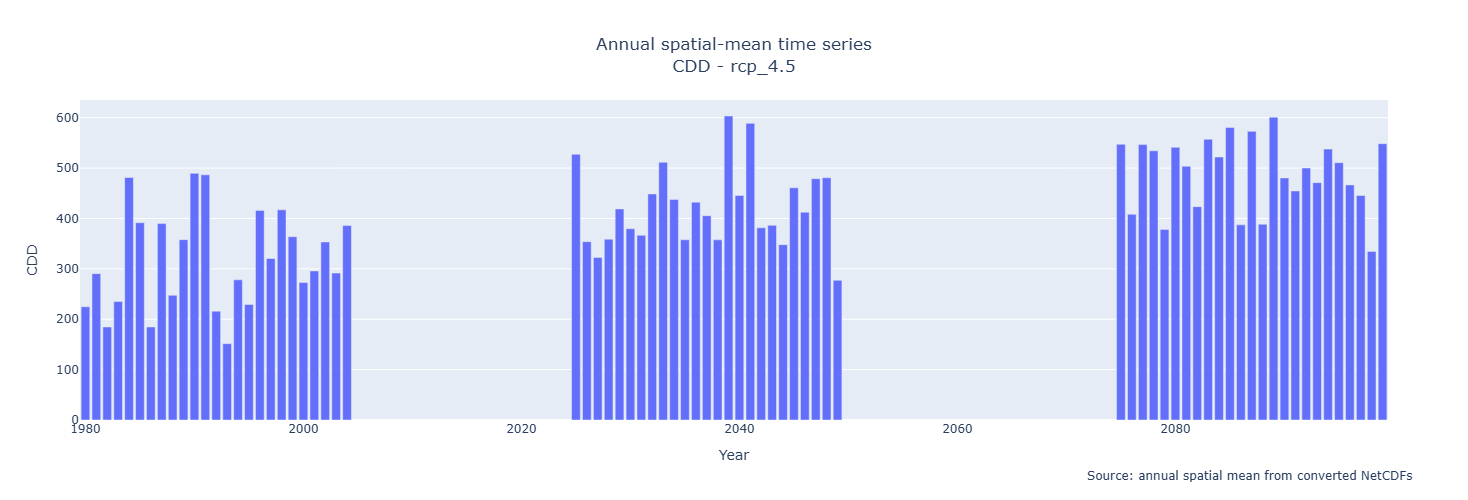

Saved: CDD_timeseries_rcp_45.png | CDD_timeseries_rcp_45.txt

--- HUMIDEX ---
Input: HUMIDEX_annual_fields_latlon_rcp_45.nc
Variable inside NetCDF: Humidex
Years: 1980 → 2099 | count: 75
NaNs: 0
Min: 20.413958
Max: 25.519896
Mean: 22.957315


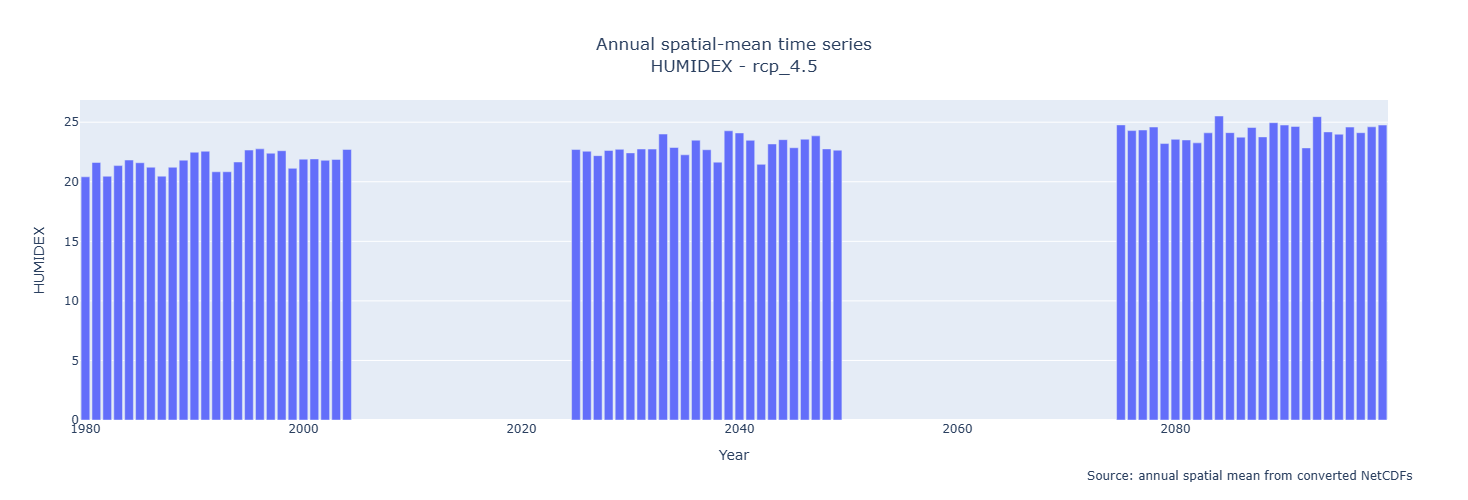

Saved: HUMIDEX_timeseries_rcp_45.png | HUMIDEX_timeseries_rcp_45.txt

--- WBGT ---
Input: WBGT_simple_annual_fields_latlon_rcp_45.nc
Variable inside NetCDF: WBGT_simple
Years: 1980 → 2099 | count: 75
NaNs: 0
Min: 19.716167
Max: 22.781523
Mean: 21.25422


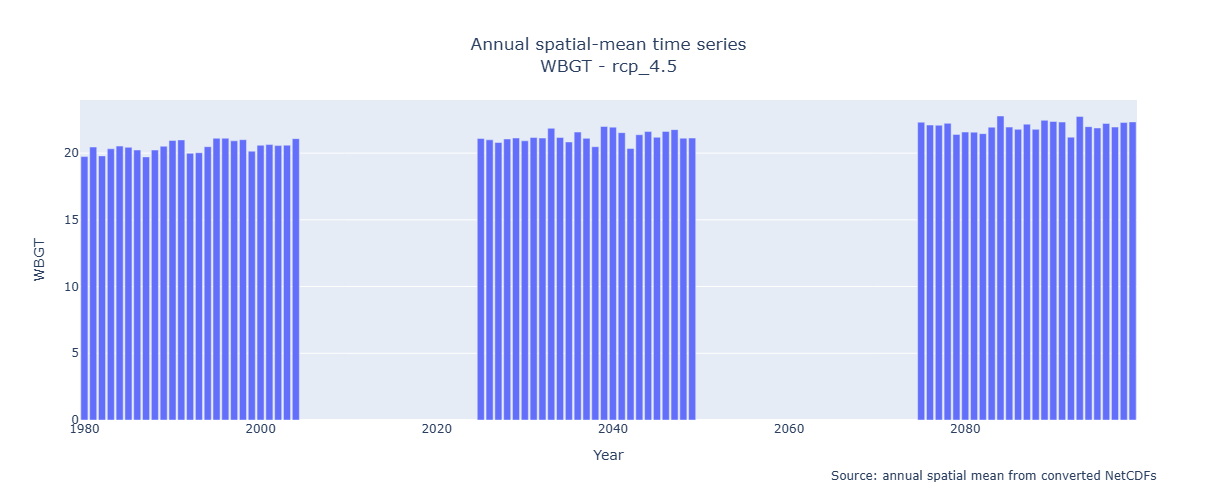

Saved: WBGT_timeseries_rcp_45.png | WBGT_timeseries_rcp_45.txt

Saved combined TXT: CDD_HUMIDEX_WBGT_timeseries_rcp_45.txt
Saved combined CSV: CDD_HUMIDEX_WBGT_timeseries_rcp_45.csv

Scenario: rcp_8.5
Input folder : output_final_merged/rcp_8.5/heatwave_output_1_3
Output folder: output_final_merged/rcp_8.5/timeseries_plots_CDD_HUMIDEX_WBGT

--- CDD ---
Input: CDD_cooling_annual_fields_latlon_rcp_85.nc
Variable inside NetCDF: CDD
Years: 1980 → 2099 | count: 75
NaNs: 0
Min: 151.41855
Max: 1056.0872
Mean: 500.3683


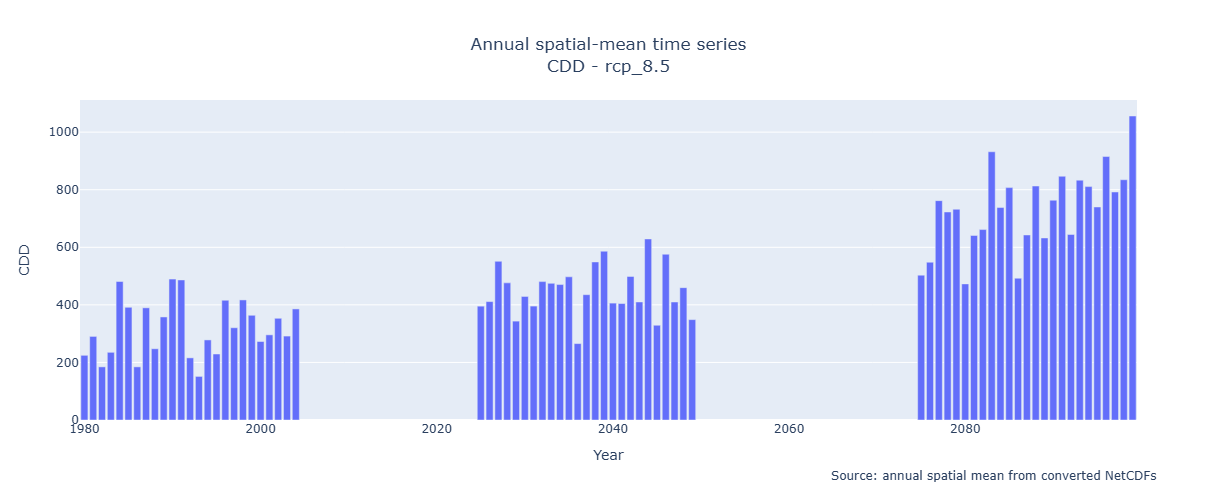

Saved: CDD_timeseries_rcp_85.png | CDD_timeseries_rcp_85.txt

--- HUMIDEX ---
Input: HUMIDEX_annual_fields_latlon_rcp_85.nc
Variable inside NetCDF: Humidex
Years: 1980 → 2099 | count: 75
NaNs: 0
Min: 20.413958
Max: 28.45006
Mean: 23.993227


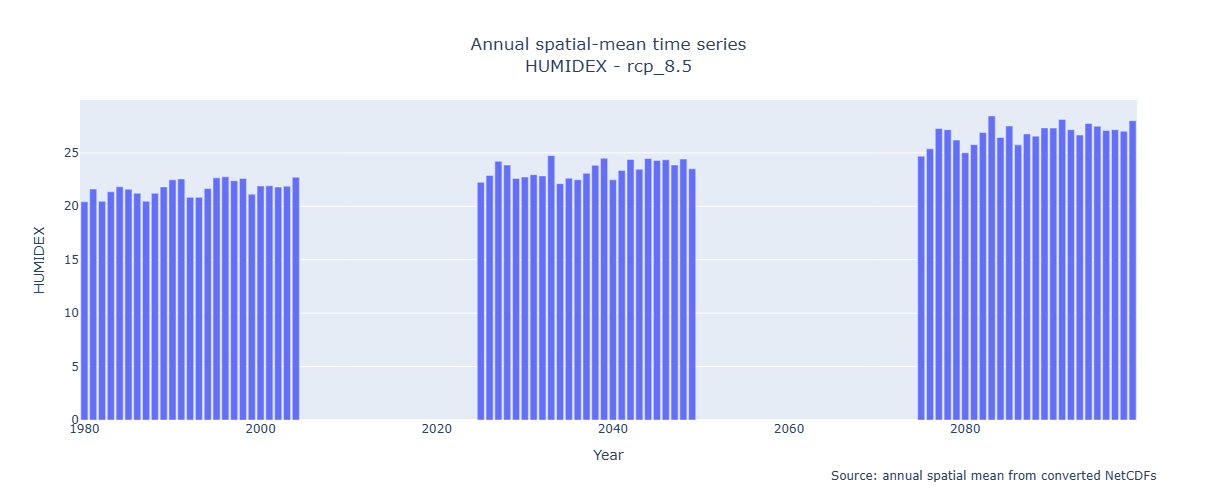

Saved: HUMIDEX_timeseries_rcp_85.png | HUMIDEX_timeseries_rcp_85.txt

--- WBGT ---
Input: WBGT_simple_annual_fields_latlon_rcp_85.nc
Variable inside NetCDF: WBGT_simple
Years: 1980 → 2099 | count: 75
NaNs: 0
Min: 19.716167
Max: 24.524248
Mean: 21.871952


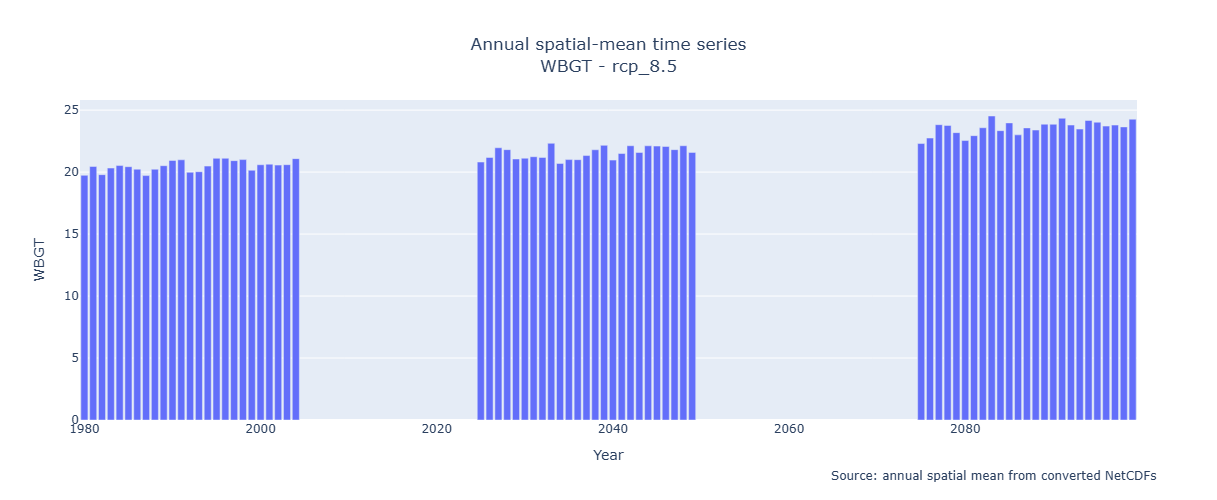

Saved: WBGT_timeseries_rcp_85.png | WBGT_timeseries_rcp_85.txt

Saved combined TXT: CDD_HUMIDEX_WBGT_timeseries_rcp_85.txt
Saved combined CSV: CDD_HUMIDEX_WBGT_timeseries_rcp_85.csv

🎉 Done.


In [33]:
from pathlib import Path
import numpy as np
import pandas as pd
import xarray as xr
import plotly.graph_objects as go
from IPython.display import display

# ============================================================
# EXTRA SCRIPT:
# Annual spatial-mean time series for:
# CDD, HUMIDEX, WBGT
#
# Run this AFTER the NetCDF conversion script
# that creates *_latlon_rcp_45.nc / *_latlon_rcp_85.nc
# ============================================================

OUT_ROOT = Path("output_final_merged")

SCENARIOS = ["rcp_4.5", "rcp_8.5"]

TARGET_SUBDIR = "heatwave_output_1_3"

PLOT_KIND = "bar"   # "bar" ή "line"

# Αν θέλεις area-weighted mean βάλε True.  [EN translation pending]
# Για να είναι ίδιο με απλό spatial mean, άστο False.  [EN translation pending]
USE_AREA_WEIGHTS = False

# ============================================================
# Files and expected variable names
# ============================================================

FILES_INFO = {
    "CDD": {
        "filename_stem": "CDD_cooling_annual_fields",
        "possible_vars": ["CDD", "CDD_cooling"]
    },
    "HUMIDEX": {
        "filename_stem": "HUMIDEX_annual_fields",
        "possible_vars": ["HUMIDEX", "Humidex", "humidex"]
    },
    "WBGT": {
        "filename_stem": "WBGT_simple_annual_fields",
        "possible_vars": ["WBGT", "WBGT_simple", "wbgt"]
    }
}


def scenario_suffix(scenario: str) -> str:
    if scenario == "rcp_4.5":
        return "rcp_45"

    if scenario == "rcp_8.5":
        return "rcp_85"

    return scenario.replace(".", "").replace("-", "_")


def find_variable(ds: xr.Dataset, possible_vars):
    """
    Βρίσκει τη μεταβλητή μέσα στο NetCDF με βάση πιθανές ονομασίες.
    Αν δεν τη βρει, εμφανίζει τις διαθέσιμες μεταβλητές.
    """

    for var in possible_vars:
        if var in ds.data_vars:
            return var

    available = list(ds.data_vars)
    raise ValueError(
        f"❌ Δεν βρέθηκε κάποια από τις μεταβλητές {possible_vars}.\n"
        f"Διαθέσιμες μεταβλητές στο αρχείο: {available}"
    )


def get_time_years(ds: xr.Dataset, da: xr.DataArray):
    """
    Παίρνει τα έτη από time ή year coordinate.
    """

    if "time" in da.dims:
        years = pd.to_datetime(ds["time"].values).year

    elif "year" in da.dims:
        years = ds["year"].values.astype(int)

    else:
        raise ValueError(
            f"❌ The variable (Η μεταβλητή) {da.name} δεν έχει ούτε time ούτε year dimension. "
            f"Dims: {da.dims}"
        )

    return years


def spatial_mean(da: xr.DataArray, use_area_weights=False):
    """
    Υπολογισμός spatial mean.

    Αν use_area_weights=False:
        απλό mean σε lat/lon ή points.

    Αν use_area_weights=True:
        weighted mean με cos(lat), όταν υπάρχουν lat/lon dims.
    """

    # Αγνόησε spatial_ref αν υπάρχει ως coordinate/auxiliary  [EN translation pending]
    da = da.squeeze(drop=True)

    if "time" in da.dims:
        time_dim = "time"
    elif "year" in da.dims:
        time_dim = "year"
    else:
        raise ValueError(
            f"❌ The variable (Η μεταβλητή) {da.name} δεν has time (έχει time)/year dimension. Dims: {da.dims}"
        )

    spatial_dims = [d for d in da.dims if d != time_dim]

    if len(spatial_dims) == 0:
        return da

    # Area-weighted mean για lat/lon grid  [EN translation pending]
    if use_area_weights and "lat" in da.dims and "lon" in da.dims:
        weights = np.cos(np.deg2rad(da["lat"]))
        mean_da = da.weighted(weights).mean(dim=("lat", "lon"), skipna=True)
    else:
        mean_da = da.mean(dim=spatial_dims, skipna=True)

    return mean_da


# ============================================================
# MAIN
# ============================================================

for scenario in SCENARIOS:

    suffix = scenario_suffix(scenario)

    in_dir = OUT_ROOT / scenario / TARGET_SUBDIR
    out_dir = OUT_ROOT / scenario / "timeseries_plots_CDD_HUMIDEX_WBGT"
    out_dir.mkdir(parents=True, exist_ok=True)

    print()
    print("=" * 80)
    print(f"Scenario: {scenario}")
    print("Input folder :", in_dir)
    print("Output folder:", out_dir)
    print("=" * 80)

    if not in_dir.exists():
        print(f"⚠️ Δεν υπάρχει ο φάκελος: {in_dir}")
        continue

    all_series = None

    for clean_name, info in FILES_INFO.items():

        filename = f"{info['filename_stem']}_latlon_{suffix}.nc"
        in_nc = in_dir / filename

        print()
        print(f"--- {clean_name} ---")
        print("Input:", in_nc.name)

        if not in_nc.exists():
            print(f"⚠️ Δεν βρέθηκε το αρχείο: {in_nc}")
            continue

        ds = xr.open_dataset(in_nc, decode_times=True)

        try:
            var_name = find_variable(ds, info["possible_vars"])
            da = ds[var_name]

            years = get_time_years(ds, da)

            mean_da = spatial_mean(da, use_area_weights=USE_AREA_WEIGHTS)
            values = mean_da.values

            # Αν για κάποιο λόγο υπάρχει επιπλέον singleton dimension  [EN translation pending]
            values = np.asarray(values).squeeze()

            if values.ndim != 1:
                raise ValueError(
                    f"❌ Το αποτέλεσμα για {clean_name} δεν είναι 1D time series. "
                    f"Shape: {values.shape}"
                )

            # Debug info
            nan_count = np.isnan(values).sum()

            print("Variable inside NetCDF:", var_name)
            print("Years:", years[0], "→", years[-1], "| count:", len(years))
            print("NaNs:", nan_count)
            print("Min:", np.nanmin(values))
            print("Max:", np.nanmax(values))
            print("Mean:", np.nanmean(values))

            # ============================================================
            # Save single TXT
            # ============================================================

            df_single = pd.DataFrame({
                "Year": years,
                clean_name: values
            })

            out_txt = out_dir / f"{clean_name}_timeseries_{suffix}.txt"
            df_single.to_csv(out_txt, sep="\t", index=False)

            # ============================================================
            # Add to combined dataframe
            # ============================================================

            if all_series is None:
                all_series = df_single.copy()
            else:
                all_series = all_series.merge(df_single, on="Year", how="outer")

            # ============================================================
            # Plot
            # ============================================================

            fig = go.Figure()

            if PLOT_KIND == "bar":
                fig.add_trace(
                    go.Bar(
                        x=years,
                        y=values,
                        name=clean_name
                    )
                )
            else:
                fig.add_trace(
                    go.Scatter(
                        x=years,
                        y=values,
                        mode="lines+markers",
                        name=clean_name
                    )
                )

            fig.update_layout(
                title={
                    "text": f"Annual spatial-mean time series<br>{clean_name} - {scenario}",
                    "x": 0.5,
                    "xanchor": "center"
                },
                xaxis_title="Year",
                yaxis_title=clean_name,
                legend=dict(orientation="h", x=0, y=1),
                width=1100,
                height=500,
            )

            fig.add_annotation(
                xref="paper",
                yref="paper",
                x=1.02,
                y=-0.2,
                showarrow=False,
                text="Source: annual spatial mean from converted NetCDFs"
            )

            display(fig)

            # ============================================================
            # Save PNG
            # Requires kaleido installed
            # pip install -U kaleido
            # ============================================================

            out_png = out_dir / f"{clean_name}_timeseries_{suffix}.png"
            fig.write_image(str(out_png), scale=2)

            print("Saved:", out_png.name, "|", out_txt.name)

        finally:
            ds.close()

    # ============================================================
    # Save combined TXT / CSV for this scenario
    # ============================================================

    if all_series is not None:

        all_series = all_series.sort_values("Year")

        out_all_txt = out_dir / f"CDD_HUMIDEX_WBGT_timeseries_{suffix}.txt"
        out_all_csv = out_dir / f"CDD_HUMIDEX_WBGT_timeseries_{suffix}.csv"

        all_series.to_csv(out_all_txt, sep="\t", index=False)
        all_series.to_csv(out_all_csv, index=False)

        print()
        print("Saved combined TXT:", out_all_txt.name)
        print("Saved combined CSV:", out_all_csv.name)

    else:
        print("⚠️ Δεν δημιουργήθηκε combined αρχείο γιατί δεν βρέθηκε κανένα time series.")

print()
print("🎉 Done.")

Historical + RCP 4.5 years: 1980 → 2099 | count: 75
Historical + RCP 8.5 years: 1980 → 2099 | count: 75
Common variables found: 3
Variable names: ['CDD', 'HUMIDEX', 'WBGT']
Saved combined TXT: CDD_HUMIDEX_WBGT_two_scenarios_all.txt
Saved combined CSV: CDD_HUMIDEX_WBGT_two_scenarios_all.csv

--- CDD ---
NaNs Historical + RCP 4.5: 0
NaNs Historical + RCP 8.5: 0


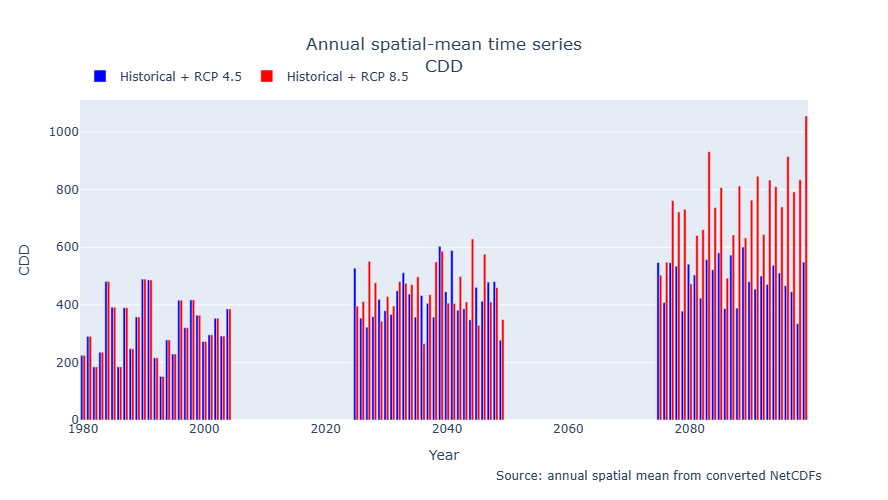

Saved: CDD_two_scenarios.png | CDD_two_scenarios.txt

--- HUMIDEX ---
NaNs Historical + RCP 4.5: 0
NaNs Historical + RCP 8.5: 0


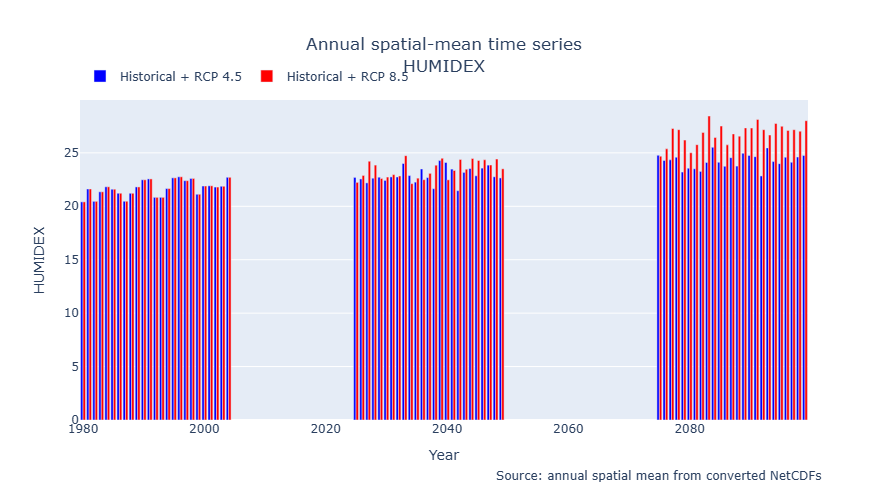

Saved: HUMIDEX_two_scenarios.png | HUMIDEX_two_scenarios.txt

--- WBGT ---
NaNs Historical + RCP 4.5: 0
NaNs Historical + RCP 8.5: 0


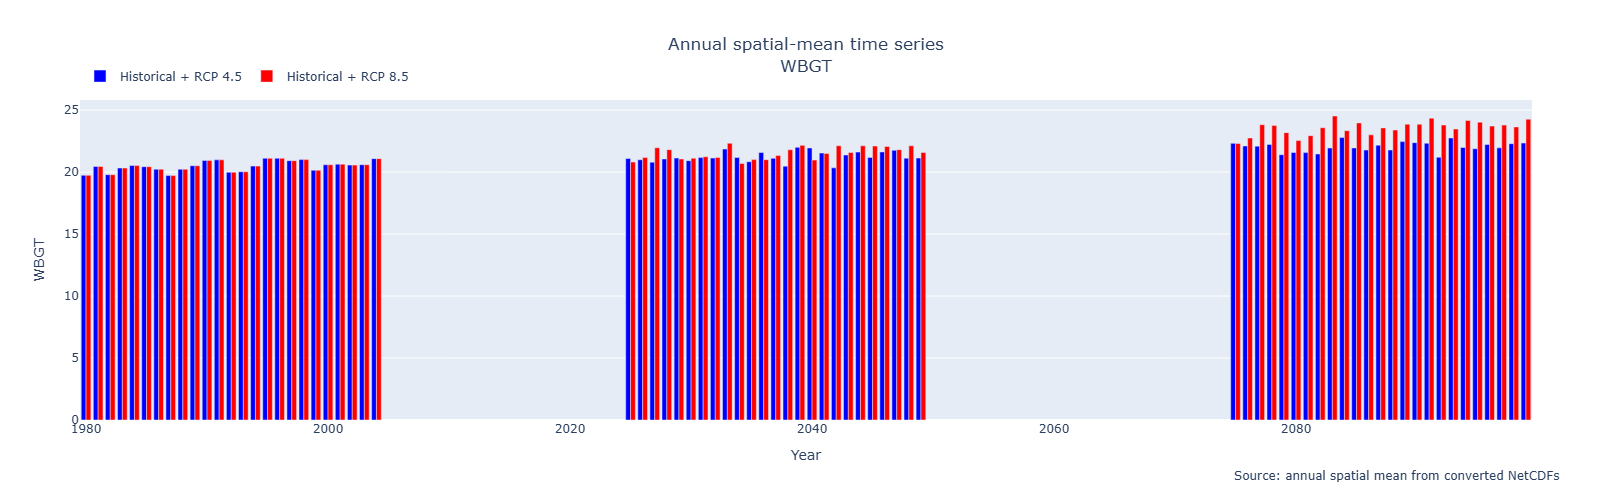

Saved: WBGT_two_scenarios.png | WBGT_two_scenarios.txt

🎉 Done.
Outputs saved in: output_final_merged/timeseries_plots_CDD_HUMIDEX_WBGT_two_scenarios_bars


In [37]:
from pathlib import Path
import pandas as pd
import numpy as np
import plotly.graph_objects as go
from IPython.display import display

# ============================================================
# Comparative BAR plots for:
# CDD, HUMIDEX, WBGT
#
# Blue  = Historical + RCP 4.5
# Red   = Historical + RCP 8.5
#
# Run this AFTER the script that creates:
# CDD_HUMIDEX_WBGT_timeseries_rcp_45.csv
# CDD_HUMIDEX_WBGT_timeseries_rcp_85.csv
# ============================================================

# =========================================
# Input / Output paths
# =========================================
OUT_ROOT = Path("output_final_merged")

BASE_DIR_45 = OUT_ROOT / "rcp_4.5" / "timeseries_plots_CDD_HUMIDEX_WBGT"
BASE_DIR_85 = OUT_ROOT / "rcp_8.5" / "timeseries_plots_CDD_HUMIDEX_WBGT"

IN_CSV_45 = BASE_DIR_45 / "CDD_HUMIDEX_WBGT_timeseries_rcp_45.csv"
IN_CSV_85 = BASE_DIR_85 / "CDD_HUMIDEX_WBGT_timeseries_rcp_85.csv"

if not IN_CSV_45.exists():
    raise FileNotFoundError(
        f"❌ Δεν βρέθηκε το {IN_CSV_45}. "
        "Τρέξε πρώτα το script που φτιάχνει τα CDD/HUMIDEX/WBGT time series για rcp_4.5."
    )

if not IN_CSV_85.exists():
    raise FileNotFoundError(
        f"❌ Δεν βρέθηκε το {IN_CSV_85}. "
        "Τρέξε πρώτα το script που φτιάχνει τα CDD/HUMIDEX/WBGT time series για rcp_8.5."
    )

OUT_DIR = OUT_ROOT / "timeseries_plots_CDD_HUMIDEX_WBGT_two_scenarios_bars"
OUT_DIR.mkdir(parents=True, exist_ok=True)

# =========================================
# Read CSV files
# =========================================
df45 = pd.read_csv(IN_CSV_45)
df85 = pd.read_csv(IN_CSV_85)

# Δέχεται είτε Year είτε year  [EN translation pending]
if "year" in df45.columns:
    df45 = df45.rename(columns={"year": "Year"})
elif "Year" not in df45.columns:
    raise ValueError("❌ Το CSV του rcp_4.5 πρέπει να έχει στήλη 'Year' ή 'year'.")

if "year" in df85.columns:
    df85 = df85.rename(columns={"year": "Year"})
elif "Year" not in df85.columns:
    raise ValueError("❌ Το CSV του rcp_8.5 πρέπει να έχει στήλη 'Year' ή 'year'.")

df45 = df45.sort_values("Year").reset_index(drop=True)
df85 = df85.sort_values("Year").reset_index(drop=True)

years45 = df45["Year"].to_numpy()
years85 = df85["Year"].to_numpy()

vars45 = [c for c in df45.columns if c != "Year"]
vars85 = [c for c in df85.columns if c != "Year"]

# Κρατάμε μόνο τις κοινές μεταβλητές  [EN translation pending]
vars_cols = sorted(list(set(vars45).intersection(set(vars85))))

if len(vars_cols) == 0:
    raise ValueError("❌ Δεν βρέθηκαν κοινές μεταβλητές ανάμεσα στα δύο CSV.")

print("Historical + RCP 4.5 years:", years45[0], "→", years45[-1], "| count:", len(years45))
print("Historical + RCP 8.5 years:", years85[0], "→", years85[-1], "| count:", len(years85))
print("Common variables found:", len(vars_cols))
print("Variable names:", vars_cols)

# =========================================
# Save one combined TXT with all variables
# =========================================
df45_all = df45.copy()
df85_all = df85.copy()

df45_all = df45_all[["Year"] + vars_cols]
df85_all = df85_all[["Year"] + vars_cols]

df45_all = df45_all.rename(
    columns={c: f"{c}_historical_rcp45" for c in vars_cols}
)

df85_all = df85_all.rename(
    columns={c: f"{c}_historical_rcp85" for c in vars_cols}
)

df_all = pd.merge(df45_all, df85_all, on="Year", how="outer")
df_all = df_all.sort_values("Year").reset_index(drop=True)

out_all_txt = OUT_DIR / "CDD_HUMIDEX_WBGT_two_scenarios_all.txt"
out_all_csv = OUT_DIR / "CDD_HUMIDEX_WBGT_two_scenarios_all.csv"

df_all.to_csv(out_all_txt, sep="\t", index=False)
df_all.to_csv(out_all_csv, index=False)

print("Saved combined TXT:", out_all_txt.name)
print("Saved combined CSV:", out_all_csv.name)

# =========================================
# Loop through CDD, HUMIDEX, WBGT
# =========================================
for col in vars_cols:

    y45 = df45[col].to_numpy()
    y85 = df85[col].to_numpy()

    # Debug info
    if np.issubdtype(y45.dtype, np.number):
        nan_count_45 = np.isnan(y45).sum()
    else:
        nan_count_45 = pd.isna(y45).sum()

    if np.issubdtype(y85.dtype, np.number):
        nan_count_85 = np.isnan(y85).sum()
    else:
        nan_count_85 = pd.isna(y85).sum()

    print(f"\n--- {col} ---")
    print("NaNs Historical + RCP 4.5:", nan_count_45)
    print("NaNs Historical + RCP 8.5:", nan_count_85)

    # =========================================
    # Create BAR plot
    # =========================================
    fig = go.Figure()

    fig.add_trace(
        go.Bar(
            x=years45,
            y=y45,
            name="Historical + RCP 4.5",
            marker_color="blue"
        )
    )

    fig.add_trace(
        go.Bar(
            x=years85,
            y=y85,
            name="Historical + RCP 8.5",
            marker_color="red"
        )
    )

    fig.update_layout(
        title={
            "text": f"Annual spatial-mean time series<br>{col}",
            "x": 0.5,
            "xanchor": "center"
        },
        xaxis_title="Year",
        yaxis_title=col,
        legend=dict(
            orientation="h",
            x=0,
            y=1.12
        ),
        barmode="group",
        width=1100,
        height=500,
    )

    fig.add_annotation(
        xref="paper",
        yref="paper",
        x=1.02,
        y=-0.2,
        showarrow=False,
        text="Source: annual spatial mean from converted NetCDFs"
    )

    # Show inside notebook
    display(fig)

    # =========================================
    # Safe filename
    # =========================================
    safe = "".join(
        ch if ch.isalnum() or ch in ("_", "-", ".") else "_"
        for ch in col
    )

    # =========================================
    # Save TXT for this variable
    # =========================================
    df_single_45 = pd.DataFrame({
        "Year": years45,
        f"{col}_historical_rcp45": y45
    })

    df_single_85 = pd.DataFrame({
        "Year": years85,
        f"{col}_historical_rcp85": y85
    })

    df_single = pd.merge(df_single_45, df_single_85, on="Year", how="outer")
    df_single = df_single.sort_values("Year").reset_index(drop=True)

    out_txt = OUT_DIR / f"{safe}_two_scenarios.txt"
    df_single.to_csv(out_txt, sep="\t", index=False)

    # =========================================
    # Save PNG for this variable
    # Requires kaleido installed
    # =========================================
    out_png = OUT_DIR / f"{safe}_two_scenarios.png"
    fig.write_image(str(out_png), scale=2)

    print("Saved:", out_png.name, "|", out_txt.name)

print("\n🎉 Done.")
print("Outputs saved in:", OUT_DIR)